# Linear Regression
As discussed in the [regression README](../README.md), regression is an approach to finding function $f(x)$, that models the conditional expectation of $Y$ given X:

$$
f(x) = E[Y|X=x]
$$

In linear regression, we assume that this function is globally linear.

A linear function can be defined as any function such that:

$$ f(ax + by) = a*f(x) + b*f(y),  \newline \forall x, y $$

Or that scalar multiplication and vector addition give you same result if the function is applied before or after.

While an affine function is any function that by adding a scalar, is linear.

$$
f(x) - c = g(x), \\ g(x) \in Linear
$$

In linear algebra form the function could be expressed as:

$$
\vec{a}\cdot\vec{x} + bias
$$

Where:

$$
a \in R^m \\
x \in R^m \\
bias \in R
$$

This bias is the scalar offset that makes it affine.

To compute an entire batch of samples one could use a matrix $\mathbf{X}$, where a row is a sample, and each column is a dimension of the sample, with an extra dimension added for the bias (always set to 1). This is equivalent to an affine function on a batch of data:

$$
\vec{y} = \mathbf{X}*\vec{b}
$$


$$
X \in R^{n,m} \\
\vec{b} \in R^m \\
\vec{y} \in R^n
$$


## Analytical Solution

Linear regression with least squares loss function has an analytical closed-form solution, unlike a lot of algorithms that rely on iterative processes.

It's derived by proving strict convexity, then calculus to find the global unique solution (because it is strictly convex).

Convexity of a function is geometrically defined as:

$$
f(\theta \cdot x_1 + (1 - \theta) \cdot x_2) <= \theta \cdot f(x_1) + (1 - \theta) \cdot f(x_2) \\ 
\forall x_1, x_2 \in R^p ; x_1 \neq x_2; 0 \lt \theta \lt 1
$$

That is the function evaluated at an interpolated point between two points is always less than or equal to their linear interpolation. Concave is the same but the sign is greater than or equal to the linear interpolation. Strict convexity is where for all points the value is always below the linear interpolation.

Consider that this is equivalent to the second derviative being positive semi-definite (positive or 0). Because in that case the slope is never decreasing, always staying the same or increasing. And when you draw the line between points thats as if the slope was same throughout the domain between them, because its increasing or staying the same the actual value is either at or below that. So they're equivalent conditions.

Secondly if we have strict convexity then if there is a global unique minima, it will be where the slope is equal to 0 since the slope only ever increases doesn't go back down, it has to be at an stationary/critical point, and that has to be the unique global minima.

So in the multivariate case the slope is the gradient and its derivative is the Hessian. For a Hessian to be considered semi definite positive (as any matrix) it's quadratic form must be positive or 0 for any nonzero vector:

$$
\vec{v}^T\mathbf{A}\vec{v} >= 0
$$

And if its strictly greater than zero its strictly convex.

So then what is linear regression with least squares loss function's second derivative to examine it's convexity and then can we find a solution to it's slope being set to 0?

$$
L_{\text{MSE}} = \frac{1}{N} \cdot (\vec{y} - X \cdot \hat{\vec{\beta}})^T \cdot (\vec{y} - X \cdot \hat{\vec{\beta}}) \\
\nabla_{\hat{\vec{\beta}}} L_{\text{MSE}} = - X^T \cdot \frac{2}{N} \cdot (\vec{y} - X \cdot \hat{\vec{\beta}}) \\
\mathbf{H}_{\vec{\beta}} L_{\text{MSE}}  =  X^T \cdot \frac{2}{N} \cdot X = \cdot \frac{2}{N} X^T \cdot X
$$

So it's a symmetric matrix, and because its the norm of a vector it's always >= 0:

$$
\vec{v}^T X^TX \vec{v} = (X \vec{v})^T \cdot (X \vec{v}) = ||X\vec{v}||^2 >= 0
$$

So we know that any gradient equal to zero is global minima.

What about a unique global minima? When is it strictly convex? When no directions are collapsed to zero, that is no linearily dependent columns!

Now we search for this gradient being equal to zero:
$$
0 = \nabla_{\hat{\vec{\beta}}} L_{\text{MSE}} = - X^T \cdot \frac{2}{N} \cdot (\vec{y} - X \cdot \hat{\vec{\beta}}) \\
=> \hat{\vec{\beta}} = (X^T X)^{-1}X^Ty
$$

Alternatively, when direct matrix inversion is computationally prohibitive (due to its cubic complexity in the number of features, O(p³)), iterative methods like (mini-)batch gradient descent are preferred (O(np) per iteration). This is where we estimate the gradient using the minibatch.

While the analytical solution, in its purest form, requires a global computation on the entire dataset, making it difficult to directly parallelize in the same way as gradient descent is and the tool ecosystem is very mature for optimizing in this way.

Assume here * refers to matrix multiplication, unless otherwise noted.


$$
Loss = (\vec{y} - \mathbf{X}\vec{b})^T(\vec{y} - \mathbf{X}\vec{b}) \\
\forall (\forall \mathbf{X}_{b} \in \mathbf{X}) \in N_{trainiter} \\
\hat{\vec{b}} = \hat{\vec{b}} + \alpha * 1/M *\nabla_{\hat{\vec{b}}} Loss \\
\hat{\vec{b}} = \hat{\vec{b}} + \alpha * 1/M * 2\mathbf{X}_b^T*(\vec{y} - \mathbf{X}_b \hat{\vec{b}})
$$

## Assumptions:
* Can have additive 0 meaned error, $ y = f(x) + \epsilon $, and uncorrelated with x ( $\epsilon \perp X$) constant variance.
* Globally linear f(x)

### Note:
This is expected to be run inside the `dev-client` service as specified in `./cluster/docker-compose.yml`. One way to do this after starting `docker-compose up -d --scale spark-worker=2 --build` in the `cluster` directory, use `Dev Containers` vscode extension to connect to the dev-client container and open the `/home/jovyan/workspace` folder where this file will be and run it there. Recommend installing version `2025.7.0` of `ms-toolsai.jupyter` in the container (had an issue with newer versions).

Be sure to run `docker-compose down` in the `./cluster/` to remove these resources after you are done.

## Example:
Lets generate some data using a linear model with additive error, and use both the gradient based and analytical model to see if we can get the original parameters.


In [32]:
import numpy as np

coefficients = np.array([0.1, 5]).T
bias = np.array([3])

noise = np.random.normal(0, 1, (1000))

input = np.random.uniform(-1.0, 1.0, (1000, 2))

output = noise + input @ coefficients + bias

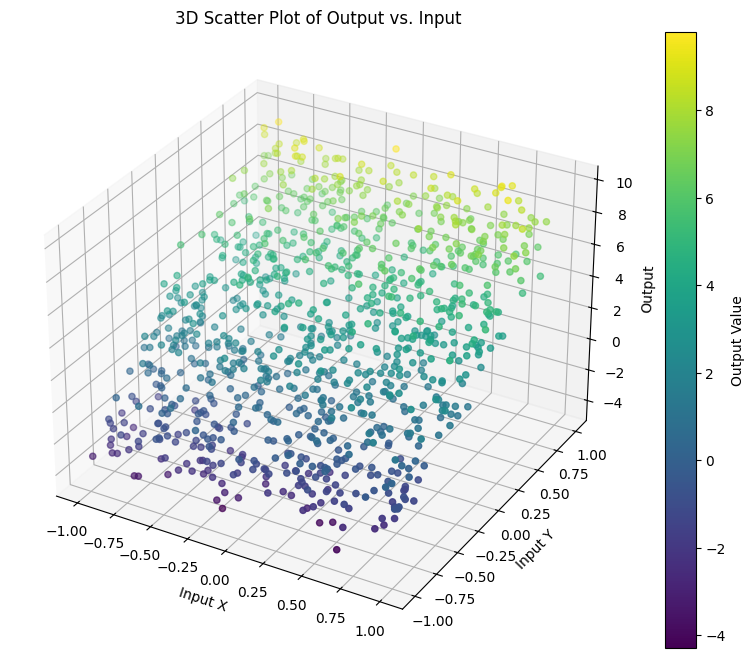

In [33]:
import matplotlib.pyplot as plt
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(input[:, 0], input[:, 1], output, c=output, cmap='viridis', marker='o')
ax.set_xlabel("Input X")
ax.set_ylabel("Input Y")
ax.set_zlabel("Output")
ax.set_title("3D Scatter Plot of Output vs. Input")
fig.colorbar(scatter, label="Output Value")
plt.show()

In [34]:
# analytical approach:
inputWithBias = np.hstack([input, np.ones((input.shape[0], 1))])
def analyticalLinearRegression(inputWithBias, output, debug=True):
    coefficientsEstimateAnalytical = np.linalg.inv(inputWithBias.T @ inputWithBias) @ inputWithBias.T @ output
    mse = np.sum((output - inputWithBias @ coefficientsEstimateAnalytical) ** 2) / output.shape[0]
    if debug:
        print(f"mse: {mse}")
    return coefficientsEstimateAnalytical
coefficientsEstimateAnalytical = analyticalLinearRegression(inputWithBias, output)
print(f"Estimated coefficients: {coefficientsEstimateAnalytical[:-1]}, true coefficients: {coefficients}")
print(f"Estimated bias: {coefficientsEstimateAnalytical[-1]}, true bias: {bias}")

mse: 0.9915121182224663
Estimated coefficients: [0.08434158 4.98070326], true coefficients: [0.1 5. ]
Estimated bias: 3.0810674977362207, true bias: [3]


In [35]:
# gradient based approach:
def gradientBasedLinearRegression(inputWithBias, output, debug=True):
    coefficientsEstimateGradient = np.random.normal(0, 1, (3))
    batchSize = 10
    learningRate = 0.01
    epochs = 10
    for epoch in range(epochs):
        for batch in range(inputWithBias.shape[0] // batchSize):
            batchInput = inputWithBias[batchSize * batch : batchSize * batch + batchSize]
            batchOutput = output[batchSize * batch : batchSize * batch + batchSize]
            coefficientsEstimateGradient += learningRate * 1 / batchInput.shape[0] * 2 * batchInput.T @ (batchOutput - batchInput @ coefficientsEstimateGradient)
        epochalMSE = np.sum((output - inputWithBias @ coefficientsEstimateGradient) ** 2) / output.shape[0]
        if debug==True:
            print(f"end epoch {epoch + 1}, mse: {epochalMSE}")
    return coefficientsEstimateGradient
coefficientsEstimateGradient = gradientBasedLinearRegression(inputWithBias, output)

end epoch 1, mse: 3.5283875708307106
end epoch 2, mse: 1.6359195038875898
end epoch 3, mse: 1.162212814855409
end epoch 4, mse: 1.0379479647611898
end epoch 5, mse: 1.0047962157663322
end epoch 6, mse: 0.9957285828562992
end epoch 7, mse: 0.9931394189793616
end epoch 8, mse: 0.9923474790374059
end epoch 9, mse: 0.9920808680783266
end epoch 10, mse: 0.9919805611644221


In [36]:
print(f"gradient coefficients + intercept: {coefficientsEstimateGradient}, and analytical{ coefficientsEstimateAnalytical}")

import statsmodels.formula.api as smf
import pandas as pd
df = pd.DataFrame(input, columns=['feature_1', 'feature_2'])
df['target_output'] = output
formula = 'target_output ~ feature_1 + feature_2'
model_formula = smf.ols(formula=formula, data=df)
results_formula = model_formula.fit()
print("\n--- Statsmodels OLS Results---")
print(results_formula.params)

gradient coefficients + intercept: [0.0842743  4.95778605 3.09783463], and analytical[0.08434158 4.98070326 3.0810675 ]

--- Statsmodels OLS Results---
Intercept    3.081067
feature_1    0.084342
feature_2    4.980703
dtype: float64


This shows they get to approximately the same place.

## Two Goals
When fitting supervised models, there are two often competing goals: maximization of generalization performance and interpretability of the data.

When maximizing generalization performance, we estimate the out-of-sample error and search for the best bias-variance tradeoff that minimizes this estimate.

When aiming for interpretability, we verify whether our underlying assumptions hold and then apply statistical inference based on those validated assumptions to quantify associations between the label and features.

### For interpretability
When your goal is to interpret the model, building a model is a two-phase process: first validating the assumptions needed for specific statistical statements, and then tuning the model to speak with precision.

#### Unbiased Point Estimates - Validity of the Linear Functional Form and Zero Conditional Mean Noise

In order to have unbiased point estimates (that is, $\mathbb{E}[\hat{\beta} \mid X] = \beta$), the linear functional form must be valid ($y = X\beta + \epsilon$) and the conditional expectation of the additive noise at any given $X$ must be $0$ ($\mathbb{E}[\epsilon \mid X] = 0$):

$$
\mathbb{E}[\hat{\beta} \mid X] = \mathbb{E}[(X^TX)^{-1}X^Ty \mid X] = (X^TX)^{-1}X^T\mathbb{E}[X\beta + \epsilon \mid X] = (X^TX)^{-1}X^TX\beta + (X^TX)^{-1}X^T\mathbb{E}[\epsilon \mid X] = \beta + 0 = \beta
$$

To see whether the linear functional form and zero-conditional-mean assumption hold, fit a model and inspect the residuals across the domain of your predictions ($\hat{y}$) and features ($X$)—they should remain flat and centered around $0$ across the entire domain, with no systematic bends or curves.

If the relationship shows a monotonic curve driven by multiplicative scaling (i.e., instead of an additive model $y = X\beta + \epsilon$, it's multiplicative like $y = e^{X\beta} \cdot \epsilon$), transforming the target via $\log(Y)$ or $\sqrt{Y}$ can linearize the relationship and convert the multiplicative error into additive noise. However, if the residual pattern reveals a non-monotonic functional shape (such as a symmetric quadratic bend), target transformations will fail—the only option is careful **basis expansion**, such as adding non-interaction polynomial terms (taking care to ensure interpretability is preserved).

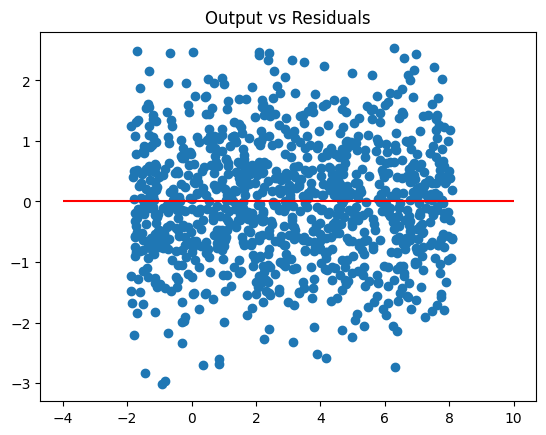

In [37]:
residuals = output - (inputWithBias @ coefficientsEstimateGradient)
plt.scatter((inputWithBias @ coefficientsEstimateGradient), residuals)
plt.hlines(0, -4, 10, colors="red")
plt.title("Output vs Residuals");

Let's so a non linear example.

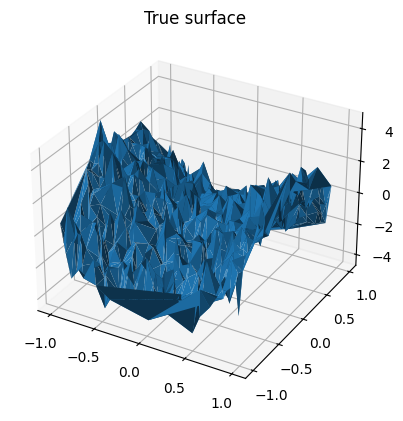

In [38]:
data = np.concat([np.random.uniform(-1, 1, size=(1000, 2)), np.ones(shape=(1000,1))], axis=-1)
transformed = (data * data) * np.array([3,-4, .5], dtype=float).reshape(1, -1) + np.random.normal(0, .2, (1000, 1))
label = np.sum(transformed, axis=-1)
fig = plt.figure()
ax = fig.add_subplot(projection="3d")
tri_surf = ax.plot_trisurf(data[:, 0], data[:, 1], label)
plt.title("True surface")
plt.show()

In [39]:
# solve
ls_coefficients = np.linalg.inv(data.T @ data) @ data.T @ label

In [40]:
np.mean((data @ ls_coefficients - label)**2)

np.float64(2.5405959683955035)

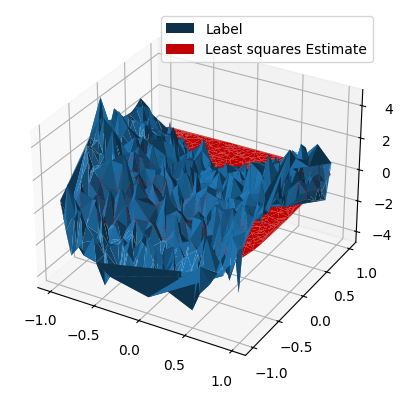

In [41]:
fig = plt.figure()
ax = fig.add_subplot(projection="3d")
ax.plot_trisurf(data[:, 0], data[:, 1], label, label="Label")
ax.plot_trisurf(data[:, 0], data[:, 1], data @ ls_coefficients, color="r", label="Least squares Estimate")
plt.legend()
plt.show()

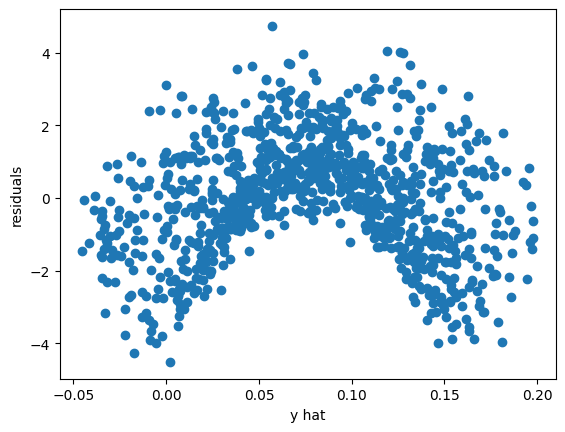

In [42]:
residuals = (label - data @ ls_coefficients)

plt.scatter(data @ ls_coefficients, residuals)
plt.xlabel("y hat")
plt.ylabel("residuals")
plt.show()

As we can see here our estimate versus residuals shows a curved structured violating the 0 centered noise assumption and we can look at which feature vs residual is causing it:

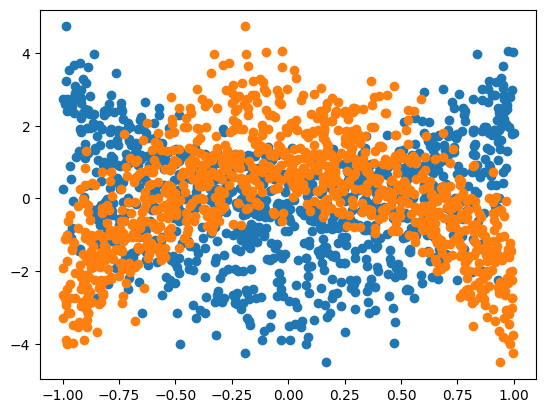

In [43]:
plt.scatter(data[:, 0], residuals)
plt.scatter(data[:, 1], residuals)
plt.show()

So we see that both features may be better modeled as quadratic - so we can move to that basis assuming we have a clear domain originated interpertation of it (in this case we do since we know it was quadratic data that generated this). 

MSE squared data: -4.4408920985006264e-17


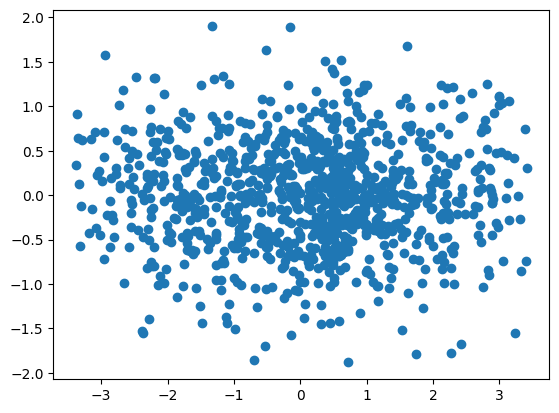

In [44]:
squared_data = data * data
ls_sd_est = np.linalg.inv(squared_data.T @ squared_data) @ squared_data.T @ label

res_sd = (squared_data @ ls_sd_est - label)

print(f"MSE squared data: {res_sd.mean()}")

plt.scatter(squared_data @ ls_sd_est, res_sd)
plt.show()

With this transformation our eassumption of 0 meaned noise and functional linear form (in this new basis) hold and our coefficients remain interpretable, though now as the marginal effect per unit of $x_j^2$ rather than $x_j$. However, as transformations grow more complex (high-degree polynomials or interactions), we quickly trade away intuitive interpretability for functional flexibility.

If this holds, we can interpret the point estimates ($\hat{\beta}$) directly:

* **Continuous Covariates:** Holding all other included covariates constant, a 1-unit increase in $X_j$ is associated with a $\hat{\beta}_j$ change in the expected response $E[Y|X]$.
* **Standardized Covariates:** If $X_j$ is standardized (zero mean, unit variance), $\hat{\beta}_j$ represents the expected change in $Y$ for a **1-standard-deviation** increase in $X_j$, holding everything else constant.
* **Dummy-Encoded Categoricals:** For a categorical variable with $k$ levels encoded into $k-1$ binary dummies, each coefficient represents the average difference in the response compared to the omitted baseline category, holding all other variables constant.
* **The Intercept ($\hat{\beta}_0$):** The expected response when all continuous covariates are zero and all categorical variables are at their baseline levels. (Note: if $X=0$ is outside the realistic domain of the data, the intercept is purely a mathematical anchor rather than a meaningful physical quantity).


In [45]:
ls_sd_est

array([ 2.97858509, -3.98686916,  0.4893885 ])

As we can see are close to the data generating coefficients.

#### Coefficient Confidence Intervals
Point estimates alone don't tell us how much our coefficients might wiggle from sample to sample. To move from simple point descriptions to **inferential statements**—such as standard errors, $p$-values, and confidence intervals for $\beta$—we layer on assumptions about the **variance and covariance** of the noise:

**Constant Variance (Homoscedasticity) & Uncorrelated Errors ($\text{Var}[\epsilon \mid X] = \sigma^2 I$):**
In matrix form, both conditions are captured by $\text{Var}[\epsilon \mid X] = \sigma^2 I$. Because $y = X\beta + \epsilon$ (where $X\beta$ is constant given $X$), $\text{Var}[y \mid X] = \text{Var}[\epsilon \mid X] = \sigma^2 I$. Applying the matrix variance property $\text{Var}[Ay] = A\,\text{Var}[y]\,A^T$:
$$
\text{Var}[\hat{\beta} \mid X] = \text{Var}[(X^TX)^{-1}X^Ty \mid X] = (X^TX)^{-1}X^T \underbrace{\text{Var}[y \mid X]}_{\sigma^2 I} X(X^TX)^{-1} = \sigma^2 (X^TX)^{-1}
$$

* **Uncorrelated errors** ($\text{Cov}(\epsilon_i, \epsilon_j \mid X) = 0$ for $i \neq j$) mean the off-diagonal elements of $\Omega = \text{Var}[\epsilon \mid X]$ are zero—row $i$'s error tells us nothing about row $j$'s error. Because we only observe a single residual vector $e = (e_1, \dots, e_n)^T$ (one realization per row, where plugging an unconstrained $\hat{\Omega} = ee^T$ into the variance formula collapses to $X^T(ee^T)X = (X^Te)(e^TX) = 0$), we cannot estimate arbitrary pairwise covariances $\Omega_{ij}$. Instead, we must pool residuals across a known **ordering** (time/space lags) or **grouping** (clusters):
  * **Diagnostic:** Plot **Residuals vs. Time/Order ($e_t$ vs. $t$)** to check for "snaking" streaks (serial correlation), or plot **Residuals by Cluster** (boxplots) to check if whole groups sit systematically above or below $0$.
  * **Fixes:** Add the missing time trend, lagged variables, or cluster fixed-effect dummy variables into X so the shared variation is explicitly modeled rather than left in ϵ. Or keep $\hat{\beta}$ untouched and use an off-diagonal **Sandwich Estimator** $(X^TX)^{-1} (X^T \hat{\Omega} X) (X^TX)^{-1}$ that zeros out unrelated pairs and sums $e_i e_j x_i x_j^T$ only within clusters (**Cluster-Robust SEs**) or up to lag $L$ (**Newey-West SEs**):
    $$\widehat{\text{Cov}}_{\text{Cluster}}(\hat{\beta} \mid X) = (X^TX)^{-1} \left( \sum_{g=1}^G X_g^T (e_g e_g^T) X_g \right) (X^TX)^{-1}$$

* **Homoscedasticity** means the diagonal elements—the conditional variance of each single error given $X$—are a constant $\sigma^2$.
  * **Diagnostic:** Inspect the **$\hat{y}$ vs. Residuals ($e$)** and **Feature $X_j$ vs. Residuals ($e$)** plots again—this time looking at the *vertical spread* rather than the center. The spread should form a uniform horizontal band rather than a widening megaphone/funnel.
  * **Mathematical Check (Breusch-Pagan Intuition):** Regress the squared residuals $e^2$ on $X$. Because $\text{Var}[\epsilon_i \mid x_i] = \mathbb{E}[\epsilon_i^2 \mid x_i]$, the $R^2$ of this auxiliary regression should be near $0$.
  * **Fixes:** Apply a variance-stabilizing transform ($\log(Y)$ or $\sqrt{Y}$) if noise scales with $Y$, or keep $\hat{\beta}$ untouched and compute **Huber-White ("Sandwich") Robust Standard Errors**:
    $$\widehat{\text{Cov}}_{\text{HC}}(\hat{\beta} \mid X) = (X^TX)^{-1} X^T \, \text{diag}(e_1^2, \dots, e_n^2) \, X (X^TX)^{-1}$$
    and as a last option careful basis expansion.


**Gaussian Noise ($\epsilon \sim \mathcal{N}(0, \sigma^2)$) vs. Central Limit Theorem:**
  * **Exact Finite-Sample Inference:** If the noise is strictly Gaussian, then because $\hat{\beta}$ is a linear combination of normal errors, $\hat{\beta}$ is *exactly* normally distributed for any sample size $N$:
    $$\hat{\beta} \sim \mathcal{N}\left(\beta, \sigma^2 (X^TX)^{-1}\right)$$
    When we estimate $\sigma^2$ from the residuals, our standardized coefficients follow an exact Student's $t$-distribution.
  * **Large-Sample (Asymptotic) Inference:** If the noise is zero-meaned with constant variance, but *not* Gaussian, the **Central Limit Theorem** guarantees that $\hat{\beta}$ still converges to that same Normal distribution as $N$ grows large. While $N > 30$ is the classic textbook baseline for a single variable, in multiple regression the degrees of freedom scale with the number of parameters $p$. A good practical rule of thumb is **$N \ge 15p\text{–}20p$** (15 to 20 observations per feature) for reasonably symmetric residuals, scaling up to **$N \ge 50p$** if the residuals are heavily skewed—ensuring no single high-leverage point or sparse binary feature dominates the estimate.
  * **Diagnostic** If the size is smaller than the rules of thumb for CLT estimate normality to apply, you can plot the residuals to see their shape. For a fix you can try a transform if noise scales with $Y$, and as a last option careful basis expansion.

**What it buys us:** By the **Gauss-Markov Theorem**, OLS is now the **BLUE** (Best Linear Unbiased Estimator)—meaning it has the lowest variance among all unbiased linear estimators. Combined with the Central Limit Theorem (which makes $\hat{\beta}$ asymptotically normal in large samples), this allows us to compute valid standard errors from the diagonal of $\hat{\sigma}^2 (X^TX)^{-1}$ to build confidence intervals:
  $$\hat{\beta}_j \pm t_{\alpha/2, \, n-p} \sqrt{\hat{\sigma}^2 \left[(X^TX)^{-1}\right]_{jj}}, \quad \text{where } \hat{\sigma}^2 = \frac{1}{n-p}\sum_{i=1}^n (y_i - \hat{y}_i)^2$$
- *(If this fails, $\hat{\beta}$ is still unbiased on average, but our standard errors, confidence intervals, and $p$-values will be wrong!)*

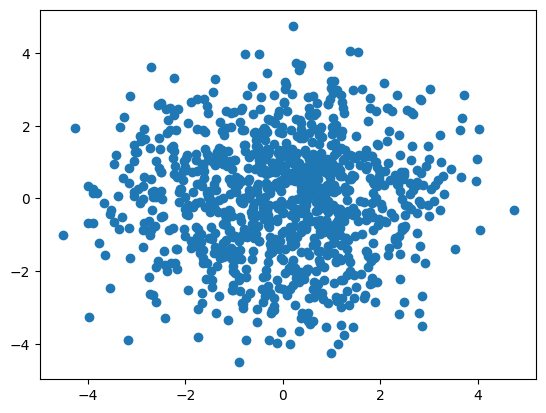

In [46]:
### uncorrelated feautres
plt.scatter(residuals[:-1], residuals[1:])

Shows no time dependency on residuals.

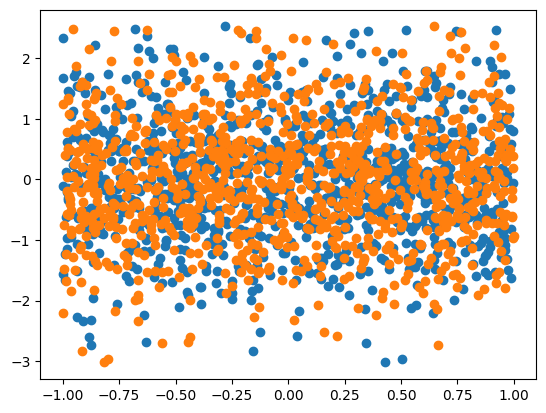

In [47]:
### Homoscedasticity
residuals = output - (inputWithBias @ coefficientsEstimateGradient)
plt.scatter(inputWithBias[:, 0], residuals)
plt.scatter(inputWithBias[:, 1], residuals)

Variance looks good here and N > 1k, for 3 features we can take advantage of normality CLT offers us.

True Slope = 2.500
Naive OLS Slope: 2.577 (SE: 0.085) -> Correlated cluster noise inflates residual variance!
Fixed OLS Slope: 2.492 (SE: 0.024) -> Restores BLUE & collapses SE!


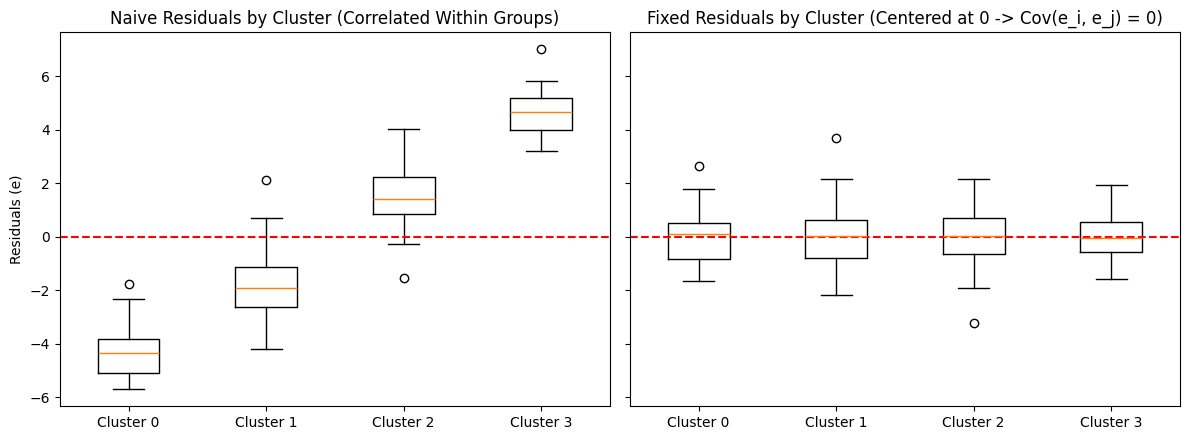

In [48]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# 1. Generate synthetic clustered data (4 clusters, 50 observations each)
n_clusters = 4
n_per_cluster = 50
n = n_clusters * n_per_cluster

cluster_ids = np.repeat(np.arange(n_clusters), n_per_cluster)
true_cluster_offsets = np.array([-4.0, -1.5, 2.0, 5.0])  # Unmodeled group baselines

# Feature x is independent of cluster (so beta_1 stays unbiased, but errors are correlated within clusters)
x = np.random.uniform(0, 10, n)
eps = np.random.normal(0, 1.0, n)
y = 2.5 * x + true_cluster_offsets[cluster_ids] + eps

# 2. Naive OLS Fit (Ignoring Clusters)
X_naive = np.column_stack([x, np.ones(n)])
beta_naive = np.linalg.inv(X_naive.T @ X_naive) @ X_naive.T @ y
res_naive = y - X_naive @ beta_naive
se_naive = np.sqrt(np.diag(((res_naive.T @ res_naive) / (n - X_naive.shape[1])) * np.linalg.inv(X_naive.T @ X_naive)))

# 3. Structural Fix: Absorb clusters into X via Group Indicator Columns (Fixed Effects)
# Create one-hot encoding for clusters (dropping cluster 0 to avoid collinearity with the intercept)
cluster_dummies = np.eye(n_clusters)[cluster_ids][:, 1:]
X_fixed = np.column_stack([x, np.ones(n), cluster_dummies])

beta_fixed = np.linalg.inv(X_fixed.T @ X_fixed) @ X_fixed.T @ y
res_fixed = y - X_fixed @ beta_fixed
se_fixed = np.sqrt(np.diag(((res_fixed.T @ res_fixed) / (n - X_fixed.shape[1])) * np.linalg.inv(X_fixed.T @ X_fixed)))

print(f"True Slope = 2.500")
print(f"Naive OLS Slope: {beta_naive[0]:.3f} (SE: {se_naive[0]:.3f}) -> Correlated cluster noise inflates residual variance!")
print(f"Fixed OLS Slope: {beta_fixed[0]:.3f} (SE: {se_fixed[0]:.3f}) -> Restores BLUE & collapses SE!")

# 4. Diagnostic Plot: Residuals Grouped by Cluster Before vs. After Fix
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

# Group residuals by cluster for boxplot
grouped_res_naive = [res_naive[cluster_ids == c] for c in range(n_clusters)]
grouped_res_fixed = [res_fixed[cluster_ids == c] for c in range(n_clusters)]

axes[0].boxplot(grouped_res_naive, tick_labels=[f"Cluster {c}" for c in range(n_clusters)])
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Naive Residuals by Cluster (Correlated Within Groups)")
axes[0].set_ylabel("Residuals (e)")

axes[1].boxplot(grouped_res_fixed, tick_labels=[f"Cluster {c}" for c in range(n_clusters)])
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Fixed Residuals by Cluster (Centered at 0 -> Cov(e_i, e_j) = 0)")

plt.tight_layout()
plt.show()

Naive Slope on x_t: 2.013 (SE: 0.039) -> Biased & bloated due to hidden time dynamics!
Fixed Dynamic Model Slopes (x_t, x_{t-1}, y_{t-1}):
  x_t coefficient:     2.027 (SE: 0.019)
  x_{t-1} coefficient: -1.464 (SE: 0.061)
  y_{t-1} coefficient: 0.576 (SE: 0.029) -> Absorbs temporal memory!
Naive Lag-1 Corr: 0.653  |  Fixed Lag-1 Corr: 0.029 (White noise restored)


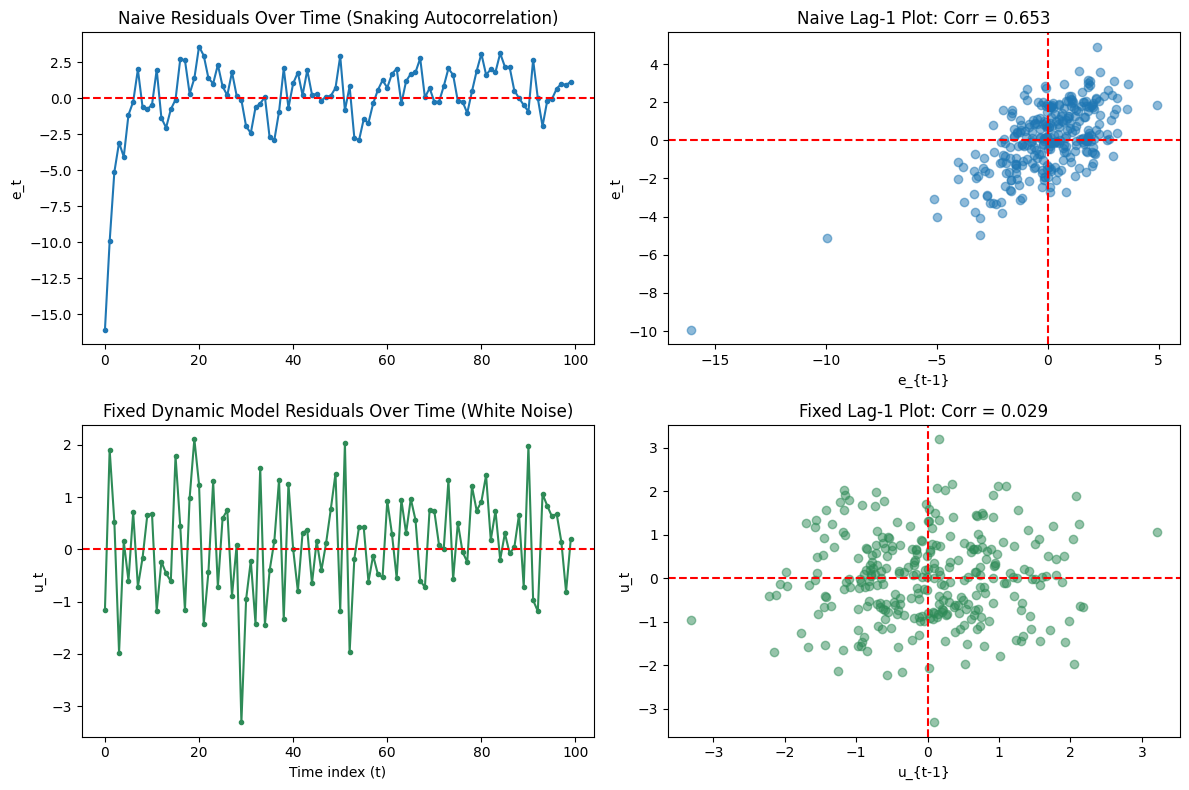

In [49]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# 1. Generate sequential data where the true process includes memory (autoregressive dynamics)
# True process: y_t = 0.6 * y_{t-1} + 2.0 * x_t - 1.5 * x_{t-1} + 5.0 + u_t
n = 300
x = np.random.uniform(0, 10, n)
u = np.random.normal(0, 1.0, n)

y = np.zeros(n)
for t in range(1, n):
    y[t] = 0.6 * y[t-1] + 2.0 * x[t] - 1.5 * x[t-1] + 5.0 + u[t]

# 2. Naive OLS Fit (Ignoring time dynamics / leaving y_{t-1} out of X)
X_naive = np.column_stack([x, np.ones(n)])
beta_naive = np.linalg.inv(X_naive.T @ X_naive) @ X_naive.T @ y
res_naive = y - X_naive @ beta_naive
lag1_corr_naive = np.corrcoef(res_naive[:-1], res_naive[1:])[0, 1]

# 3. Structural Fix: Adding Lagged Features (y_{t-1} and x_{t-1}) directly to X
# We align arrays starting from index 1 so all rows match length (n - 1)
y_current = y[1:]
y_lagged = y[:-1]
x_current = x[1:]
x_lagged = x[:-1]

X_fixed = np.column_stack([x_current, x_lagged, y_lagged, np.ones(n - 1)])
beta_fixed = np.linalg.inv(X_fixed.T @ X_fixed) @ X_fixed.T @ y_current
res_fixed = y_current - X_fixed @ beta_fixed
lag1_corr_fixed = np.corrcoef(res_fixed[:-1], res_fixed[1:])[0, 1]

# Compute Standard Errors for comparison
se_naive = np.sqrt(np.diag(((res_naive.T @ res_naive) / (n - X_naive.shape[1])) * np.linalg.inv(X_naive.T @ X_naive)))
se_fixed = np.sqrt(np.diag(((res_fixed.T @ res_fixed) / (n - X_fixed.shape[1])) * np.linalg.inv(X_fixed.T @ X_fixed)))

print(f"Naive Slope on x_t: {beta_naive[0]:.3f} (SE: {se_naive[0]:.3f}) -> Biased & bloated due to hidden time dynamics!")
print(f"Fixed Dynamic Model Slopes (x_t, x_{{t-1}}, y_{{t-1}}):")
print(f"  x_t coefficient:     {beta_fixed[0]:.3f} (SE: {se_fixed[0]:.3f})")
print(f"  x_{{t-1}} coefficient: {beta_fixed[1]:.3f} (SE: {se_fixed[1]:.3f})")
print(f"  y_{{t-1}} coefficient: {beta_fixed[2]:.3f} (SE: {se_fixed[2]:.3f}) -> Absorbs temporal memory!")
print(f"Naive Lag-1 Corr: {lag1_corr_naive:.3f}  |  Fixed Lag-1 Corr: {lag1_corr_fixed:.3f} (White noise restored)")

# 4. Diagnostic Plots: Residual Trace & Lag-1 Scatter Before vs. After
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Row 1: Naive Residuals (Snaking autocorrelation over time + linear tilt in lag plot)
axes[0, 0].plot(res_naive[:100], marker='o', markersize=3, linestyle='-')
axes[0, 0].axhline(0, color='red', linestyle='--')
axes[0, 0].set_title("Naive Residuals Over Time (Snaking Autocorrelation)")
axes[0, 0].set_ylabel("e_t")

axes[0, 1].scatter(res_naive[:-1], res_naive[1:], alpha=0.5)
axes[0, 1].axhline(0, color='red', linestyle='--')
axes[0, 1].axvline(0, color='red', linestyle='--')
axes[0, 1].set_title(f"Naive Lag-1 Plot: Corr = {lag1_corr_naive:.3f}")
axes[0, 1].set_xlabel("e_{t-1}")
axes[0, 1].set_ylabel("e_t")

# Row 2: Fixed Residuals (Pure white noise over time + spherical scatter in lag plot)
axes[1, 0].plot(res_fixed[:100], marker='o', markersize=3, linestyle='-', color='seagreen')
axes[1, 0].axhline(0, color='red', linestyle='--')
axes[1, 0].set_title("Fixed Dynamic Model Residuals Over Time (White Noise)")
axes[1, 0].set_xlabel("Time index (t)")
axes[1, 0].set_ylabel("u_t")

axes[1, 1].scatter(res_fixed[:-1], res_fixed[1:], alpha=0.5, color='seagreen')
axes[1, 1].axhline(0, color='red', linestyle='--')
axes[1, 1].axvline(0, color='red', linestyle='--')
axes[1, 1].set_title(f"Fixed Lag-1 Plot: Corr = {lag1_corr_fixed:.3f}")
axes[1, 1].set_xlabel("u_{t-1}")
axes[1, 1].set_ylabel("u_t")

plt.tight_layout()
plt.show()

Now that we have verified that our data satisfies the Gauss–Markov assumptions (along with either Gaussian errors or a sufficient sample size $n$ for the Central Limit Theorem), we can use the estimated sampling variance of our estimators to conduct formal statistical inference.

For an individual coefficient, significance testing uses the standard error to compute a $t$-statistic:
$$t_j = \frac{\hat{\beta}_j}{\text{SE}(\hat{\beta}_j)}$$
This yields a $p$-value—the probability of observing an estimate at least as extreme as ours if the true coefficient were zero ($\beta_j = 0$). For joint hypotheses involving multiple coefficients simultaneously, we use the multidimensional equivalent: the **$F$-test** (note that for a single variable where $q = 1$, the $F$-statistic is identically the square of its $t$-statistic, $F = t^2$).

#### The General $F$-Statistic Test (Comparing Nested Models)

Let's consider two nested linear models on $n$ observations:

- **Reduced Model (Model 0):** Contains $p_0$ predictors (excluding the intercept) with residual sum of squares $RSS_0$.
- **Full Model (Model 1):** Contains all predictors from the reduced model plus an additional $q$ predictors ($p_1 = p_0 + q$ predictors, excluding the intercept) with residual sum of squares $RSS_1$.

The hypotheses are:
- $\mathcal{H}_0: \beta_{p_0+1} = \beta_{p_0+2} = \dots = \beta_{p_1} = 0$ (the additional $q$ predictors have zero conditional association with the response).
- $\mathcal{H}_1$: At least one of the additional $q$ predictors has a non-zero coefficient.

The $F$-statistic is calculated as:

$$F = \frac{(RSS_0 - RSS_1) / q}{RSS_1 / (n - p_1 - 1)}$$

Where:
- $RSS_0 - RSS_1$ is the drop in residual sum of squares from adding the $q$ predictors (or the increase in error from dropping them).
- $q = p_1 - p_0$ is the numerator degrees of freedom (the number of added/dropped variables).
- $n - p_1 - 1$ is the denominator degrees of freedom (residual degrees of freedom in the full model, accounting for $p_1$ slopes plus $1$ intercept).

#### Formal Definition and Intuition

Mathematically, an **$F$-distribution** is the ratio of two independent chi-squared ($\chi^2$) random variables, each divided by its respective degrees of freedom—giving a ratio of two **average $\chi^2$ per degree of freedom** measures:

$$F = \frac{\chi^2(d_1) / d_1}{\chi^2(d_2) / d_2}$$

Because a $\chi^2(k)$ variable is a sum of $k$ squared independent standard normals ($\sum_{i=1}^k Z_i^2$), dividing by $k$ computes an average squared magnitude per dimension. Under normal errors ($\epsilon_i \sim \mathcal{N}(0, \sigma^2)$), dividing our sums of squared residuals by the true error variance $\sigma^2$ standardizes both the numerator and denominator into exact $\chi^2$-per-DoF averages, where the unknown $\sigma^2$ cancels out cleanly:

$$F = \frac{\frac{(RSS_0 - RSS_1) / q}{\sigma^2}}{\frac{RSS_1 / (n - p_1 - 1)}{\sigma^2}} = \frac{\chi^2(q) / q}{\chi^2(n - p_1 - 1) / (n - p_1 - 1)} \sim F(q, \, n - p_1 - 1)$$

In regression, the two parts of the fraction measure squared error per degree of freedom in two different orthogonal subspaces:

1. **The Bottom ($RSS_1 / (n - p_1 - 1)$ — Baseline Noise per Residual DoF):**
   Measures how much leftover squared error sits in each remaining degree of freedom of the full model. Because $n - p_1 - 1$ is dominated by sample size $n$, this establishes our unbiased baseline noise variance estimate ($\hat{\sigma}^2$).
2. **The Top ($(RSS_0 - RSS_1) / q$ — Drop in $RSS$ per Added Variable):**
   Measures how much squared error disappeared *per variable* when adding those $q$ predictors. Because OLS projects onto whatever vectors you give it, adding even pure-noise variables mechanically reduces $RSS$ by $\sigma^2$ per variable on average.
3. **The Comparison (Signal vs. Noise):**
   - **Under $\mathcal{H}_0$ (Just Noise):** If the $q$ variables are pure noise, each one absorbs only the baseline amount of random error ($\sigma^2$) by chance. The top average ($(RSS_0 - RSS_1) / q$) matches the bottom average ($RSS_1 / (n - p_1 - 1)$), so $F \approx \frac{\sigma^2}{\sigma^2} \approx 1$.
   - **Under $\mathcal{H}_1$ (Real Signal):** If the variables genuinely explain the response, the reduction in $RSS$ per variable will exceed the baseline noise variance, driving the top average well above the bottom average ($F \gg 1$).

In short, every added degree of freedom mechanically lowers $RSS$ by roughly $\sigma^2$ even when irrelevant (pure noise fitting). Only when the reduction per variable significantly exceeds that $\sigma^2$ baseline do we have genuine signal—which is exactly what the $F$-statistic quantifies.

#### Special Case: Connection to the $t$-Statistic ($q = 1$)

When testing a **single** predictor ($q = 1$), the nested $F$-test and the two-sided $t$-test on that predictor's coefficient are mathematically identical:

$$F = t^2 \quad \text{and} \quad F(1, n - p_1 - 1) \equiv [t(n - p_1 - 1)]^2$$

**1. What is a $t$-distribution?**
If we knew the true error variance $\sigma^2$, standardizing a coefficient estimate $\hat{\beta}_j$ would yield a standard normal variable ($Z \sim \mathcal{N}(0,1)$). Because we must estimate $\sigma^2$ using our sample residuals ($\hat{\sigma}^2 = \frac{RSS_1}{n - p_1 - 1}$, which is a scaled $\chi^2$ variable), dividing by the estimated standard error introduces $\chi^2$ uncertainty in the denominator. A standard normal divided by the square root of an average $\chi^2$ defines the **$t$-distribution** (a bell curve with heavier tails than a normal distribution):

$$t = \frac{\hat{\beta}_j}{\text{SE}(\hat{\beta}_j)} = \frac{Z}{\sqrt{\chi^2(d)/d}} \sim t(d) \quad \text{where } d = n - p_1 - 1$$

**2. Why does $t^2 = F$ when $q = 1$?**
- **Distributional View:** Squaring the $t$-statistic squares both the numerator and the denominator. Because a single squared standard normal ($Z^2$) is, by definition, a $\chi^2(1)$ variable, squaring $t$ produces the exact formula for an $F$-distribution with $1$ and $d$ degrees of freedom:

$$t^2 = \left(\frac{Z}{\sqrt{\chi^2(d)/d}}\right)^2 = \frac{Z^2}{\chi^2(d)/d} = \frac{\chi^2(1)/1}{\chi^2(d)/d} \sim F(1, d)$$

- **Regression View:** The $t$-test measures the single predictor's effect in unsquared units ($\hat{\beta}_j$, which can be positive or negative), while the $F$-test measures the exact same effect in squared units (the drop in squared residuals, $RSS_0 - RSS_1$). In OLS, if a single predictor has $t = -3$, comparing the model with and without that predictor yields $F = (-3)^2 = 9$, and both tests produce the exact same p-value.

##### Decision Rule for F-Tests

1. **Using p-value:** Calculate the $F$-statistic and find the probability of observing a value as extreme as, or more extreme than, the calculated statistic in the right tail of $F(q, n - p_1 - 1)$, assuming $\mathcal{H}_0$ is true. If $\text{p-value} < \alpha$ (e.g., $0.05$), reject $\mathcal{H}_0$.
2. **Using Critical Value:** Compare the calculated $F$-statistic to the critical value $F_{\alpha, q, n - p_1 - 1}$. If $F_{\text{calculated}} > F_{\alpha, q, n - p_1 - 1}$, reject $\mathcal{H}_0$.

Rejecting $\mathcal{H}_0$ provides evidence that at least one of the $q$ tested predictors has a statistically significant linear relationship with the response variable after accounting for the other predictors in the model.

In [50]:
from scipy.stats import t
# coefficient inferences
# bias at end
def coefficientInferences(inputWithBias, coefficients, output, significance_level=0.05):
    error = output - inputWithBias @ coefficients
    stdError = np.sqrt((error @ error) / (inputWithBias.shape[0] - (inputWithBias.shape[1] - 1) - 1) * np.diag(np.linalg.inv(inputWithBias.T @ inputWithBias)))
    quantile = t.ppf(1 - significance_level / 2, inputWithBias.shape[0] - inputWithBias.shape[1])

    # p value for signifiance
    quantiles = coefficients / stdError

    cdfValue = t.cdf(np.abs(quantiles), inputWithBias.shape[0] - inputWithBias.shape[1])

    data = np.hstack([
            coefficients.reshape(-1, 1),
            stdError.reshape(-1, 1),
            coefficients.reshape(-1, 1) - stdError.reshape(-1, 1)*quantile,
            coefficients.reshape(-1, 1) + stdError.reshape(-1, 1)*quantile,
            2*(1 - cdfValue.reshape(-1,1))
        ])

    return pd.DataFrame(data, columns=["Coefficient", "Standard Error", "95% interval lower bound", "95% interval upper bound", "p-value"])


coefficientInferences(inputWithBias, coefficientsEstimateAnalytical, output).head()


,Coefficient,Standard Error,95% interval lower bound,95% interval upper bound,p-value
0,0.084342,0.054809,-0.023212,0.191895,0.124161
1,4.980703,0.054473,4.873808,5.087599,0.000000
2,3.081067,0.031546,3.019164,3.142971,0.000000


In [51]:
from scipy.stats import f
# multiple feature hypothesis test
def significanceTestMultipleFeatures(inputWithBias, output, coefficientIndexToTest, fitter):
    q = len(coefficientIndexToTest)
    p = inputWithBias.shape[1]
    n = inputWithBias.shape[0]

    # return p-value for f statistic
    coefficientsFull= fitter(inputWithBias, output)
    rssFull = (inputWithBias @ coefficientsFull - output)  @ (inputWithBias @ coefficientsFull - output)

    partialInputWithBias = np.delete(inputWithBias, coefficientIndexToTest, axis=1)
    coefficientsPartial = fitter(partialInputWithBias, output)
    rssPartial = (partialInputWithBias @ coefficientsPartial - output) @ (partialInputWithBias @ coefficientsPartial - output)

    fStatistic = ((rssPartial - rssFull) / q) / (rssFull / (n - p)) 
    p_value = f.sf(fStatistic, q, n-p)
    return p_value



significanceTestMultipleFeatures(inputWithBias, output, [0,1], analyticalLinearRegression)

mse: 0.9915121182224663
mse: 9.305824605159069


np.float64(0.0)

## Response Inferences

Beyond testing individual slopes, we can make two distinct inferential statements about the **response ($Y$)** at a specific query point $\mathbf{x}_h = (x_{h1}, x_{h2}, \dots, x_{hp}, 1)^T$:

1. **Confidence Interval for the Mean Response $\mathbb{E}[Y_h \mid \mathbf{x}_h]$:** Estimates where the *true regression surface* (the average $Y$) lies at $\mathbf{x}_h$.
2. **Prediction Interval for an Individual Response $Y_{h(\text{new})}$:** Estimates the range within which a *single new observation* will fall at $\mathbf{x}_h$.

Both intervals are centered at the exact same point estimate:
$$\hat{y}_h = \mathbf{x}_h^T \hat{\vec{\beta}}$$


### 1. Confidence Interval for the Mean Response $\mathbb{E}[Y_h \mid \mathbf{x}_h]$

Because $\hat{y}_h = \mathbf{x}_h^T \hat{\vec{\beta}}$ is a linear combination of the estimated coefficients, its sampling variance is:
$$\text{Var}(\hat{y}_h \mid \mathbf{X}) = \text{Var}(\mathbf{x}_h^T \hat{\vec{\beta}} \mid \mathbf{X}) = \mathbf{x}_h^T \text{Var}(\hat{\vec{\beta}} \mid \mathbf{X}) \mathbf{x}_h = \sigma^2 \mathbf{x}_h^T (\mathbf{X}^T\mathbf{X})^{-1} \mathbf{x}_h$$

Replacing $\sigma^2$ with our unbiased residual variance estimate $s^2 = \hat{\sigma}^2 = \frac{RSS}{n - p - 1}$ gives the **Standard Error of the Mean Response**:
$$\text{SE}(\hat{y}_h) = s \sqrt{\mathbf{x}_h^T (\mathbf{X}^T\mathbf{X})^{-1} \mathbf{x}_h}$$

A $(1-\alpha) \times 100\%$ **confidence interval for the mean response** is:
$$\hat{y}_h \pm t_{\alpha/2, \, n-p-1} \cdot s \sqrt{\mathbf{x}_h^T (\mathbf{X}^T\mathbf{X})^{-1} \mathbf{x}_h}$$

* **Geometric Intuition of $\mathbf{x}_h^T (\mathbf{X}^T\mathbf{X})^{-1} \mathbf{x}_h$:** This term measures the leverage (Mahalanobis distance) of $\mathbf{x}_h$ from the center of the training data. Because slight wiggles in the slope $\hat{\vec{\beta}}$ fan out as you move away from the data's center of mass ($\bar{\mathbf{x}}$), the confidence interval is narrowest at $\bar{\mathbf{x}}$ and flares outward into a bowtie shape toward the edges.


### 2. Prediction Interval for an Individual Response $Y_{h(\text{new})}$

A single new observation $Y_{h(\text{new})} = \mathbf{x}_h^T \vec{\beta} + \epsilon_{h(\text{new})}$ differs from our prediction $\hat{y}_h = \mathbf{x}_h^T \hat{\vec{\beta}}$ due to **two independent sources of uncertainty**:
1. **Model Estimation Error ($\hat{y}_h - \mathbf{x}_h^T\vec{\beta}$):** Uncertainty in where the true regression line sits (variance $\sigma^2 \mathbf{x}_h^T (\mathbf{X}^T\mathbf{X})^{-1} \mathbf{x}_h$).
2. **Irreducible Observation Noise ($\epsilon_{h(\text{new})}$):** The random scatter of a single new data point around the true line (variance $\sigma^2$).

Because $\hat{y}_h$ is estimated from the training set, it is independent of the future shock $\epsilon_{h(\text{new})}$ ($\text{Cov}(\hat{y}_h, \epsilon_{h(\text{new})}) = 0$), so their variances add directly:
$$\text{Var}(\hat{y}_h - Y_{h(\text{new})} \mid \mathbf{X}) = \text{Var}(\hat{y}_h \mid \mathbf{X}) + \text{Var}(\epsilon_{h(\text{new})} \mid \mathbf{X}) = \sigma^2 \left(1 + \mathbf{x}_h^T (\mathbf{X}^T\mathbf{X})^{-1} \mathbf{x}_h\right)$$

Estimating $\sigma^2$ with $s^2$ gives the **Standard Error of Prediction**:
$$\text{SE}(\hat{y}_{h(\text{pred})}) = s \sqrt{1 + \mathbf{x}_h^T (\mathbf{X}^T\mathbf{X})^{-1} \mathbf{x}_h}$$

A $(1-\alpha) \times 100\%$ **prediction interval for an individual response** is:
$$\hat{y}_h \pm t_{\alpha/2, \, n-p-1} \cdot s \sqrt{1 + \mathbf{x}_h^T (\mathbf{X}^T\mathbf{X})^{-1} \mathbf{x}_h}$$


### Key Differences & Additional Assumption for Prediction Intervals

* **Width:** The prediction interval is always strictly wider than the confidence interval at the same $\mathbf{x}_h$ because of the extra $+1$ inside the square root (accounting for the individual shock $\sigma^2$).
* **As $n \to \infty$:**
  * **Confidence Interval $\to 0$:** As $n$ grows, $(\mathbf{X}^T\mathbf{X})^{-1} \to \mathbf{0}$, so the confidence interval shrinks to zero width—we learn the exact location of the true mean surface.
  * **Prediction Interval $\to \hat{y}_h \pm z_{\alpha/2}\sigma$:** Even with infinite training data, the $+1$ under the radical never disappears because we can never eliminate the intrinsic noise $\epsilon_{h(\text{new})}$ of a single new draw.
* **New Assumption — Strict Gaussian Noise ($\epsilon \sim \mathcal{N}(0, \sigma^2)$) Even for Large $n$:**
  While the Central Limit Theorem protects confidence intervals for $\vec{\beta}$ and the mean response $\mathbb{E}[Y_h \mid \mathbf{x}_h]$ against non-normal noise in large samples (because $\hat{y}_h$ averages over $n$ training errors), **prediction intervals strictly require Gaussian errors at any sample size $n$**. Because a single new point $Y_{h(\text{new})} = \mathbf{x}_h^T\vec{\beta} + \epsilon_{h(\text{new})}$ contains an *un-averaged* draw of $\epsilon_{h(\text{new})}$, the shape of the prediction interval must match the raw distribution of $\epsilon$.
  * **Diagnostic:** Plot a **Histogram** of the residuals $e$ and a **Q-Q (Quantile-Quantile) Plot** (measures quantiles in standard normal vs our empirical (quantiles are given a pct -> value that all other values/mass is behind)) against theoretical normal quantiles. Look for skewness (bowed Q-Q curve) or heavy tails (S-shaped Q-Q curve), which will cause a symmetric $\pm t_{\alpha/2} \cdot \text{SE}$ interval to misprice the tail probabilities.
  * **Mathematical Check:** Check that sample **Skewness** $\approx 0$ and **Excess Kurtosis** $\approx 0$ (or run a **Jarque-Bera / Shapiro-Wilk** normality test on $e$).
  * **Fixes:**
    1. *Transform the Target $Y$:* Apply a monotonic transform ($\log(Y)$, $\sqrt{Y}$, or **Box-Cox**) to normalize skewed residuals, compute the prediction interval in the transformed space, and invert the endpoints back to the original scale (e.g., $[\exp(\text{lower}), \exp(\text{upper})]$).
    2. *Use Empirical / Conformal Quantiles:* Instead of parametric $\pm t_{\alpha/2} \cdot s$ bounds, add the empirical $\alpha/2$ and $1 - \alpha/2$ percentiles of your (held-out) residuals directly to $\hat{y}_h$ (**Conformal Prediction**), or fit **Quantile Regression**.


Sample Skewness:        0.0020 (Target ~ 0)
Sample Excess Kurtosis: -0.1359 (Target ~ 0)
Jarque-Bera Test:       stat = 0.7704, p-value = 0.6803 (> 0.05 -> Fail to reject Normality)


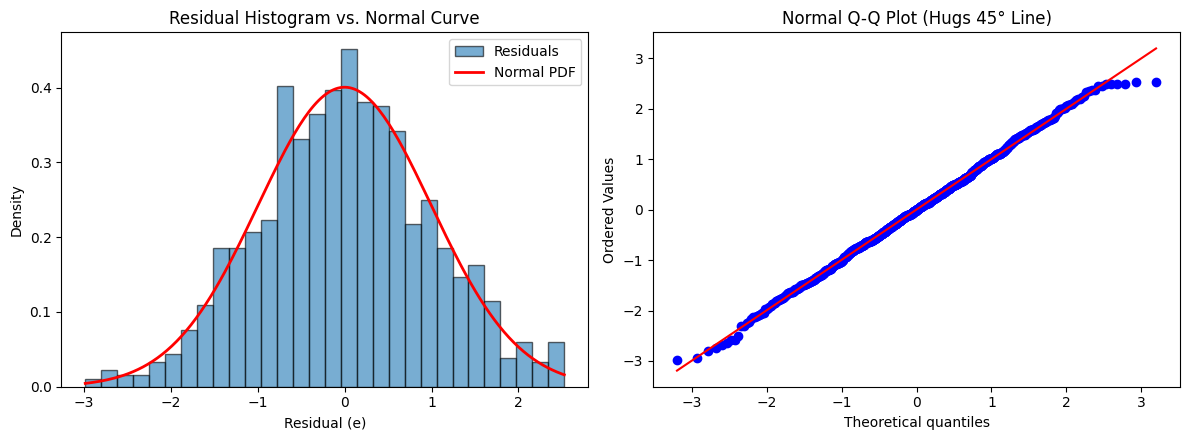

In [52]:
### Best-Case Scenario: Gaussian Residuals Check (Histogram, Q-Q Plot, Skewness & Kurtosis)
from scipy.stats import skew, kurtosis, jarque_bera, norm, probplot

residuals_best = output - (inputWithBias @ coefficientsEstimateAnalytical)

# 1. Mathematical Checks for Normality
sample_skew = skew(residuals_best)
sample_kurt = kurtosis(residuals_best)  # Excess kurtosis (Normal = 0)
jb_stat, jb_pval = jarque_bera(residuals_best)

print(f"Sample Skewness:        {sample_skew:.4f} (Target ~ 0)")
print(f"Sample Excess Kurtosis: {sample_kurt:.4f} (Target ~ 0)")
print(f"Jarque-Bera Test:       stat = {jb_stat:.4f}, p-value = {jb_pval:.4f} (> 0.05 -> Fail to reject Normality)")

# 2. Visual Diagnostics: Histogram + Q-Q Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Histogram with fitted Normal PDF
axes[0].hist(residuals_best, bins=30, density=True, alpha=0.6, edgecolor="black", label="Residuals")
x_grid = np.linspace(residuals_best.min(), residuals_best.max(), 200)
axes[0].plot(x_grid, norm.pdf(x_grid, residuals_best.mean(), residuals_best.std()), color="red", lw=2, label="Normal PDF")
axes[0].set_title("Residual Histogram vs. Normal Curve")
axes[0].set_xlabel("Residual (e)")
axes[0].set_ylabel("Density")
axes[0].legend()

# Q-Q Plot
probplot(residuals_best, dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q Plot (Hugs 45° Line)")

plt.tight_layout()
plt.show()

=== Diagnosis on Skewed Residuals ===
Skewness: 2.272 | Excess Kurtosis: 8.548 | Jarque-Bera p-val: 0.000e+00

=== 95% Prediction Interval Tail Error Rates (Target: 2.5% Below, 2.5% Above) ===
Naive Gaussian PI -> Below Lower: 0.0% | Above Upper: 4.4% (Miscalibrated!)
Fixed Empirical PI -> Below Lower: 2.6% | Above Upper: 2.6% (Balanced 2.5% tails!)


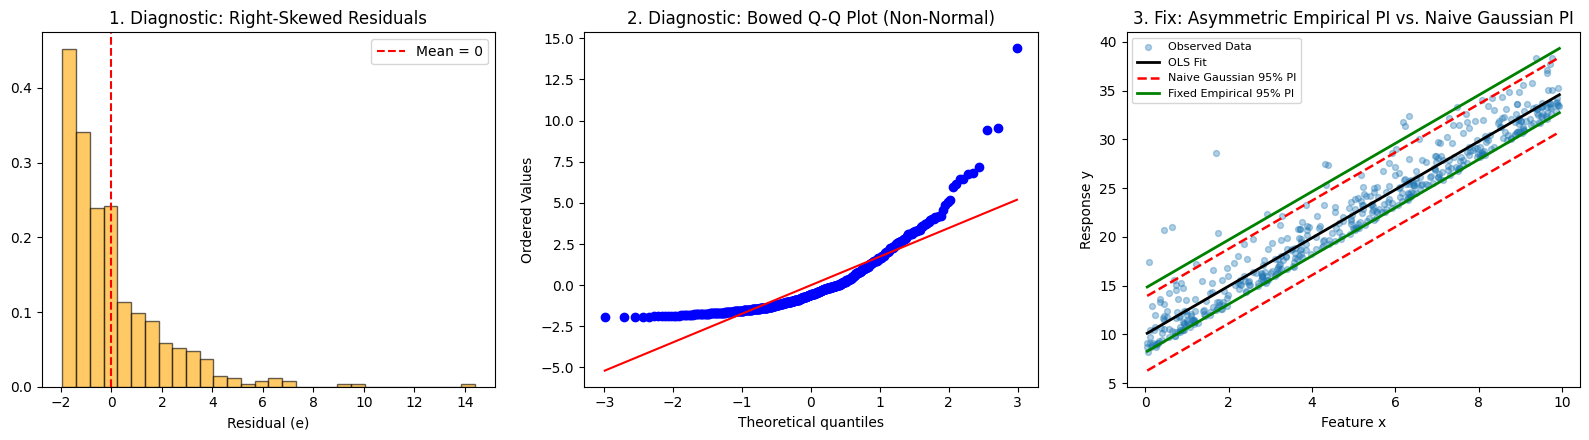

In [53]:
### Non-Normal (Skewed) Noise: Diagnose & Fix for Prediction Intervals
from scipy.stats import skew, kurtosis, jarque_bera, probplot, boxcox, t as t_dist
from scipy.special import inv_boxcox

np.random.seed(42)
n = 500
x = np.random.uniform(0, 10, n)
X_mat = np.column_stack([x, np.ones(n)])

# 1. Generate data with heavily right-skewed additive noise (Zero-meaned Exponential noise)
# Gauss-Markov holds (E[eps|X] = 0, constant variance), so beta_hat & Mean CI are fine,
# but Strict Normality fails -> Symmetric +/- t * SE Prediction Intervals will be miscalibrated!
raw_exp_noise = np.random.exponential(scale=2.0, size=n)
eps_skewed = raw_exp_noise - 2.0  # Centered attrue mean 0, but heavily right-skewed
y_skewed = 2.5 * x + 10.0 + eps_skewed

# 2. Fit OLS & Diagnose Non-Normal Residuals
beta_ols = np.linalg.inv(X_mat.T @ X_mat) @ X_mat.T @ y_skewed
y_hat = X_mat @ beta_ols
res_skewed = y_skewed - y_hat

jb_stat, jb_pval = jarque_bera(res_skewed)
print("=== Diagnosis on Skewed Residuals ===")
print(f"Skewness: {skew(res_skewed):.3f} | Excess Kurtosis: {kurtosis(res_skewed):.3f} | Jarque-Bera p-val: {jb_pval:.3e}")

# 3. Compare Naive Parametric PI vs. Fix (Empirical / Conformal Quantile PI)
dof = n - X_mat.shape[1]
s = np.sqrt((res_skewed @ res_skewed) / dof)
t_crit = t_dist.ppf(0.975, dof)
leverage = np.sum((X_mat @ np.linalg.inv(X_mat.T @ X_mat)) * X_mat, axis=1)
se_pred = s * np.sqrt(1 + leverage)

# Naive Symmetric 95% PI (assumes Gaussian tails)
pi_naive_lower = y_hat - t_crit * se_pred
pi_naive_upper = y_hat + t_crit * se_pred

# Fixed 95% PI using Empirical / Conformal Residual Quantiles (2.5th and 97.5th percentiles)
q_low, q_high = np.percentile(res_skewed, [2.5, 97.5])
pi_fixed_lower = y_hat + q_low
pi_fixed_upper = y_hat + q_high

print("\n=== 95% Prediction Interval Tail Error Rates (Target: 2.5% Below, 2.5% Above) ===")
print(f"Naive Gaussian PI -> Below Lower: {np.mean(y_skewed < pi_naive_lower)*100:.1f}% | Above Upper: {np.mean(y_skewed > pi_naive_upper)*100:.1f}% (Miscalibrated!)")
print(f"Fixed Empirical PI -> Below Lower: {np.mean(y_skewed < pi_fixed_lower)*100:.1f}% | Above Upper: {np.mean(y_skewed > pi_fixed_upper)*100:.1f}% (Balanced 2.5% tails!)")

# 4. Plot Diagnosis (Histogram & Q-Q Plot) + Prediction Interval Comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Plot 1: Skewed Residual Histogram
axes[0].hist(res_skewed, bins=30, density=True, alpha=0.6, color="orange", edgecolor="black")
axes[0].axvline(0, color="red", linestyle="--", label="Mean = 0")
axes[0].set_title("1. Diagnostic: Right-Skewed Residuals")
axes[0].set_xlabel("Residual (e)")
axes[0].legend()

# Plot 2: Bowed Q-Q Plot
probplot(res_skewed, dist="norm", plot=axes[1])
axes[1].set_title("2. Diagnostic: Bowed Q-Q Plot (Non-Normal)")

# Plot 3: Naive Symmetric PI vs. Fixed Asymmetric PI
sort_idx = np.argsort(x)
axes[2].scatter(x, y_skewed, alpha=0.35, s=18, label="Observed Data")
axes[2].plot(x[sort_idx], y_hat[sort_idx], color="black", lw=2, label="OLS Fit")
axes[2].plot(x[sort_idx], pi_naive_lower[sort_idx], "r--", lw=1.8, label="Naive Gaussian 95% PI")
axes[2].plot(x[sort_idx], pi_naive_upper[sort_idx], "r--", lw=1.8)
axes[2].plot(x[sort_idx], pi_fixed_lower[sort_idx], "g-", lw=2, label="Fixed Empirical 95% PI")
axes[2].plot(x[sort_idx], pi_fixed_upper[sort_idx], "g-", lw=2)
axes[2].set_title("3. Fix: Asymmetric Empirical PI vs. Naive Gaussian PI")
axes[2].set_xlabel("Feature x")
axes[2].set_ylabel("Response y")
axes[2].legend(loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()

In [31]:
def estimateResponse(
    inputWithBias, coefficients, output, new_input_with_bias, significance_level=0.05
):
    estimate = inputWithBias @ coefficients
    rss = (estimate - output) @ (estimate - output)
    ses = rss / (inputWithBias.shape[0] - inputWithBias.shape[1])

    scalingTerm = (
        new_input_with_bias
        @ np.linalg.inv(inputWithBias.T @ inputWithBias)
        @ new_input_with_bias.T
    )
    response_mean_std_error = np.sqrt(ses * np.diag(scalingTerm))
    response_std_error = np.sqrt(ses * (1 + np.diag(scalingTerm)))

    response = new_input_with_bias @ coefficients

    stdErrorsAway = t.ppf(1 - significance_level / 2, inputWithBias.shape[0] - inputWithBias.shape[1])

    upper_bound_response = response + stdErrorsAway * response_std_error
    lower_bound_response = response - stdErrorsAway * response_std_error

    upper_bound_response_mean = response + stdErrorsAway * response_mean_std_error
    lower_bound_response_mean = response - stdErrorsAway * response_mean_std_error
    df = pd.DataFrame([str(x) for x in new_input_with_bias], columns=["new input with bias"])
    df["response"] = response.reshape(-1, 1)
    df["response_mean_std_error"] = response_mean_std_error.reshape(-1, 1)
    df["upper_bound_response_mean"] = upper_bound_response_mean.reshape(-1, 1)
    df["lower_bound_response_mean"] = lower_bound_response_mean.reshape(-1, 1)
    df["response_std_error"] = response_std_error.reshape(-1,1)
    df["upper_bound_response"] = upper_bound_response.reshape(-1,1)
    df["lower_bound_response"] = lower_bound_response.reshape(-1,1)
    return df


estimateResponse(
    inputWithBias,
    coefficientsEstimateAnalytical,
    output,
    np.array([[3, 6, 1], [2, 1, 1]]),
)

,new input with bias,response,response_mean_std_error,upper_bound_response_mean,lower_bound_response_mean,response_std_error,upper_bound_response,lower_bound_response
0,[3 6 1],33.561797,0.370189,34.288236,32.835359,1.062373,35.64654,31.477054
1,[2 1 1],8.256016,0.127692,8.506592,8.005441,1.003943,10.22610,6.285933


#### Estimator Efficiency - VIF Filtering

When our goal is statistical inference, we want to make precise statements about how each feature is associated with the target $Y$, holding the other included features constant. A major hurdle here is **multicollinearity**: when features contain redundant, overlapping information.

When predictors are highly collinear, we face a direct tradeoff between the **granularity of our conditioning set** and the **precision of our estimates**:
* If we include all overlapping features, we are asking OLS to estimate what happens when $X_j$ changes while its nearly identical neighbors are held completely frozen. Because collinear features rarely move independently in the data, OLS has very little unique variation to work with. Mathematically, as standardized predictors become collinear, the minimum eigenvalue of $\mathbf{X}^T\mathbf{X}$ approaches zero, causing the diagonal elements of $(\mathbf{X}^T\mathbf{X})^{-1}$ to explode. This manifests as bloated standard errors and wide confidence intervals.

Rather than staring at a pairwise correlation matrix (which only catches 1-to-1 overlap and misses multivariate traps where $X_1 \approx X_2 + X_3$), we diagnose this overlap using the **Variance Inflation Factor (VIF)**:
* **How it works:** VIF regresses each feature $X_j$ against all other predictors in $\mathbf{X}$ to compute $R_j^2$ (the coeffiecient of determination, it is the 1 - ratio of the the sum of square residuals of the model over the sum of squared error predicitng the average output for the label. In other words the "explained variance"):
  $$\text{VIF}_j = \frac{1}{1 - R_j^2}$$
* **The Threshold:** A $\text{VIF} > 5$ or $10$ ($R_j^2 > 0.80 \text{ or } 0.90$) indicates that a feature is largely a linear combination of the other variables in your model.

When high VIFs inflate your standard errors, you have three options depending on the statement you want to make:

1. **Keep All Features (Accept Lower Precision):** Retain the overlapping variables if your domain question strictly requires holding them constant against one another, and accept the wider confidence intervals as an honest reflection of the limited independent variation in your data.
2. **Surgical Pruning (Narrow the Conditioning Set for Precision):** Drop the redundant feature (e.g., dropping `living_area_sqft` while keeping `total_sqft`). Your standard errors will shrink, and your interpretation simply updates to: *"the association of $X_1$ with $Y$, holding the remaining included features constant (without conditioning on the dropped feature)."*
3. **Feature Merging / Aggregation:** If multiple variables measure the same underlying construct (e.g., three survey questions on customer satisfaction), standardize them to a common scale ($\tilde{X}_j$) and combine them into a single index:
   $$\text{Composite\_Index} = \frac{\tilde{X}_1 + \tilde{X}_2 + \tilde{X}_3}{3}$$
   This preserves the information of all three variables while eliminating the collinearity between them.

In [26]:
# looks pretty good, which it should, constant variance 0 noise was used to generate it
# for interpretability, lets do VIF
# VIF = 1 / (1 - R^2) for R^2 value of using other features used regress to feature we are getting VIF from
# R^2 = 1 - SSR / SST where SSR is sum(residuals^2) and SST is sum((y - mean(y))^2)
def VIF(featureIndex, modelInput):
    x = np.hstack([modelInput[:, :featureIndex], modelInput[:, featureIndex + 1:]])
    y = modelInput[:, featureIndex]
    xWithBias = np.hstack([x, np.ones((x.shape[0], 1))])
    coefficients = np.linalg.inv(xWithBias.T @ xWithBias) @ xWithBias.T @ y
    modelOutput = xWithBias @ coefficients
    ssr = np.sum((y - modelOutput)**2)
    residuals = y - modelOutput
    sst = np.sum((y - np.mean(y))**2)
    rSquared = 1 - ssr / sst
    return 1 / (1 - rSquared)

for i in range(input.shape[1]):
    print(f"VIF of index {i}: {VIF(i, input)}")

def correlationMatrix(modelInput):
    means = np.mean(modelInput, axis=0).reshape(1, modelInput.shape[1])
    demeanedX = modelInput - means
    covariance = (demeanedX.T @ demeanedX) / (modelInput.shape[0] - 1)
    standardDeviationInv = 1/ np.sqrt(np.diag(covariance))
    return covariance * standardDeviationInv.reshape(1, modelInput.shape[1]) * standardDeviationInv.reshape(1, modelInput.shape[1]) 

print("Correlation matrix:\n", correlationMatrix(input))

VIF of index 0: 1.0002239162538493
VIF of index 1: 1.0002239162538493
Correlation matrix:
 [[ 1.         -0.01530421]
 [-0.01462775  1.        ]]


In [27]:
# looks like the VIFs indicate a low multi collinearity
# also correlation matrix is pretty much identity
# which is expected
# Using numpy's built-in function
corr_matrix_np = np.corrcoef(input, rowvar=False)
# 'rowvar=False' means columns are variables, rows are observations
print("Correlation matrix (using np.corrcoef):\n", corr_matrix_np)

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant # To add the intercept term

X_with_const = add_constant(input)
print("VIFs from statsmodels:\n", [variance_inflation_factor(X_with_const, i + 1) for i in range(input.shape[1])])

## so we are on track, though the correlation coefficient was off, its in the 4th decimal place in a value that ranges from -1 to 1
# so we will chalk it up to rounding errors and exact procedure

Correlation matrix (using np.corrcoef):
 [[ 1.         -0.01496216]
 [-0.01496216  1.        ]]
VIFs from statsmodels:
 [np.float64(1.0002239162538495), np.float64(1.0002239162538495)]


In [54]:
# todo: response inferences Q-Q plot and fixes code wise
# todo: reposition and review VIF filtering
# todo: Keep going below: going into inference - bias variance trade offs w/ CV (maybe reference something else if we can up top about CV :)).

## Validation
While goodness-of-fit diagnostics check how well the model fits the data it was trained on and whether assumptions are met, validation focuses on estimating how well the model will perform on new, unseen data. This is crucial for understanding the model's generalization ability and avoiding overfitting, where the model learns noise specific to the training set rather than the underlying relationship.

There are a couple common ways to do this:
1. **Simple test / train split**: One randomly partitions the dataset into a train and test dataset. The train dataset is used to estimate the coefficients of the model and then the test dataset is used to estimate the generalization error (like MSE, or square root of MSE).This is simple but an unlucky split could give you a pessimistic or optimistic estimate of the generalization error.
2. **K-fold cross validation**: One randomly partitions the dataset into K chunks, K - 1 are used to train the model while 1 is used to estimate the generalization error. This is done for each of the K partitions and the estimate of the generalization error is more robust to a random partition's data (since one could look at it's average as a point estimate and it's spread to understand the stability of the generalization error). It does take more to compute. 


In [27]:
# split train and test
splitIndex = int(len(input)*0.8)
trainX = input[:splitIndex]
trainY = output[:splitIndex]

testX = input[splitIndex:]
testY = output[splitIndex:]

# train on train
trainWithBias = np.hstack([trainX, np.ones((len(trainX), 1))])
print("training gradient:")
estimatedCoefficientsGradient = gradientBasedLinearRegression(trainWithBias, trainY)
print()
print("training analytical:")
estimatedCoefficientsAnalytical = analyticalLinearRegression(trainWithBias, trainY)
print()
# validate on test:
print("validating on test:")
testWithBias = np.hstack([testX, np.ones((len(testX), 1))])
print()
print("analytical mse:")
print(((testWithBias @ estimatedCoefficientsAnalytical - testY)**2).sum() / len(testX))
print()
print("gradient mse:")
print(((testWithBias @ estimatedCoefficientsGradient - testY)**2).sum() / len(testX))

training gradient:
end epoch 1, mse: 5.963806884106398
end epoch 2, mse: 2.542746662878572
end epoch 3, mse: 1.5641127667738084
end epoch 4, mse: 1.2368771958603433
end epoch 5, mse: 1.1241093536128373
end epoch 6, mse: 1.084716199697392
end epoch 7, mse: 1.0707489156577612
end epoch 8, mse: 1.0656908120500936
end epoch 9, mse: 1.0638008740641807
end epoch 10, mse: 1.0630622886230672

training analytical:
mse: 1.0616938400718734

validating on test:

analytical mse:
0.9520071893563237

gradient mse:
0.9487517103340221


analytical:
1.044796632909769
0.19789150726133106
gradient:
1.045559876113617
0.19730094221306552


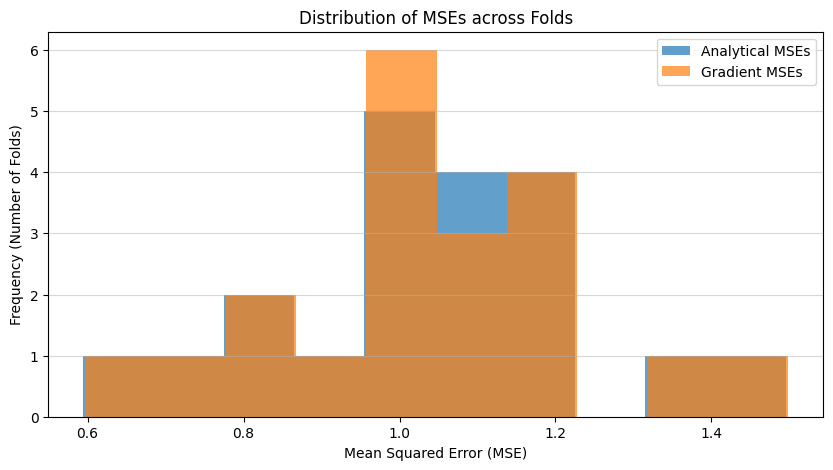

In [28]:
# k fold cross validation
# split everything
numFolds = 20
itemsPerFold =inputWithBias.shape[0] // numFolds
folds = []
targets = []
numIndices = inputWithBias.shape[0]

indices = np.random.permutation(numIndices)
outputMixed = output[indices]
inputWithBiasMixed = inputWithBias[indices]


folds = np.array_split(inputWithBiasMixed, numFolds)
targets = np.array_split(outputMixed, numFolds)
# for each do the process infer on the iterated fold
mses = []
for foldIndex, fold in enumerate(folds):
    trainX = np.vstack([folds[x] for x in range(len(folds)) if x != foldIndex])
    trainY = np.hstack([targets[x] for x in range(len(targets)) if x != foldIndex])

    testX = fold
    testY = targets[foldIndex]
    estimatedCoefficientsGradient = gradientBasedLinearRegression(trainX, trainY, debug=False)
    estimatedCoefficientsAnalytical = analyticalLinearRegression(trainX, trainY, debug=False)
    mse = (((testX @ estimatedCoefficientsAnalytical - testY)**2).sum() / len(testX), ((testX @ estimatedCoefficientsGradient - testY)**2).sum() / len(testX))
    mses.append(mse)
# average, capture spread, maybe distribution
plt.figure(figsize=(10, 5))
print("analytical:")
print(np.array([m[0] for m in mses]).mean())
print(np.array([m[0] for m in mses]).std())
plt.hist([m[0] for m in mses],  alpha=0.7, label='Analytical MSEs')

print("gradient:")
print(np.array([m[1] for m in mses]).mean())
print(np.array([m[1] for m in mses]).std())
plt.hist([m[1] for m in mses],  alpha=0.7, label='Gradient MSEs')
plt.title('Distribution of MSEs across Folds')
plt.xlabel('Mean Squared Error (MSE)')
plt.ylabel('Frequency (Number of Folds)')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()

plt.show()

# Model Complexity
Model complexity for linear regression can be controlled by both regularization and feature selection. Both of these reduce the variance (sensitivty to the training data) and introduce a bias.

## Regularization
Regularization introduces a penalty based on coefficient size. This penalty helps reduce model variance and improve generalization error, especially when dealing with multicollinearity or high-dimensional data. However, it makes direct interpretation of the coefficients harder because it introduces bias, shrinking them towards 0 compared to the OLS estimates.

Since the penalty is applied to the coefficient size, it's crucial to standardize features (e.g., subtract mean, divide by standard deviation) before applying regularization. This ensures features are on a comparable scale and the penalty is applied fairly, rather than being influenced by arbitrary units. Standardization adds a layer to interpretation, as coefficients then relate to changes in standard deviations of the predictors.

Also regularization excludes the intercept (or bias) term since this term isn't a measure of sensitivity to the features as the feature coefficients are, and the bias term itself is origin-dependent (really the baseline, if all coefficients are zero), and penalizing it would undesirably tie the regularization outcome to the choice of origin (or data centering), which is generally not the goal. The goal is to penalize feature sensitivity (slopes), not the overall offset (intercept).

There are two types of regularization adding either or both to $ sum((Y - \mathbf{X}\Beta)^2)$:
1. Lasso regularization or adding a $\lambda * \sum_i|\beta_i|$. Lasso stands for least absolute shrinkage and selection operator. If you look at the slope for absolute value compared to L2 (quadratic) the slope is stronger as you get closer to 0, therefore it tends to shrink coefficients and produce sparse models. Cannot be solved in analytical closed form, use proximal gradient descent (split the coefficient update into two):
    1. The gradient descent normal update (as described above in this notebook). Let's say this gives you $\vec{z}$.
    2. Proximal update, which is $\beta_j = sign(z_j)*max(|z_j| - \eta, 0)$, this essentially drives the ceofficient closer to 0 if it's not already in some threshold within 0. $η=α*\lambda$. Proximal gradient descent has been shown to be convex.


2. Ridge regularizaton or adding a $\lambda * \sum_i\beta_i^2$. Ridge is named that because its equivalent to adding a $\lambda*\mathbf{I}$ to the matrix before inverting, which looks like a series of peaks. It forces correlated predictors to "share" the credit because fo the quadratic nature. Instead of one coefficient becoming huge positive and a correlated one huge negative, Ridge tends to shrink both of their coefficients towards each other and towards zero. Can be solved analytical closed form as well: $\hat{\mathbf{b}}_{\text{Ridge}} = (\mathbf{X}^T\mathbf{X} + \lambda \mathbf{I})^{-1}\mathbf{X}^T\mathbf{y}$, as well as gradient descent (gradient is only different $\nabla_{\beta} L_{\text{Ridge}}(\beta) = -2\mathbf{X}^T(Y - \mathbf{X}\beta) + 2\lambda\beta$).


3. Mix Lasso and ridge for elastic net regression, using a single $\alpha$ for both and ratio ($\rho$) of L1 and L2. so it would be $\alpha*(\rho*\sum_i|\beta_i| + (1-\rho)*1/2*\sum_i\beta_i^2)$. This would similarily be optimized using proximal gradient descent:
    1. The gradient descent normal update (as described above in this notebook) with the L2 regularization parameter ($(1-\rho)*1/2$). Let's say this gives you $\vec{z}$.
    2. Proximal update, which is $\beta_j = sign(z_j)*max(|z_j| - \eta, 0)$, this essentially drives the ceofficient closer to 0 if it's not already in some threshold within 0. $η=α*\lambda$

Generally the weights add a retriction on the coefficient space that's being searched, in the bias variance decomposition $E[(y - \mathbf{x}.T\beta)^2] = bias^2 + Variance + \sigma^2$, bias is increased, but variance is reduced as well, so you can end up with a more stable estimate, thats not so dependent on the training data (less sensitive).

When searching for hyperparameters one could take the training set and further split it into a validation and training set, where the training set is used to train the parameters, and the validation set is used to find the best hyper parameters. or partition the dataset into a train (80-90%) and test, then on the train perform k-fold validation to find best hyper parameters, retrain on entire training set and report the test set performance of thsi model as the generalization error.


In [29]:
# lets standardize
inputStd = (input - input.mean(0)) / input.std(0)

# need to transform the y too to remove bias
outputDemeaned = output - output.mean()

In [30]:
# ridge regression (L2):
def ridgeRegressionAnalytical(inputStd, y, strength = 1):
    return np.linalg.inv(inputStd.T @ inputStd + strength*np.identity(inputStd.shape[1])) @ inputStd.T @ y

print(f"Ridge regression analytical solution:{ridgeRegressionAnalytical(inputStd, outputDemeaned)}")
print(f"train mse: {((inputStd @ ridgeRegressionAnalytical(inputStd, outputDemeaned) - outputDemeaned)**2).sum() / inputStd.shape[0]} ")

def ridgeRegressionGradient(x, y, strength = 1, learningRate=.001, epochs=1000, batchSize = 10, debug=True ):
    coefficientsEstimate = np.random.standard_normal(((2)))
    splitX = np.array_split(x, x.shape[0] // batchSize)
    splitY = np.array_split(y, x.shape[0] // batchSize)
    for e in range(epochs):
        for batchIndex in range(len(splitX)):
            batchInput = splitX[batchIndex]
            batchOutput = splitY[batchIndex]
            coefficientsEstimate += learningRate*2/ batchInput.shape[0] * batchInput.T@(batchOutput - batchInput @ coefficientsEstimate) - learningRate * 2 * strength * coefficientsEstimate / (x.shape[0] / batchInput.shape[0])
    return coefficientsEstimate

print(f"Ridge regression gradient solution: {ridgeRegressionGradient(x=inputStd, y=outputDemeaned)}")
print(f"train mse: {((inputStd @ ridgeRegressionGradient(inputStd, outputDemeaned) - outputDemeaned)**2).sum() / inputStd.shape[0]} ")

Ridge regression analytical solution:[0.07870291 2.9042601 ]
train mse: 1.039316717890523 
Ridge regression gradient solution: [0.08089565 2.87750621]
train mse: 1.0401898908069898 


In [31]:
print(f"Ridge regression gradient solution: {ridgeRegressionGradient(x=inputStd, y=outputDemeaned, strength=1)}")
print(f"Ridge regression analytical solution:{ridgeRegressionAnalytical(inputStd, outputDemeaned, strength=1)}")

Ridge regression gradient solution: [0.08089565 2.87750621]
Ridge regression analytical solution:[0.07870291 2.9042601 ]


In [32]:
print(f"Ridge regression gradient solution: {ridgeRegressionGradient(x=inputStd, y=outputDemeaned, strength=100)}")
print(f"Ridge regression analytical solution:{ridgeRegressionAnalytical(inputStd, outputDemeaned, strength=100)}")
# looks like the difference is even more pronounced as strenght goes up.
# I guess the reason is because additional hyper parameters for learning rate and epochs, though not entirely a satisfying outcome.

Ridge regression gradient solution: [0.05080014 1.45009199]
Ridge regression analytical solution:[0.07660416 2.64291672]


In [33]:
def lassoRegression(x, y, strength = 1, learningRate=.001, epochs=1000, batchSize = 10, debug=True ):
    coefficientsEstimate = np.random.standard_normal(((2)))
    splitX = np.array_split(x, x.shape[0] // batchSize)
    splitY = np.array_split(y, x.shape[0] // batchSize)
    for e in range(epochs):
        for batchIndex in range(len(splitX)):
            batchInput = splitX[batchIndex]
            batchOutput = splitY[batchIndex]
            coefficientsEstimate += learningRate*2/ batchInput.shape[0] * batchInput.T@(batchOutput - batchInput @ coefficientsEstimate)
            # lasso update
            threshold = learningRate*strength
            coefficientsEstimate = np.sign(coefficientsEstimate)*np.maximum(np.abs(coefficientsEstimate) - threshold, 0)
    return coefficientsEstimate

print(f"Lasso regression solution: {lassoRegression(x=inputStd, y=outputDemeaned)}")
print(f"train mse: {((inputStd @ lassoRegression(inputStd, outputDemeaned) - outputDemeaned)**2).sum() / inputStd.shape[0]} ")

def elasticNetRegression(x, y, strength = 1, l1Ratio = 0.5, learningRate=.001, epochs=1000, batchSize = 10, debug=True ):
    coefficientsEstimate = np.random.standard_normal(((2)))
    splitX = np.array_split(x, x.shape[0] // batchSize)
    splitY = np.array_split(y, x.shape[0] // batchSize)
    for e in range(epochs):
        for batchIndex in range(len(splitX)):
            batchInput = splitX[batchIndex]
            batchOutput = splitY[batchIndex]
            # ridge update
            coefficientsEstimate += learningRate*2/ batchInput.shape[0] * batchInput.T@(batchOutput - batchInput @ coefficientsEstimate) - 1/2 * (1-l1Ratio) * learningRate * 2 * strength * coefficientsEstimate / (x.shape[0] / batchInput.shape[0])
            # lasso update
            threshold = learningRate*strength*l1Ratio
            coefficientsEstimate = np.sign(coefficientsEstimate)*np.maximum(np.abs(coefficientsEstimate) - threshold, 0)
    return coefficientsEstimate
print(f"Elastic Net regression solution: {elasticNetRegression(x=inputStd, y=outputDemeaned)}")
print(f"train mse: {((inputStd @ elasticNetRegression(inputStd, outputDemeaned) - outputDemeaned)**2).sum() / inputStd.shape[0]} ")

Lasso regression solution: [-0.          2.40660272]
train mse: 1.2977202202170286 
Elastic Net regression solution: [-1.75219059e-04  2.65046903e+00]
train mse: 1.112274925405969 


## Feature Selection
For the sake of generalization (less degrees of freedom for the optimization to use to overfit), and interpretability (removing redundant features), it may be of use to find an ideal minimal subset of features that gets an acceptable performance.
This can also be viewed as a kind of regularization (discussed earlier) though in a discrete way, rather than continously as discussed in previous methods - an entire feature is removed not just coefficient adjusted.

Though for a subset size of n there are $2^n$ combinations of features to try. Which can be come prohibitive quickly. Practically, this is done in a greedy fashion either from the full set down to just an intercept or building up and selecting a feature to add one at a time, which is quadratic $O(p^2)$ in number of fits, which may not find the optimal subset, but has been empirically shown to be close.

To decide the best subset, one can use p-values (though more brittle since assumptions of feature independence are likely violated), or an information criteria like AIC or validation performance.

There are two ways to do this:
1. Forward stepwise - fit an intercept, then add the "best" feature next.
2. Backward stepwise - start will full set of features regression, remove feature that is "worst".

AIC is Akaike Information Criterion. It tries to capture a measure of generalization performance by including goodness of fit and model complexity:

$AIC = 2k - 2log(L)$

Linear model with additive normal 0 centered noise with constant variance:

$log(L) = -n/2log(2pi) - n/2log(\sigma^2) - 1/(2\sigma^2)*\sum_i e_i^2$

This is minimized.

In [34]:
x = np.arange(0,9).reshape(3,3)
x[:, [1,0]]

array([[1, 0],
       [4, 3],
       [7, 6]])

In [35]:
def AICModel(input, output):
    features = set(list(range(1, input.shape[1]))) # features to try (pooled)
    bestFeatures = [0]
    weights = analyticalLinearRegression(input[:, [(0)]], output)
    bestWeights = weights
    estimate = input[:, [(0)]] @ weights
    sse = (estimate - output) @ (estimate - output)
    n = input.shape[0]
    varEstimate = sse / n 
    k = 2
    logLikelihood = -n / 2 * np.log(2*np.pi) - n / 2 * np.log(varEstimate) - 1/2/varEstimate*sse
    AIC = 2*k - 2*logLikelihood
    while features:
        oldAIC = AIC
        bestFeature = -1
        for featureIndex in features:
            weights = analyticalLinearRegression(input[:, bestFeatures + [featureIndex]], output)
            estimate = input[:, bestFeatures + [featureIndex]] @ weights
            sse = (estimate - output) @ (estimate - output)
            n = input.shape[0]
            varEstimate = sse / n 
            kTemp = k + 1
            logLikelihood = -n / 2 * np.log(2*np.pi) - n / 2 * np.log(varEstimate) - 1/2/varEstimate*sse
            AICForThisModel = 2*kTemp - 2*logLikelihood
            if AICForThisModel < AIC:
                AIC = AICForThisModel
                bestFeature =  featureIndex
                bestWeights = weights
        if AIC == oldAIC:
            break
        bestFeatures.append(bestFeature)
        features.remove(bestFeature)
        k += 1
    return AIC, bestWeights, bestFeatures
        

AICModel(inputWithBias, output)

mse: 19.461541854838007
mse: 10.126691981619627
mse: 9.48719070216584
mse: 1.039308282847814


(np.float64(2884.432445630752),
 array([0.13639096, 3.02066051, 5.05235355]),
 [0, 2, 1])

# Feature engineering
In real dataset, you may want to take the existing features and form new ones that better fit the assumptions of linearaity and no multi collinearity, particularly for interpretation but also for inference.

### Response transformation
1. Look at histogram of response, and log response, does it improve normality?
    1. Original model assumes additive guassian 0 centered noise, so we should see a normal output.

### Categorical features:
1. Look at distributions, low number of samples will mean high standard errors. Combine smaller ones with conceptually similar probably effects.
1. Try to find a good reference category, usually the biggest or some other domain specific reason (like angle of slope of land where neutral is reference because its high porportion AND sort of makes sense to measure perturbation from it.)

### Numerical features (could be interperated as such):
1. Look at distribution does binning make sense for tightly clustered data where its sparse?
1. Consider transformations for numerical predictors if their own distribution is highly skewed. This can sometimes help linearize their relationship with Y or stabilize variance before you even check residuals against them.
1. Fit a model with this feature and with output (transformed or not) to see residuals, are they uniform throughout or reveal a pattern? If there is a pattern binning can help you capture the non linearity or Level - Log.



# Industry Standard Recipes and Standard Libraries

## Interpretability
For interpretability, we want to understand how features affect the outcome.
In this case we can:
1. Handle missing values, correct any data errors.
1. Do feature engineering to better conform to assumptions (particularly around residual distribution and multi collinearity see Feature Engineering section).
1. Perform analysis see coefficients, p -values.

For this the following libraries can be helpful:

* pandas - For exploration
* matplotlib - For visualizations
* scikit-learn - For preprocessing, training
* stats-models - For fitting, training, statistical inferences

Typically one would sample the data (if its a large scale dataset), and stick to single machine analysis with these libraries to work out interpertability - where additional data doesnt tend change them much (tens of thousands of representative samples).

## Prediction Performance Optimization
For prediction we want to reduce the generalization error. 
In this case we can:
1. Handle missing values, correct any data errors.
2. Perform hyper parameter testing (regularization strength, regularization type, transformation of output, transformation of individual features (does a log version of them fit better?)).\

For linear regression in a single machine:
* pandas - For exploration
* matplotlib - For visualizations
* scikit-learn - For preprocessing, training

For scaling, SparkML is a standard industry library that scale each of these phases. Typically one would:

1. Sample and use the single machine libraries to prototype feature engineering and model prototype.
2. Submit the job to SparkML to scale it out.

## Single Machine Scale Example
We'll go through the entire process on a house prediction dataset found here: https://github.com/JoannaBroniarek/House-Prices-Advanced-Regression-Techniques/tree/master/dane.

In [21]:
! mkdir -p .data
!curl https://raw.githubusercontent.com/JoannaBroniarek/House-Prices-Advanced-Regression-Techniques/refs/heads/master/dane/data_description.txt > ./.data/data_description.txt
!curl https://raw.githubusercontent.com/JoannaBroniarek/House-Prices-Advanced-Regression-Techniques/refs/heads/master/dane/train.csv > ./.data/train.csv


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 13370  100 13370    0     0  56490      0 --:--:-- --:--:-- --:--:-- 56652
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  449k  100  449k    0     0  1236k      0 --:--:-- --:--:-- --:--:-- 1235k


In [2]:
# okay from here we are going to split this data frame 80% train and 20% test, after shuffling
from sklearn.model_selection import train_test_split
import pandas as pd
trainData, testData = train_test_split(pd.read_csv(".data/train.csv"), test_size=0.2, shuffle=True)

In [3]:
print(trainData["Electrical"].isnull().sum(), testData["Electrical"].isnull().sum())
trainData.dropna(subset=["Electrical"], inplace=True)
testData.dropna(subset=["Electrical"], inplace=True)

1 0


In [4]:
print("train shape:",trainData.shape)
print("train sample:")
display(trainData.head())

train shape: (1167, 81)
train sample:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
72,73,60,RL,74.0,10141,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2009,WD,Normal,185000
539,540,20,RL,NaN,11423,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,2000,5,2010,WD,Normal,272000
857,858,60,RL,65.0,8125,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,3,2009,WD,Normal,174000
128,129,60,RL,69.0,7590,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2006,WD,Normal,155000
626,627,20,RL,NaN,12342,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,GdWo,Shed,600,8,2007,WD,Normal,139900


In [5]:
trainData.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [6]:
import re
import io

def parse_data_dictionary(text_data):
    """
    Parses a data dictionary text into a structured dictionary.

    Args:
        text_data (str): The string containing the data dictionary.

    Returns:
        dict: A dictionary where keys are column names and values are dicts
              containing 'description' and 'values' (another dict mapping
              value codes to their descriptions).
    """
    data_dict = {}
    current_column_name = None
    lines = io.StringIO(text_data.strip()) # Use StringIO to iterate over lines easily

    # Regex to identify a new column entry (e.g., "MSSubClass: Description...")
    # It captures the column name and its immediate description.
    column_header_pattern = re.compile(r"^\s*([a-zA-Z0-9]+):\s*(.*)")

    # Regex to identify a value entry (e.g., "    20    1-STORY...")
    # It captures the value code and its description.
    # Allows for numbers or strings as codes. Handles potential multiple spaces/tabs.
    value_pattern = re.compile(r"^\s+([^\t]+)\t(.*)$")

    for line in lines:
        line = line.rstrip() # Remove trailing whitespace

        # Check for a new column header
        header_match = column_header_pattern.match(line)
        if header_match:
            current_column_name = header_match.group(1)
            column_description = header_match.group(2).strip()
            data_dict[current_column_name] = {
                "description": column_description,
                "values": {}
            }
            # print(f"Found column: {current_column_name}") # For debugging
            continue # Move to the next line

        # If we have a current column, check for its values
        if current_column_name:
            value_match = value_pattern.match(line)
            if value_match:
                value_code = value_match.group(1).strip()
                value_description = value_match.group(2).strip()

                # Try to convert value_code to int if it's purely numeric,
                # otherwise keep as string.
                try:
                    value_code = int(value_code)
                except ValueError:
                    pass # Keep as string if not an int (e.g., "Grvl", "NA", "1.5Fin")

                data_dict[current_column_name]["values"][value_code] = value_description
                # print(f"  Value for {current_column_name}: {value_code} -> {value_description}") # For debugging
            # elif line.strip() and not header_match:
                # This handles cases where a description might continue on a new line
                # or there's just descriptive text not matching value pattern
                # For this specific format, most descriptions are on one line with the value
                # If a column description itself spans multiple lines before values, this needs adjustment
                # pass
    return data_dict
with open(".data/data_description.txt", "r") as file:
    file_content = file.read()
    metadata = parse_data_dictionary(file_content)

In [7]:
len(metadata.keys()), "id nor sales price not in there"
print(metadata.keys())

dict_keys(['MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'Bedroom', 'Kitchen', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'PoolQC', 'Fen

In [8]:
trainData.shape

(1167, 81)

In [9]:
import pandas as pd
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline

def clean_and_fix_data(df):
    """
    Applies a series of data cleaning and consistency fixes to the housing dataset.
    This function is designed to be used with sklearn's FunctionTransformer.
    """
    df_out = df.copy()

    rename_map = {
        "BedroomAbvGr": "Bedroom",
        "KitchenAbvGr": "Kitchen"
    }

    cols_to_rename = {k: v for k, v in rename_map.items() if k in df_out.columns}
    if cols_to_rename:
        df_out.rename(columns=cols_to_rename, inplace=True)

    if 'MSZoning' in df_out.columns:
        df_out.loc[df_out['MSZoning'] == "C (all)", 'MSZoning'] = "C"

    if 'Alley' in df_out.columns:
        df_out['Alley'] = df_out['Alley'].fillna('NA')

    if 'Neighborhood' in df_out.columns:
        df_out.loc[df_out['Neighborhood'] == "NAmes", 'Neighborhood'] = "Names"

    if 'BldgType' in df_out.columns:
        df_out.loc[df_out['BldgType'].isin(["Duplex", "duplx"]), 'BldgType'] = "Duplx"
        df_out.loc[df_out['BldgType'] == "2fmCon", 'BldgType'] = "2FmCon"
        df_out.loc[df_out['BldgType'] == "Twnhs", 'BldgType'] = "TwnhsI"

    if 'Exterior2nd' in df_out.columns:
        df_out.loc[df_out['Exterior2nd'] == "Wd Shng", 'Exterior2nd'] = "Wd Sdng"
        df_out.loc[df_out['Exterior2nd'] == "Brk Cmn", 'Exterior2nd'] = "BrkComm"
        df_out.loc[df_out['Exterior2nd'] == "CmentBd", 'Exterior2nd'] = "CemntBd"

    cols_to_fill_na = [
        "MasVnrType", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1",
        "BsmtFinType2", "FireplaceQu", "GarageType", "GarageFinish", "GarageQual",
        "GarageCond", "PoolQC", "Fence", "MiscFeature"
    ]

    for col in cols_to_fill_na:
        if col in df_out.columns:
            fill_value = "None" if col == "MasVnrType" else "NA"
            df_out[col] = df_out[col].fillna(fill_value)

    return df_out

partial_pipeline = Pipeline(
    [
        ("clean_and_fix_data", FunctionTransformer(clean_and_fix_data))
    ]
)
trainData = partial_pipeline.fit_transform(trainData)


In [10]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder

categorical_features = []
numerical_features = []
features_to_process = [col for col in trainData.columns if col not in ['Id', 'SalePrice']]

for column in features_to_process:
    # Use your metadata to determine if a column is categorical
    if column in metadata and len(metadata[column].get('values', {})):
        categorical_features.append(column)
    else:
        numerical_features.append(column)

print(f"Identified {len(categorical_features)} categorical features to encode.")
print(f"Identified {len(numerical_features)} numerical features to keep.")


encoder = OneHotEncoder(
    handle_unknown='ignore', # Handle unseen categories in test data
    drop='first',            # Create k-1 dummies, dropping the first category
    sparse_output=False      # Output a dense numpy array
)


print("\nFitting the OneHotEncoder on the training data...")
encoder.fit(trainData[categorical_features])

def encode_categorical(df, encoder, categorical_features, numerical_features):
    encoded_categorical_data = encoder.transform(df[categorical_features])
    encoded_feature_names = encoder.get_feature_names_out(categorical_features)
    encoded_categorical_df = pd.DataFrame(
        encoded_categorical_data, 
        columns=encoded_feature_names, 
        index=df.index
    )
    dfEncoded = pd.concat([
        df[numerical_features],
        encoded_categorical_df,
        df['SalePrice'] # Add the target back in
    ], axis=1)
    return dfEncoded
partial_pipeline = Pipeline(
    [
        ("encode_categorical", FunctionTransformer(encode_categorical, kw_args={"encoder": encoder, "categorical_features": categorical_features, "numerical_features": numerical_features}))
    ]
)

trainDfEncoded = partial_pipeline.fit_transform(trainData)

reference_category_map = {}
# `encoder.categories_` is a list of arrays, one for each feature
for i, feature_name in enumerate(categorical_features):
    # The categories are sorted alphabetically/numerically
    all_categories = encoder.categories_[i]
    # The reference category is the first one in the sorted list
    reference_category = all_categories[0]
    reference_category_map[feature_name] = reference_category

print("\n--- Learned Reference Category Map ---")
print(reference_category_map)


# TODO: see AI on how to refactor this to use pipeline 
# lets next look at nas and strategies to clean the data (imputation, removal)

Identified 46 categorical features to encode.
Identified 33 numerical features to keep.

Fitting the OneHotEncoder on the training data...

--- Learned Reference Category Map ---
{'MSSubClass': np.int64(20), 'MSZoning': 'C', 'Street': 'Grvl', 'Alley': 'Grvl', 'LotShape': 'IR1', 'LandContour': 'Bnk', 'Utilities': 'AllPub', 'LotConfig': 'Corner', 'LandSlope': 'Gtl', 'Neighborhood': 'Blmngtn', 'Condition1': 'Artery', 'Condition2': 'Artery', 'BldgType': '1Fam', 'HouseStyle': '1.5Fin', 'OverallQual': np.int64(1), 'OverallCond': np.int64(1), 'RoofStyle': 'Flat', 'RoofMatl': 'ClyTile', 'Exterior1st': 'AsbShng', 'Exterior2nd': 'AsbShng', 'MasVnrType': 'BrkCmn', 'ExterQual': 'Ex', 'ExterCond': 'Ex', 'Foundation': 'BrkTil', 'BsmtQual': 'Ex', 'BsmtCond': 'Fa', 'BsmtExposure': 'Av', 'BsmtFinType1': 'ALQ', 'BsmtFinType2': 'ALQ', 'Heating': 'GasA', 'HeatingQC': 'Ex', 'CentralAir': 'N', 'Electrical': 'FuseA', 'KitchenQual': 'Ex', 'Functional': 'Maj1', 'FireplaceQu': 'Ex', 'GarageType': '2Types', 'Gar

In [11]:
try:
    trainDfEncoded[reference_category_map["MSSubClass"]]
except:
    print(f"{reference_category_map['MSSubClass']} not in as expected")

20 not in as expected


In [12]:
rows_with_na_count = trainDfEncoded.isnull().any(axis=1).sum()

print(f"Number of rows with at least one NA: {rows_with_na_count}, fraction: {rows_with_na_count/ trainDfEncoded.shape[0]}, total rows: {trainDfEncoded.shape[0]}")

na_counts_per_column = trainDfEncoded.isnull().sum()
columns_with_na_original = na_counts_per_column[na_counts_per_column > 0].sort_values(ascending=False)
columns_with_na = columns_with_na_original
print("Columns with NA values and their counts:")
print(columns_with_na)

Number of rows with at least one NA: 285, fraction: 0.2442159383033419, total rows: 1167
Columns with NA values and their counts:
LotFrontage    216
GarageYrBlt     69
MasVnrArea       8
dtype: int64


In [13]:
# LotFrontage is significant 23.2% of the data.
# not going to impute with 0 as its a jump I am not comfortable with
# so going to impute with regression from all other feature

lot_frontage_x = trainDfEncoded[ trainDfEncoded.notna().all(axis=1) ].drop(columns=["SalePrice", *columns_with_na.index.to_list()])
lot_frontage_y = trainDfEncoded[ trainDfEncoded.notna().all(axis=1) ]["LotFrontage"]

In [14]:
from sklearn.linear_model import LinearRegression

lot_frontage_regressor = LinearRegression()
lot_frontage_regressor.fit(lot_frontage_x, lot_frontage_y)

lot_frontage_regressor.score(lot_frontage_x, lot_frontage_y)

0.7719593690977015

In [15]:
# decent R^2 value
# so we will predict this for na rows:
def lot_frontage_imputer(df, lot_frontage_regressor, columns_with_na):
    df_out = df.copy()
    predicted_missing = lot_frontage_regressor.predict(df[df["LotFrontage"].isna()].drop(columns=["SalePrice", *columns_with_na.index.to_list()]))
    nan_mask = df["LotFrontage"].isnull()
    df_out.loc[nan_mask, "LotFrontage"] = predicted_missing
    return df_out

partial_pipeline = Pipeline(
    [
        ("lot_frontage_imputer", FunctionTransformer(lot_frontage_imputer, kw_args={"lot_frontage_regressor": lot_frontage_regressor, "columns_with_na": columns_with_na}))
    ]
)
trainDfEncoded = partial_pipeline.fit_transform(trainDfEncoded)

In [16]:
rows_with_na_count = trainDfEncoded.isnull().any(axis=1).sum()

print(f"Number of rows with at least one NA: {rows_with_na_count}, fraction: {rows_with_na_count/ trainDfEncoded.shape[0]}, total rows: {trainDfEncoded.shape[0]}")

na_counts_per_column = trainDfEncoded.isnull().sum()
columns_with_na = na_counts_per_column[na_counts_per_column > 0].sort_values(ascending=False)
print("Columns with NA values and their counts:")
print(columns_with_na)

Number of rows with at least one NA: 77, fraction: 0.06598114824335904, total rows: 1167
Columns with NA values and their counts:
GarageYrBlt    69
MasVnrArea      8
dtype: int64


In [17]:
print(trainData[trainData['GarageYrBlt'].isnull()][['GarageType', 'GarageCars', 'GarageArea']].head())

     GarageType  GarageCars  GarageArea
1030         NA           0           0
562          NA           0           0
954          NA           0           0
393          NA           0           0
441          NA           0           0


In [18]:
# looks like year built is nan if no garage. 
# lets make a new one called garage age, year sold - garageyrbuilt, and 
# fill in garageyrbuilt with year sold, then drop those guys

def garage_age_feature_creator(df):
    df_out = df.copy()
    df_out["GarageYrBlt"] = df["GarageYrBlt"].fillna(df["YrSold"])
    df_out["GarageAge"] = df_out["YrSold"] - df_out["GarageYrBlt"]
    df_out = df_out.drop(columns=["GarageYrBlt"])
    return df_out

partial_pipeline = Pipeline(steps=[
    ('garage_age_feature_creator', FunctionTransformer(garage_age_feature_creator))
])

trainDfEncoded = partial_pipeline.fit_transform(trainDfEncoded)

In [19]:
rows_with_na_count = trainDfEncoded.isnull().any(axis=1).sum()

print(f"Number of rows with at least one NA: {rows_with_na_count}, fraction: {rows_with_na_count/ trainDfEncoded.shape[0]}, total rows: {trainDfEncoded.shape[0]}")

na_counts_per_column = trainDfEncoded.isnull().sum()
columns_with_na = na_counts_per_column[na_counts_per_column > 0].sort_values(ascending=False)
print("Columns with NA values and their counts:")
print(columns_with_na)

Number of rows with at least one NA: 8, fraction: 0.006855184233076264, total rows: 1167
Columns with NA values and their counts:
MasVnrArea    8
dtype: int64


In [20]:
print(trainData[trainData['MasVnrArea'].isnull()]['MasVnrType'].head())

650     None
936     None
1278    None
529     None
1243    None
Name: MasVnrType, dtype: object


In [21]:
# all none lets impute 0
def fill_na_mas_vnr_area_zero(df):
    df_out = df.copy()
    df_out['MasVnrArea'] = df['MasVnrArea'].fillna(0)
    return df_out

partial_pipeline = Pipeline(steps=[
    ("fill_na_mas_vnr_area_zero", FunctionTransformer(fill_na_mas_vnr_area_zero))
])

trainDfEncoded = partial_pipeline.fit_transform(trainDfEncoded)

In [22]:
rows_with_na_count = trainDfEncoded.isnull().any(axis=1).sum()

print(f"Number of rows with at least one NA: {rows_with_na_count}, fraction: {rows_with_na_count/ trainDfEncoded.shape[0]}, total rows: {trainDfEncoded.shape[0]}")

na_counts_per_column = trainDfEncoded.isnull().sum()
columns_with_na = na_counts_per_column[na_counts_per_column > 0].sort_values(ascending=False)
print("Columns with NA values and their counts:")
print(columns_with_na)

Number of rows with at least one NA: 0, fraction: 0.0, total rows: 1167
Columns with NA values and their counts:
Series([], dtype: int64)


In [23]:
trainDfEncoded

,LotFrontage,LotArea,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,...,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial,SalePrice,GarageAge
72,74.000000,10141,1998,1998,40.0,0,0,832,832,885,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,185000,11.0
539,75.462252,11423,2001,2002,479.0,1358,0,223,1581,1601,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,272000,9.0
857,65.000000,8125,1994,1995,0.0,0,0,702,702,702,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,174000,15.0
128,69.000000,7590,1966,1966,266.0,512,0,148,660,660,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,155000,40.0
626,77.064198,12342,1960,1978,0.0,0,0,978,978,1422,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,139900,47.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
900,61.491503,7340,1971,1971,0.0,322,0,536,858,858,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,110000,28.0
1016,73.000000,11883,1996,1996,196.0,690,0,814,1504,1504,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,203000,13.0
769,47.000000,53504,2003,2003,603.0,1416,0,234,1650,1690,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,538000,7.0
1350,91.000000,11643,1969,1969,368.0,500,0,748,1248,1338,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,200000,40.0


<Axes: >

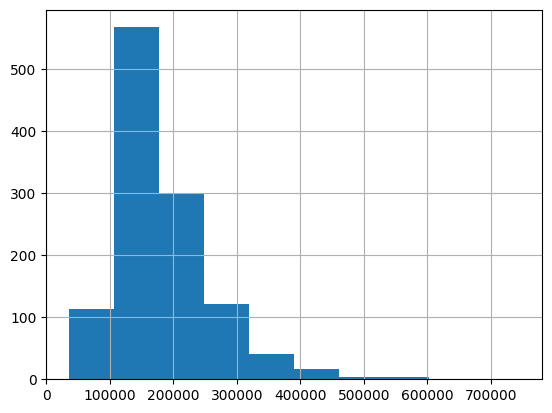

In [24]:
## so lets look at output (should be normal, else try to make it with transformation
## handle multicolinearity, Condition number < 10 ideally
trainData["SalePrice"].hist()

<Axes: >

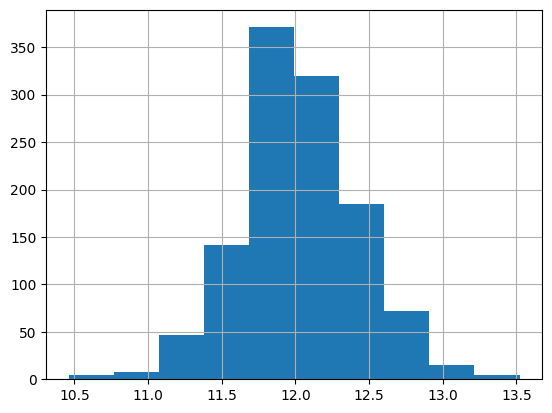

In [25]:
np.log(trainData["SalePrice"]).hist()

### Feature Engineering
Let's do our feature engineering and checks to set this up well for normality.

<Axes: >

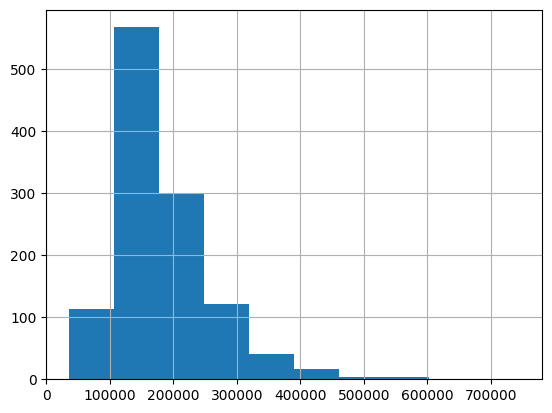

In [26]:
trainData["SalePrice"].hist()

In [27]:
print(metadata["MSSubClass"])
# The only unique info here is PUD, home style, age, number of floors all in rest of metadata
print(metadata["BldgType"])
print(metadata["YearBuilt"])
print(metadata["HouseStyle"])

{'description': 'Identifies the type of dwelling involved in the sale.', 'values': {20: '1-STORY 1946 & NEWER ALL STYLES', 30: '1-STORY 1945 & OLDER', 40: '1-STORY W/FINISHED ATTIC ALL AGES', 45: '1-1/2 STORY - UNFINISHED ALL AGES', 50: '1-1/2 STORY FINISHED ALL AGES', 60: '2-STORY 1946 & NEWER', 70: '2-STORY 1945 & OLDER', 75: '2-1/2 STORY ALL AGES', 80: 'SPLIT OR MULTI-LEVEL', 85: 'SPLIT FOYER', 90: 'DUPLEX - ALL STYLES AND AGES', 120: '1-STORY PUD (Planned Unit Development) - 1946 & NEWER', 150: '1-1/2 STORY PUD - ALL AGES', 160: '2-STORY PUD - 1946 & NEWER', 180: 'PUD - MULTILEVEL - INCL SPLIT LEV/FOYER', 190: '2 FAMILY CONVERSION - ALL STYLES AND AGES'}}
{'description': 'Type of dwelling', 'values': {'1Fam': 'Single-family Detached', '2FmCon': 'Two-family Conversion; originally built as one-family dwelling', 'Duplx': 'Duplex', 'TwnhsE': 'Townhouse End Unit', 'TwnhsI': 'Townhouse Inside Unit'}}
{'description': 'Original construction date', 'values': {}}
{'description': 'Style of dw

In [28]:
trainData.shape

(1167, 81)

In [29]:
train_data_engineered_features = trainData.copy()
metadata_engineered = metadata.copy()
# so we cut out MSSubClass and convert to isPUD
pud_categories = [120, 150, 160, 180]
train_data_engineered_features["isPUD"]  = train_data_engineered_features["MSSubClass"].isin(pud_categories).astype(int)
del metadata_engineered["MSSubClass"]
train_data_engineered_features = train_data_engineered_features.drop(columns=["MSSubClass"])

In [30]:
train_data_engineered_features["isPUD"].value_counts() 
# this is HOA + shared amenities in flexible layouts

isPUD
0    1044
1     123
Name: count, dtype: int64

In [31]:
print(trainData['MSZoning'].value_counts(normalize=True))

MSZoning
RL    0.798629
RM    0.146530
FV    0.036847
RH    0.010283
C     0.007712
Name: proportion, dtype: float64


In [32]:
# keep RL as baseline since its so big,
# group RH and C since they're small (and may have high std errors)
# Features: FV and RH, Other

train_data_engineered_features["MSZoning_is_residential_high_density_or_commercial_from_residential_low_density"]  = train_data_engineered_features["MSZoning"].isin(["RH", "C"]).astype(int)
train_data_engineered_features["MsZoning_is_floating_village_residential_from_residential_low_density"] =  (train_data_engineered_features["MSZoning"] == "FV").astype(int)
train_data_engineered_features["MSZoning_is_residential_medium_density_from_residential_low_densit"] =  (train_data_engineered_features["MSZoning"] == "RM").astype(int)
train_data_engineered_features = train_data_engineered_features.drop(columns=["MSZoning"])
del metadata_engineered["MSZoning"]

<Axes: >

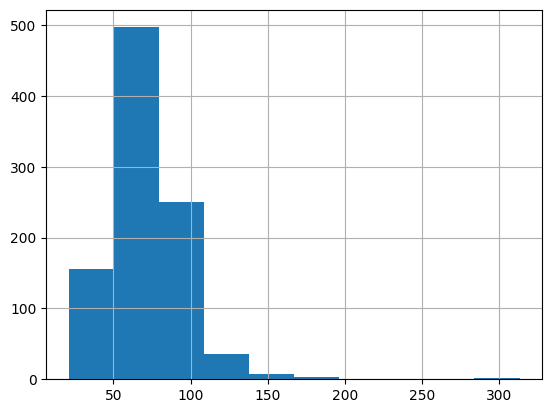

In [33]:
trainData["LotFrontage"].hist()

216
0


<Axes: >

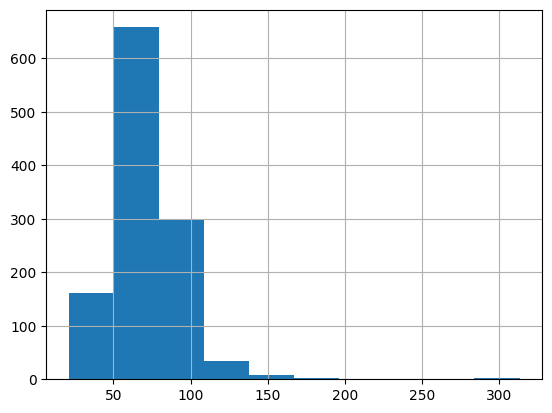

In [34]:
print(train_data_engineered_features["LotFrontage"].isna().sum())
# lets impute median by neighborhood and assumption on neighborhood
# makes p-value smaller and CI's smaller than they really are so just note
train_data_engineered_features['LotFrontage_IsMissing'] = train_data_engineered_features['LotFrontage'].isnull().astype(int)
train_data_engineered_features['LotFrontage'] = train_data_engineered_features.groupby('Neighborhood')['LotFrontage'].transform(
                                            lambda x: x.fillna(x.median()))
print(train_data_engineered_features["LotFrontage"].isna().sum())
train_data_engineered_features['LotFrontage'].hist()

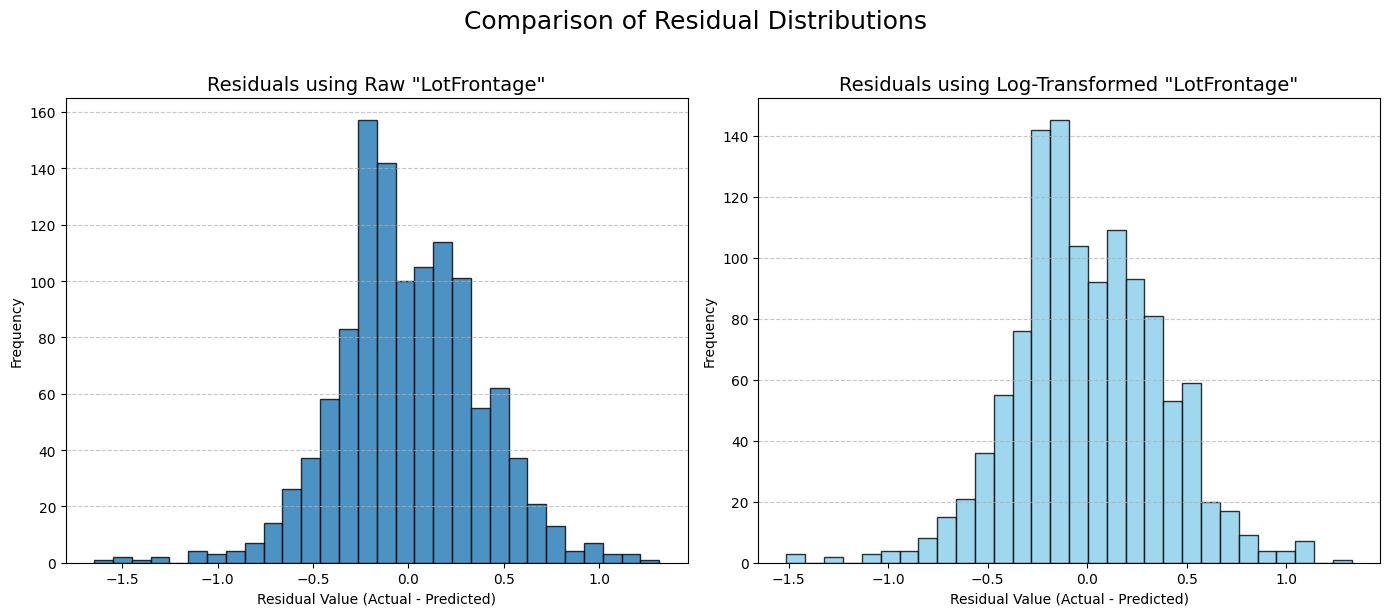

In [35]:
import matplotlib.pyplot as plt
def plot_residuals_single_feature(feature, label):
    """
    Fits two linear regression models (one with the raw feature, one with its log)
    and plots the histograms of their residuals on two separate subplots.
    
    Args:
        feature (pd.Series): The predictor variable.
        label (pd.Series): The target variable (e.g., SalePrice).
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    feature_raw = feature.to_numpy().reshape(-1, 1)
    label_numpy = label.to_numpy() 
    
    model_raw = LinearRegression()
    model_raw.fit(feature_raw, label_numpy)
    residuals_raw = label_numpy - model_raw.predict(feature_raw)

    axes[0].hist(residuals_raw, bins=30, edgecolor='black', alpha=0.8)
    axes[0].set_title(f'Residuals using Raw "{feature.name}"', fontsize=14)
    axes[0].set_xlabel("Residual Value (Actual - Predicted)")
    axes[0].set_ylabel("Frequency")
    axes[0].grid(axis='y', linestyle='--', alpha=0.7)

    feature_log = np.log(feature_raw)
    
    model_log = LinearRegression()
    model_log.fit(feature_log, label_numpy)
    residuals_log = label_numpy - model_log.predict(feature_log)
    
    axes[1].hist(residuals_log, bins=30, edgecolor='black', alpha=0.8, color='skyblue')
    axes[1].set_title(f'Residuals using Log-Transformed "{feature.name}"', fontsize=14)
    axes[1].set_xlabel("Residual Value (Actual - Predicted)")
    axes[1].set_ylabel("Frequency") 
    axes[1].grid(axis='y', linestyle='--', alpha=0.7)

    # Add a main title for the entire figure
    fig.suptitle('Comparison of Residual Distributions', fontsize=18, y=1.02)
    
    # Adjust layout to prevent titles/labels from overlapping
    plt.tight_layout()
    plt.show()
plot_residuals_single_feature(train_data_engineered_features['LotFrontage'], np.log(trainData["SalePrice"]))


In [36]:
# raw residuals look apropriate (normal)

In [37]:
print(train_data_engineered_features["Street"].value_counts(normalize=True))
# so one sided im dropping it
train_data_engineered_features.drop(columns=["Street"], inplace=True)
del metadata_engineered["Street"]

Street
Pave    0.994859
Grvl    0.005141
Name: proportion, dtype: float64


In [38]:
print(train_data_engineered_features["Alley"].value_counts(normalize=True))

train_data_engineered_features["HasAlley"] = (train_data_engineered_features["Alley"] != "NA").astype(int)
train_data_engineered_features["HasAlley"].value_counts(normalize=True)

train_data_engineered_features.drop(columns=["Alley"], inplace=True)
del metadata_engineered["Alley"]

Alley
NA      0.946015
Grvl    0.031705
Pave    0.022279
Name: proportion, dtype: float64


In [39]:
print(train_data_engineered_features["LotShape"].value_counts(normalize=True))

train_data_engineered_features["isIrregularLotShape"] = (train_data_engineered_features["LotShape"] == "Reg").astype(int)
print(train_data_engineered_features["isIrregularLotShape"].value_counts())
train_data_engineered_features.drop(columns=["LotShape"], inplace=True)
del metadata_engineered["LotShape"]

LotShape
Reg    0.640103
IR1    0.327335
IR2    0.024850
IR3    0.007712
Name: proportion, dtype: float64
isIrregularLotShape
1    747
0    420
Name: count, dtype: int64


In [40]:
print(train_data_engineered_features["LandContour"].value_counts(normalize=True))
train_data_engineered_features["isBankedFromLevelCountour"] = (train_data_engineered_features["LandContour"] == "Bnk").astype(int)
train_data_engineered_features["isLowOrHighSlopeFromLevelCountour"] = (train_data_engineered_features["LandContour"].isin(["Low", "HLS"])).astype(int)
train_data_engineered_features.drop(columns=["LandContour"], inplace=True)
del metadata_engineered["LandContour"]

LandContour
Lvl    0.898886
Bnk    0.044559
HLS    0.033419
Low    0.023136
Name: proportion, dtype: float64


In [41]:
print(train_data_engineered_features["Utilities"].value_counts(normalize=True))
# dropping lol 
train_data_engineered_features.drop(columns=["Utilities"], inplace=True)

Utilities
AllPub    0.999143
NoSeWa    0.000857
Name: proportion, dtype: float64


In [42]:
print(train_data_engineered_features["LotConfig"].value_counts(normalize=True))
# inside, corner culdsac and (frontage 2 or 3 roads) due to frequency
train_data_engineered_features["isCornerLotFromInsideLotReference"] = (train_data_engineered_features["LotConfig"] == "Corner").astype(int)
train_data_engineered_features["isCulDSacLotFromInsideLotReference"] = (train_data_engineered_features["LotConfig"] == "CulDSac").astype(int)
train_data_engineered_features["isFrontageOn2Or3RoadsFromInsideLotReference"] = (train_data_engineered_features["LotConfig"].isin(["FR2", "FR3"])).astype(int)
train_data_engineered_features.drop(columns=["LotConfig"], inplace=True);

LotConfig
Inside     0.721508
Corner     0.185090
CulDSac    0.057412
FR2        0.032562
FR3        0.003428
Name: proportion, dtype: float64


In [43]:
print(train_data_engineered_features["LandSlope"].value_counts(normalize=True))
# however I am concerned with overlap for LandContour
# there's high conceptual overlap so I am going to drop less descriptive one which is this one
train_data_engineered_features.drop(columns=["LandSlope"], inplace=True)

LandSlope
Gtl    0.946872
Mod    0.043702
Sev    0.009426
Name: proportion, dtype: float64


Neighborhood
Blueste    0.001714
Veenker    0.004284
NPkVill    0.005141
BrDale     0.011997
Blmngtn    0.011997
MeadowV    0.012853
StoneBr    0.017138
SWISU      0.017995
ClearCr    0.017995
Timber     0.027421
IDOTRR     0.028278
NoRidge    0.029991
Crawfor    0.033419
Mitchel    0.034276
BrkSide    0.039417
SawyerW    0.040274
Sawyer     0.050557
Somerst    0.051414
NridgHt    0.055698
NWAmes     0.055698
Gilbert    0.056555
Edwards    0.066838
OldTown    0.071979
CollgCr    0.097686
Names      0.159383
Name: proportion, dtype: float64


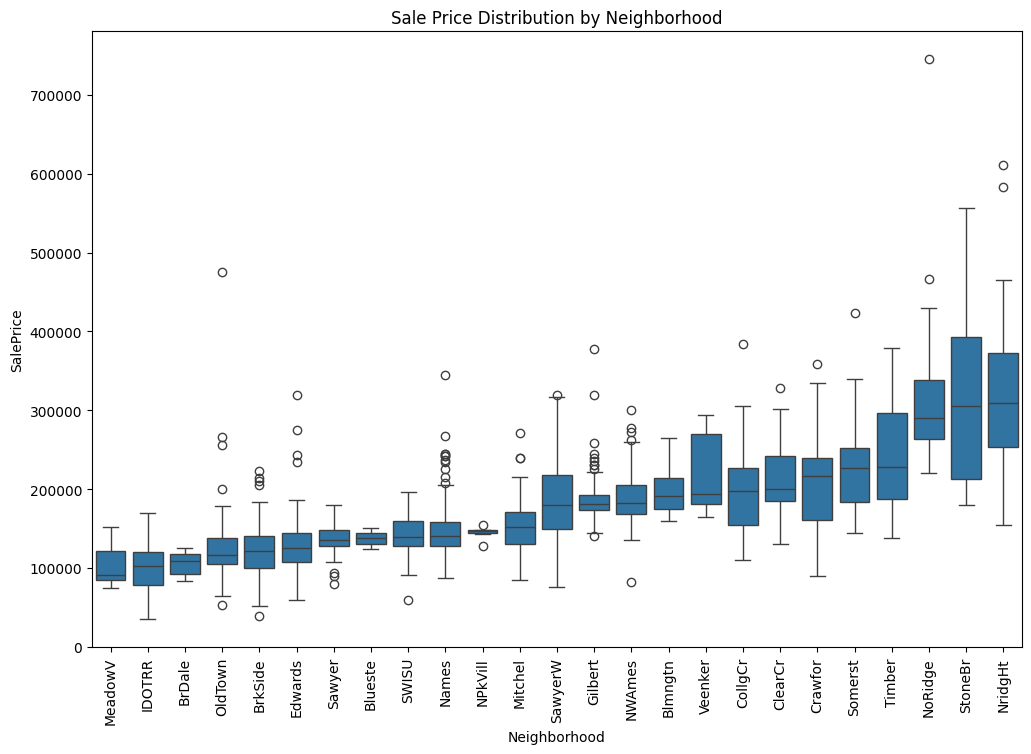

In [44]:
print(train_data_engineered_features["Neighborhood"].value_counts(normalize=True).sort_values())
import seaborn as sns
import matplotlib.pyplot as plt

# Create a boxplot to see the distribution of SalePrice by Neighborhood
plt.figure(figsize=(12, 8))
# Order the boxes by median SalePrice to make trends obvious
order = trainData.groupby('Neighborhood')['SalePrice'].median().sort_values().index
sns.boxplot(x='Neighborhood', y='SalePrice', data=trainData, order=order)
plt.xticks(rotation=90)
plt.title('Sale Price Distribution by Neighborhood')
plt.show()

In [45]:
# so now we will tier the neighborhoods and set reference

tier1_hoods = ['Veenker', 'Somerst', 'Timber', 'StoneBr', 'NoRidge', 'NridgHt']
tier3_hoods = ['MeadowV', 'IDOTRR', 'BrDale', 'OldTown', 'Edwards', 'BrkSide', 'Sawyer', 
               'Blueste', 'SWISU', 'Names', 'NPkVill']

def assign_neighborhood_tier(hood):
    if hood in tier1_hoods:
        return 'Tier_1_HighValue'
    elif hood in tier3_hoods:
        return 'Tier_3_LowerValue'
    else: # Everything else falls into the middle tier
        return 'Tier_2_MidValue'

train_data_engineered_features['Neighborhood_Tier'] = train_data_engineered_features['Neighborhood'].apply(assign_neighborhood_tier)

train_data_engineered_features['isTier2MidValueNeighborhoodFromTier3LowValueNeighborhoodReference'] = (train_data_engineered_features['Neighborhood_Tier'] == "Tier_2_MidValue").astype(int)
train_data_engineered_features['isTier1HighValueNeighborhoodFromTier3LowValueNeighborhoodReference'] = (train_data_engineered_features['Neighborhood_Tier'] == 'Tier_1_HighValue').astype(int)

train_data_engineered_features.drop(columns=["Neighborhood_Tier", "Neighborhood"], inplace=True)

del metadata_engineered["Neighborhood"]

In [46]:
train_data_engineered_features["AdjacentToArterialStreet"] = ((train_data_engineered_features["Condition1"] == "Artery") | (train_data_engineered_features["Condition2"] == "Artery")).astype(int)
print(f"Aterial condition fraction:{train_data_engineered_features['AdjacentToArterialStreet'].mean()}")

train_data_engineered_features["AdjacentToFeederStreet"] = ((train_data_engineered_features["Condition1"] == "Feedr") | (train_data_engineered_features["Condition2"] == "Feedr")).astype(int)
print(f"Feeder condition fraction:{train_data_engineered_features['AdjacentToFeederStreet'].mean()}")

train_data_engineered_features["NormalProximity"] = ((train_data_engineered_features["Condition1"] == "Norm") | (train_data_engineered_features["Condition2"] == "Norm")).astype(int)
print(f"Normal condition fraction:{train_data_engineered_features['NormalProximity'].mean()}")

train_data_engineered_features["RRNnProximity"] = ((train_data_engineered_features["Condition1"] == "RRNn") | (train_data_engineered_features["Condition2"] == "RRNn")).astype(int)
print(f"200' of N-S railroad condition fraction:{train_data_engineered_features['RRNnProximity'].mean()}")

train_data_engineered_features["RRAnAdjacency"] = ((train_data_engineered_features["Condition1"] == "RRAn") | (train_data_engineered_features["Condition2"] == "RRAn")).astype(int)
print(f"Adjacent to N-S railroad condition fraction:{train_data_engineered_features['RRAnAdjacency'].mean()}")

train_data_engineered_features["PositiveOffsiteFeatureProximity"] = ((train_data_engineered_features["Condition1"] == "PosN") | (train_data_engineered_features["Condition2"] == "PosN")).astype(int)
print(f"Positive offsite feature condition fraction:{train_data_engineered_features['PositiveOffsiteFeatureProximity'].mean()}")

train_data_engineered_features["PositiveOffsiteFeatureAdjacent"] = ((train_data_engineered_features["Condition1"] == "PosA") | (train_data_engineered_features["Condition2"] == "PosA")).astype(int)
print(f"Positive offsite feature adjacent condition fraction:{train_data_engineered_features['PositiveOffsiteFeatureAdjacent'].mean()}")

train_data_engineered_features["RRNeProximity"] = ((train_data_engineered_features["Condition1"] == "RRNe") | (train_data_engineered_features["Condition2"] == "RRNe")).astype(int)
print(f"200' of E-W railroad condition fraction:{train_data_engineered_features['RRNeProximity'].mean()}")

train_data_engineered_features["RRNeAdjacency"] = ((train_data_engineered_features["Condition1"] == "RRAe") | (train_data_engineered_features["Condition2"] == "RRAe")).astype(int)
print(f"Adjacent E-W railroad condition fraction:{train_data_engineered_features['RRNeAdjacency'].mean()}")


Aterial condition fraction:0.031705227077977724
Feeder condition fraction:0.061696658097686374
Normal condition fraction:0.9922879177377892
200' of N-S railroad condition fraction:0.005141388174807198
Adjacent to N-S railroad condition fraction:0.02056555269922879
Positive offsite feature condition fraction:0.011996572407883462
Positive offsite feature adjacent condition fraction:0.005141388174807198
200' of E-W railroad condition fraction:0.001713796058269066
Adjacent E-W railroad condition fraction:0.005998286203941731


In [47]:
# Since this is like 2 of N, I am considering making isNotNormal a feature as well as AdjacentOrProximityToRailroad combining the 4, and arterialOrFeeder condition another feature.
# isNotNormal since normal is a natural baseline
train_data_engineered_features["isNotNormalProximity"] = ((train_data_engineered_features["Condition1"] != "Norm") & (train_data_engineered_features["Condition2"] == "Norm")).astype(int)
train_data_engineered_features.drop(columns=["NormalProximity"], inplace=True)

train_data_engineered_features["isNearRailRoad"] = (train_data_engineered_features["RRNnProximity"] | train_data_engineered_features["RRAnAdjacency"] | train_data_engineered_features["RRNeProximity"] | train_data_engineered_features["RRNeAdjacency"]).astype(int)
train_data_engineered_features.drop(columns=["RRNnProximity", "RRAnAdjacency", "RRNeProximity", "RRNeAdjacency"], inplace=True)

train_data_engineered_features["isNearPositiveOffsiteFeature"] = (train_data_engineered_features["PositiveOffsiteFeatureProximity"] | train_data_engineered_features["PositiveOffsiteFeatureAdjacent"])
train_data_engineered_features.drop(columns=["PositiveOffsiteFeatureAdjacent", "PositiveOffsiteFeatureProximity"], inplace=True)

train_data_engineered_features.drop(columns=["Condition1", "Condition2"], inplace=True)

In [48]:
print(train_data_engineered_features["HouseStyle"].value_counts(normalize=True))
train_data_engineered_features["is2or2.5StoryFrom1StoryReference"] = train_data_engineered_features["HouseStyle"].isin(["2Story", "2.5Fin"]).astype(int)
train_data_engineered_features["is1.5StoryFrom1StoryReference"] = train_data_engineered_features["HouseStyle"].isin(["1.5Fin"]).astype(int)
train_data_engineered_features["isSplitLevelOrFoyerFrom1StoryReference"] = train_data_engineered_features["HouseStyle"].isin(["SLvl", "SFoyer"]).astype(int)
train_data_engineered_features["isUnfinishedFrom1StoryReference"] = train_data_engineered_features["HouseStyle"].isin(["1.5Unf", "2.5Unf"]).astype(int)
train_data_engineered_features.drop(columns=["HouseStyle"], inplace=True)

HouseStyle
1Story    0.506427
2Story    0.302485
1.5Fin    0.103685
SLvl      0.045416
SFoyer    0.023136
1.5Unf    0.010283
2.5Unf    0.005141
2.5Fin    0.003428
Name: proportion, dtype: float64


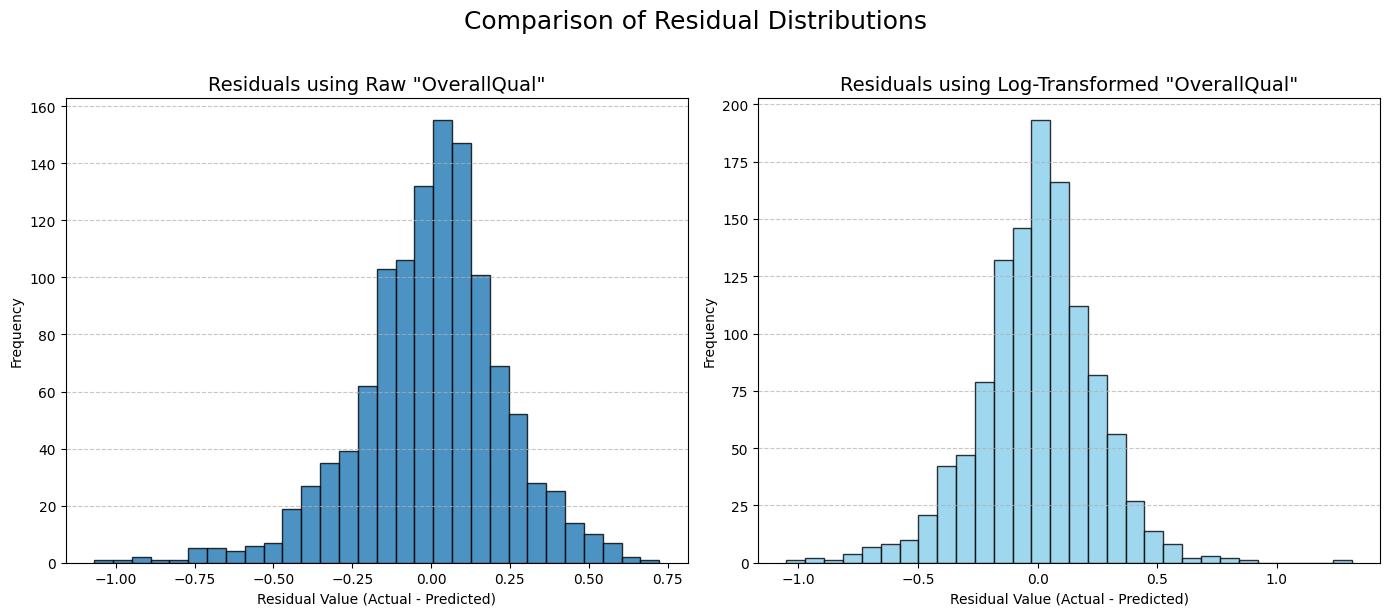

In [49]:
plot_residuals_single_feature(train_data_engineered_features["OverallQual"], np.log(trainData["SalePrice"]))

In [50]:
train_data_engineered_features.drop(columns=["BldgType"], inplace=True)

int64


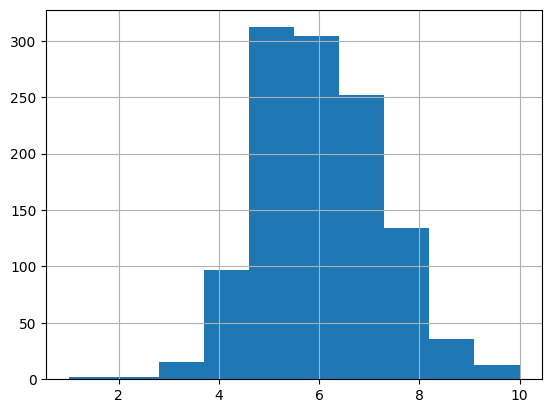

In [51]:
train_data_engineered_features["OverallQual"].hist()
print(train_data_engineered_features["OverallQual"].dtype)
# I feel like we can keep this as is
# not really more normal and the distribution looks okay

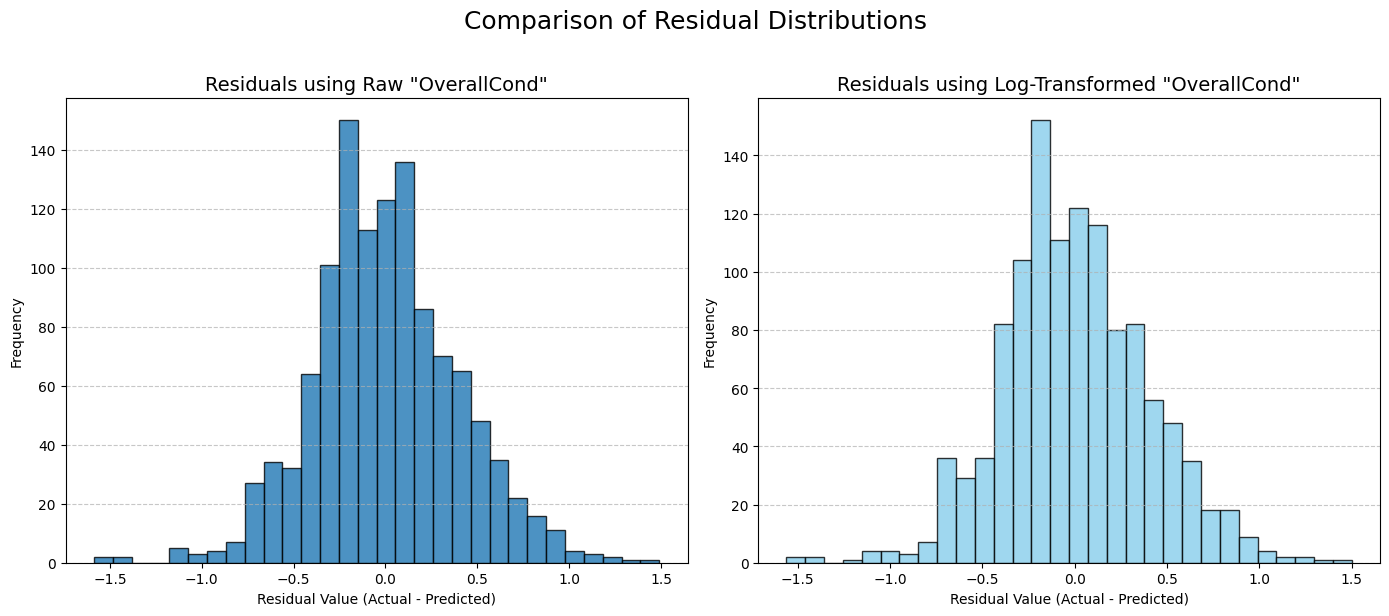

In [52]:
plot_residuals_single_feature(train_data_engineered_features["OverallCond"], np.log(trainData["SalePrice"]))

In [53]:
# overall condition transformed to log doesn't help much either in residuals

In [54]:
# overall condition since its a bit oddly shaped I am considering 3 categories 5, below 5 and above 5
def bin_overall_condition(c):
    if c == 5:
        return "AVG"
    elif c < 5:
        return "BELOW_AVG"
    else:
        return "ABOVE_AVG"

train_data_engineered_features["OverallConditionBinned"] = train_data_engineered_features["OverallCond"].apply(bin_overall_condition)

train_data_engineered_features["isAboveAverageFromBelowAverageReferenceOverallQuality"] = (train_data_engineered_features["OverallConditionBinned"] == "ABOVE_AVG").astype(int)
train_data_engineered_features["isAverageFromBelowAverageReferenceOverallQuality"] = (train_data_engineered_features["OverallConditionBinned"] == "AVG").astype(int)

train_data_engineered_features.drop(columns=["OverallConditionBinned", "OverallCond"], inplace=True)

<Axes: >

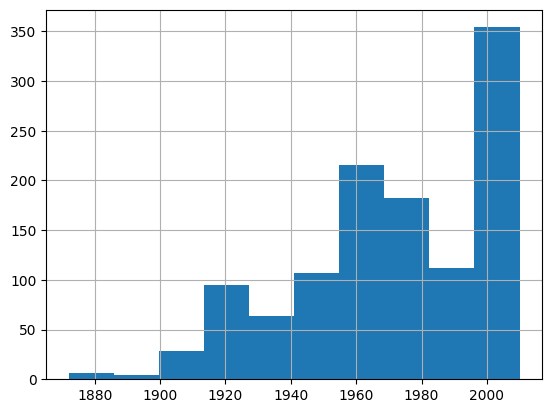

In [55]:
train_data_engineered_features["YearBuilt"].hist()

In [56]:
# reference category will be before 1941
def binYearBuilt(year):
    if year <= 1940:
        return "BEFORE_1941"
    elif year <= 1980:
        return "BETWEEN_1940_AND_1980"
    else:
        return "AFTER_1980"
    
train_data_engineered_features["YearBuiltBinned"] = train_data_engineered_features["YearBuilt"].apply(binYearBuilt)
train_data_engineered_features["isBuiltBetween1940And1980FromReferenceBefore1941"] = (train_data_engineered_features["YearBuiltBinned"] == "BETWEEN_1940_AND_1980").astype(int)
train_data_engineered_features["isBuiltAfter1980FromReferenceBefore1941"] = (train_data_engineered_features["YearBuiltBinned"] == "AFTER_1980").astype(int)
train_data_engineered_features.drop(columns=["YearBuiltBinned", "YearBuilt"], inplace=True)

In [57]:
train_data_engineered_features["wasRemodeled"] = (train_data_engineered_features["YearRemodAdd"] != trainData["YearBuilt"]).astype(int) 
train_data_engineered_features.drop(columns=["YearRemodAdd"], inplace=True) # was remodeled simple bin since ~47%

In [58]:
print(train_data_engineered_features["RoofStyle"].value_counts(normalize=True))
# looks like gable reference, and nonGlableRoofStyle 
train_data_engineered_features["hipOrNonGableRoofStyle"] = (train_data_engineered_features["RoofStyle"] != "Gable").astype(int)
train_data_engineered_features.drop(columns=["RoofStyle"], inplace=True)

RoofStyle
Gable      0.778063
Hip        0.200514
Flat       0.009426
Gambrel    0.005998
Mansard    0.005141
Shed       0.000857
Name: proportion, dtype: float64


In [59]:
print(train_data_engineered_features["RoofMatl"].value_counts(normalize=True))
# 98% one value so skewed will drop
train_data_engineered_features.drop(columns=["RoofMatl"], inplace=True)

RoofMatl
CompShg    0.982005
Tar&Grv    0.007712
WdShake    0.004284
WdShngl    0.002571
Roll       0.000857
Membran    0.000857
ClyTile    0.000857
Metal      0.000857
Name: proportion, dtype: float64


In [60]:
print(train_data_engineered_features["Exterior1st"].value_counts(normalize=True), train_data_engineered_features["Exterior2nd"].value_counts(normalize=True))
# has to have an exterior so cant just do binary for whetehr it has it or not
# will just use exterior 1 reference VinlySd:
train_data_engineered_features["hasHighDensityFiberboardPrimaryExteriorFromVinylSdPrimaryExterior"] = (train_data_engineered_features["Exterior1st"] == "HdBoard").astype(int)
train_data_engineered_features["hasMetalSidingPrimaryExteriorFromVinylSdPrimaryExterior"] = (train_data_engineered_features["Exterior1st"] == "MetalSd").astype(int)
train_data_engineered_features["hasWoodSidingPrimaryExteriorFromVinylSdPrimaryExterior"] = (train_data_engineered_features["Exterior1st"] == "Wd Sdng").astype(int)
train_data_engineered_features["hasPlywoodPrimaryExteriorFromVinylSdPrimaryExterior"] = (train_data_engineered_features["Exterior1st"] == "Plywood").astype(int)
train_data_engineered_features["hasCementBoardPrimaryExteriorFromVinylSdPrimaryExterior"] = (train_data_engineered_features["Exterior1st"] == "CemntBd").astype(int)
train_data_engineered_features["hasBrickFacedPrimaryExteriorFromVinylSdPrimaryExterior"] = (train_data_engineered_features["Exterior1st"] == "BrkFace").astype(int)
train_data_engineered_features["hasWoodShinglesOrStuccoOrAbestosShinglesOrBrickCommonOrStoneOrAsphaltShinglesOrImitationStuccoOrConcreteMasonryUnitPrimaryExteriorFromVinylSlidingPrimaryExterior"] = (train_data_engineered_features["Exterior1st"].isin(["WdShing", "Stucco", "AsbShng", "BrkComm", "Stone", "AsphShn", "ImStucc", "CBlock"])).astype(int)
train_data_engineered_features.drop(columns=["Exterior1st", "Exterior2nd"], inplace=True)

Exterior1st
VinylSd    0.352185
MetalSd    0.154242
HdBoard    0.149100
Wd Sdng    0.143102
Plywood    0.072836
CemntBd    0.042845
BrkFace    0.036847
WdShing    0.016281
Stucco     0.013710
AsbShng    0.012853
Stone      0.001714
BrkComm    0.001714
ImStucc    0.000857
AsphShn    0.000857
CBlock     0.000857
Name: proportion, dtype: float64 Exterior2nd
VinylSd    0.345330
Wd Sdng    0.161954
MetalSd    0.149957
HdBoard    0.139674
Plywood    0.095973
CemntBd    0.041988
BrkFace    0.017138
Stucco     0.014567
AsbShng    0.012853
ImStucc    0.007712
BrkComm    0.005141
Stone      0.004284
AsphShn    0.002571
CBlock     0.000857
Name: proportion, dtype: float64


In [61]:
print(train_data_engineered_features["MasVnrType"].value_counts(normalize=True))
train_data_engineered_features["hasBrickFaceOrBrickCommonMasonryVeneerType"] = (train_data_engineered_features["MasVnrType"].isin(["BrkFace", "BrkCmn"])).astype(int)
train_data_engineered_features["hasStoneMasonryVeneerType"] = (train_data_engineered_features["MasVnrType"] == "Stone").astype(int)
train_data_engineered_features.drop(columns=["MasVnrType"], inplace=True)

MasVnrType
None       0.592973
BrkFace    0.307626
Stone      0.089974
BrkCmn     0.009426
Name: proportion, dtype: float64


np.float64(0.006855184233076264)

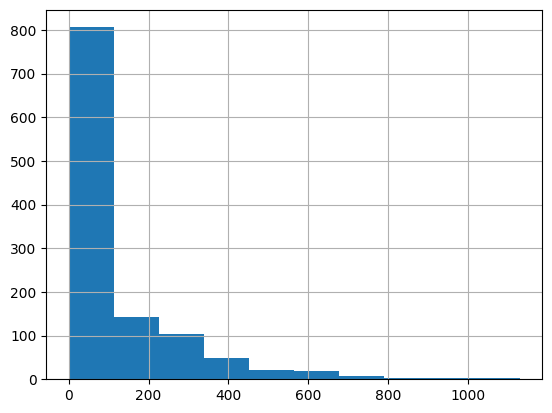

In [62]:
train_data_engineered_features["MasVnrArea"].hist()
(train_data_engineered_features["MasVnrArea"].isna()).mean()

In [63]:
# am going to drop this because it's logically correlated with Masonry veneer type which we already capture
train_data_engineered_features.drop(columns=["MasVnrArea"], inplace=True)

In [64]:
print(train_data_engineered_features["ExterQual"].value_counts(normalize=True))
# dropping this and use overall quality, as there is probably a lot of multi colinearity logically and between good and typical account for over 95% of data
train_data_engineered_features.drop(columns=["ExterQual"], inplace=True)

ExterQual
TA    0.622965
Gd    0.332476
Ex    0.035133
Fa    0.009426
Name: proportion, dtype: float64


In [65]:
print(train_data_engineered_features["ExterCond"].value_counts(normalize=True))
# dropping this and use overall condition, as there is probably a lot of multi colinearity logically and between good and typical account for over 97% of data, not that useful
train_data_engineered_features.drop(columns=["ExterCond"], inplace=True)

ExterCond
TA    0.873179
Gd    0.107969
Fa    0.017138
Po    0.000857
Ex    0.000857
Name: proportion, dtype: float64


In [66]:
print(train_data_engineered_features["Foundation"].value_counts(normalize=True))
train_data_engineered_features["isCinderBlockFoundationFromReferencePouredConcreteFoundation"] = (train_data_engineered_features["Foundation"] == "CBlock").astype(int)
train_data_engineered_features["isBrikeTileFoundationFromReferencePouredConcreteFoundation"] = (train_data_engineered_features["Foundation"] == "BrkTil").astype(int)
train_data_engineered_features["isSlabOrStoneOrWoodFoundationFromReferencePouredConcreteFoundation"] = (train_data_engineered_features["Foundation"].isin(["Slab", "Stone", "Wood"])).astype(int)
train_data_engineered_features.drop(columns=["Foundation"], inplace=True)

Foundation
PConc     0.445587
CBlock    0.441302
BrkTil    0.089974
Slab      0.016281
Stone     0.004284
Wood      0.002571
Name: proportion, dtype: float64


In [67]:
print(train_data_engineered_features["BsmtExposure"].value_counts(normalize=True))
print(train_data_engineered_features["BsmtQual"].value_counts(normalize=True))
print(train_data_engineered_features["BsmtCond"].value_counts(normalize=True))

BsmtExposure
No    0.654670
Av    0.148243
Gd    0.096829
Mn    0.075407
NA    0.024850
Name: proportion, dtype: float64
BsmtQual
TA    0.443016
Gd    0.428449
Ex    0.081405
NA    0.024850
Fa    0.022279
Name: proportion, dtype: float64
BsmtCond
TA    0.898886
Gd    0.044559
Fa    0.029991
NA    0.024850
Po    0.001714
Name: proportion, dtype: float64


In [68]:
# theres a lot of inforamtion on basement, but I think I want to just look at condition as a summary
train_data_engineered_features["BasementHeight90+InchesFromNoBasementReference"] = (train_data_engineered_features["BsmtQual"].isin(["Ex", "Gd"])).astype(int)
train_data_engineered_features["BasementHeight70-89InchesFromNoBasementReference"] = (train_data_engineered_features["BsmtQual"].isin(["TA", "Fa"])).astype(int)
train_data_engineered_features.drop(columns=["BsmtExposure", "BsmtQual", "BsmtCond", "BsmtFinType1", "BsmtFinSF1", "BsmtFinType2", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF"], inplace=True)

In [69]:
print(train_data_engineered_features["Heating"].value_counts(normalize=True))
# so dominated by 1 category i will drop
train_data_engineered_features.drop(columns=["Heating"], inplace=True)

Heating
GasA    0.980291
GasW    0.012853
Grav    0.002571
Wall    0.002571
OthW    0.001714
Name: proportion, dtype: float64


In [70]:
print(train_data_engineered_features["HeatingQC"].value_counts(normalize=True))
train_data_engineered_features["HeatingExcellentFromGoodOrTypicalOrFairOrPoorReference"] = (train_data_engineered_features["HeatingQC"] == "Ex").astype(int)
train_data_engineered_features.drop(columns=["HeatingQC"], inplace=True)

HeatingQC
Ex    0.501285
TA    0.302485
Gd    0.163668
Fa    0.031705
Po    0.000857
Name: proportion, dtype: float64


In [71]:
print(train_data_engineered_features["CentralAir"].value_counts(normalize=True))
# big enough good enough
train_data_engineered_features["hasCentralAir"] = (train_data_engineered_features["CentralAir"] == "Y").astype(int)
train_data_engineered_features.drop(columns=["CentralAir"], inplace=True)

CentralAir
Y    0.934876
N    0.065124
Name: proportion, dtype: float64


In [72]:
train_data_engineered_features["Electrical"].value_counts(normalize=True)
train_data_engineered_features["hasStandardCircuitBreakersFromOlderReference"] = (train_data_engineered_features["Electrical"] == "SBrkr").astype(int)
train_data_engineered_features.drop(columns=["Electrical"], inplace=True)

<Axes: >

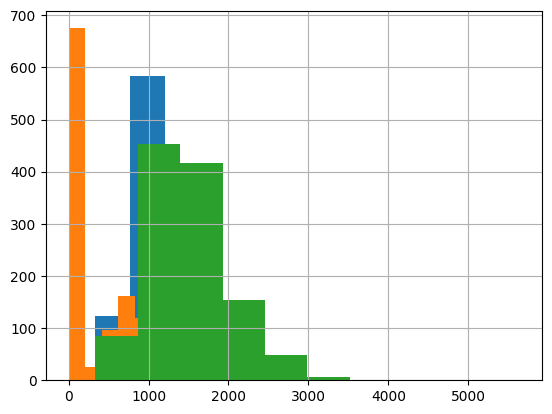

In [73]:
train_data_engineered_features["1stFlrSF"].hist()
train_data_engineered_features["2ndFlrSF"].hist()
train_data_engineered_features["GrLivArea"].hist()

In [74]:
# I think I will use above ground and not look at basement sq footage at all
train_data_engineered_features.drop(columns=["1stFlrSF", "2ndFlrSF", "LowQualFinSF"], inplace=True)

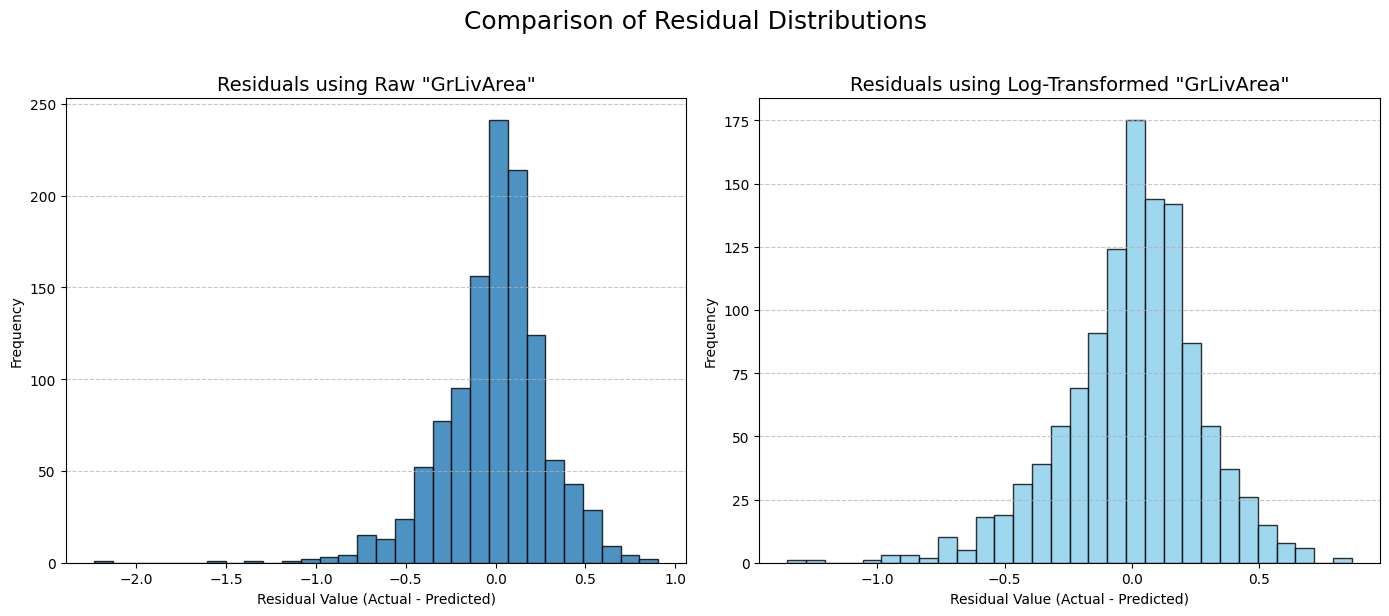

In [75]:
plot_residuals_single_feature(train_data_engineered_features["GrLivArea"], np.log(trainData["SalePrice"]))
# log looks better so 
train_data_engineered_features["LogAboveGroundLivingArea"] = np.log(train_data_engineered_features["GrLivArea"])
train_data_engineered_features.drop(columns=["GrLivArea"], inplace=True)

In [76]:
print(train_data_engineered_features["BsmtFullBath"].value_counts(normalize=True))
# feature for basement in bathroom maybe? will drop afraid of correaltion with having one
train_data_engineered_features.drop(columns=["BsmtFullBath", "BsmtHalfBath"], inplace=True)

BsmtFullBath
0    0.588689
1    0.401028
2    0.009426
3    0.000857
Name: proportion, dtype: float64


In [77]:
train_data_engineered_features["NumBathrooms"] = train_data_engineered_features["FullBath"] + 0.5 * train_data_engineered_features["HalfBath"]
train_data_engineered_features.drop(columns=["HalfBath", "FullBath"], inplace=True)

In [78]:
print(train_data_engineered_features["Bedroom"].value_counts(normalize=True))

Bedroom
3    0.560411
2    0.244216
4    0.141388
1    0.030848
5    0.016281
0    0.003428
6    0.003428
Name: proportion, dtype: float64


In [79]:
# these seem problematic with correlations (livable space, etc):
train_data_engineered_features.drop(columns=["Kitchen", "TotRmsAbvGrd", "Functional", "FireplaceQu"], inplace=True)

In [80]:
train_data_engineered_features["hasFirePlace"] = (train_data_engineered_features["Fireplaces"] > 0).astype(int)
train_data_engineered_features.drop(columns=["Fireplaces"], inplace=True)

In [81]:
print(train_data_engineered_features["GarageType"].value_counts(normalize=True))
# good categories seem refercne garage, attached and detached and built in
train_data_engineered_features["NoGarageFromAttachedGarageReference"] = (train_data_engineered_features["GarageType"] == "NA").astype(int)
train_data_engineered_features["DetachedGarageFromAttachedGarageReference"] = (train_data_engineered_features["GarageType"] == "Detchd").astype(int)
train_data_engineered_features["BuiltInOrBasementOrCarPortOr2TypesGarageFromAttachedGarageReference"] = (train_data_engineered_features["GarageType"].isin(["BuiltIn", "2Types", "CarPort", "Basment"])).astype(int)
train_data_engineered_features.drop(columns=["GarageType"], inplace=True)

GarageType
Attchd     0.599829
Detchd     0.252785
BuiltIn    0.060840
NA         0.059126
Basment    0.014567
CarPort    0.007712
2Types     0.005141
Name: proportion, dtype: float64


In [82]:
# other garage that may be correlated
train_data_engineered_features.drop(columns=["GarageYrBlt", "GarageFinish", "GarageCars",  "GarageArea", "GarageQual", "GarageCond"], inplace=True)

In [83]:
print(train_data_engineered_features["PavedDrive"].value_counts(normalize=True))
# okay at 8% minority
train_data_engineered_features["isFullyPavedDriveway"] = (train_data_engineered_features["PavedDrive"] == "Y").astype(int)
train_data_engineered_features.drop(columns=["PavedDrive"], inplace=True)

PavedDrive
Y    0.916024
N    0.060840
P    0.023136
Name: proportion, dtype: float64


In [84]:
print((train_data_engineered_features["WoodDeckSF"] > 0).mean())
# can make hasWoodDeck
train_data_engineered_features["hasWoodDeck"] = (train_data_engineered_features["WoodDeckSF"] > 0).astype(int)
train_data_engineered_features.drop(columns=["WoodDeckSF"], inplace=True)


0.48414738646101113


In [85]:
print((train_data_engineered_features["OpenPorchSF"] > 0).mean())
# can make hasOpenPorch
train_data_engineered_features["hasOpenPorch"] = (train_data_engineered_features["OpenPorchSF"] > 0).astype(int)
train_data_engineered_features.drop(columns=["OpenPorchSF"], inplace=True)

0.5475578406169666


In [86]:
print((train_data_engineered_features["EnclosedPorch"] > 0).mean())
# can make hasEnclosedPorch
train_data_engineered_features["hasEnclosedPorch"] = (train_data_engineered_features["EnclosedPorch"] > 0).astype(int)
train_data_engineered_features.drop(columns=["EnclosedPorch"], inplace=True)

0.14481576692373607


In [87]:
print((train_data_engineered_features["3SsnPorch"] > 0).mean())
# dropping
train_data_engineered_features.drop(columns=["3SsnPorch"], inplace=True)

0.01713796058269066


In [88]:
print((train_data_engineered_features["ScreenPorch"] > 0).mean())
# can make hasScreenPorch
train_data_engineered_features["hasScreenPorch"] = (train_data_engineered_features["ScreenPorch"] > 0).astype(int)
train_data_engineered_features.drop(columns=["ScreenPorch"], inplace=True)

0.07455012853470437


In [89]:
print((train_data_engineered_features["PoolArea"] > 0).mean())
# too small
train_data_engineered_features.drop(columns=["PoolArea", "PoolQC"], inplace=True)

0.005998286203941731


In [90]:
print(train_data_engineered_features["Fence"].value_counts(normalize=True))
# has fence
train_data_engineered_features["hasFence"] = (train_data_engineered_features["Fence"] != "NA").astype(int)
train_data_engineered_features.drop(columns=["Fence"], inplace=True)

Fence
NA       0.804627
MnPrv    0.110540
GdPrv    0.040274
GdWo     0.035990
MnWw     0.008569
Name: proportion, dtype: float64


In [91]:
# sparse high cardinality columns / irrelevant for interpretation
train_data_engineered_features.drop(columns=["MiscFeature", "MiscVal", "MoSold", "SaleType", "SaleCondition", "Id"], inplace=True)

I think ill leave this in perhaps as a way to capture year over year growth


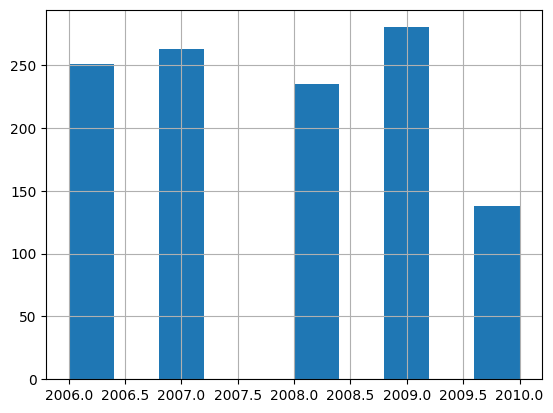

In [92]:
train_data_engineered_features["YrSold"].hist()
print("I think ill leave this in perhaps as a way to capture year over year growth")

In [93]:
train_data_engineered_features.drop(columns=["KitchenQual", "SalePrice"], inplace=True)

In [94]:
# phew thats a lot of feature engineering, so we now have
print(train_data_engineered_features.shape)
train_data_engineered_features.columns

(1167, 63)


Index(['LotFrontage', 'LotArea', 'OverallQual', 'Bedroom', 'YrSold', 'isPUD',
       'MSZoning_is_residential_high_density_or_commercial_from_residential_low_density',
       'MsZoning_is_floating_village_residential_from_residential_low_density',
       'MSZoning_is_residential_medium_density_from_residential_low_densit',
       'LotFrontage_IsMissing', 'HasAlley', 'isIrregularLotShape',
       'isBankedFromLevelCountour', 'isLowOrHighSlopeFromLevelCountour',
       'isCornerLotFromInsideLotReference',
       'isCulDSacLotFromInsideLotReference',
       'isFrontageOn2Or3RoadsFromInsideLotReference',
       'isTier2MidValueNeighborhoodFromTier3LowValueNeighborhoodReference',
       'isTier1HighValueNeighborhoodFromTier3LowValueNeighborhoodReference',
       'AdjacentToArterialStreet', 'AdjacentToFeederStreet',
       'isNotNormalProximity', 'isNearRailRoad',
       'isNearPositiveOffsiteFeature', 'is2or2.5StoryFrom1StoryReference',
       'is1.5StoryFrom1StoryReference',
       'isSpli

(array([  1.,   3.,   3.,   5.,  24., 192., 556., 322.,  48.,  13.]),
 array([-0.99274705, -0.84318922, -0.6936314 , -0.54407357, -0.39451574,
        -0.24495791, -0.09540009,  0.05415774,  0.20371557,  0.35327339,
         0.50283122]),
 <BarContainer object of 10 artists>)

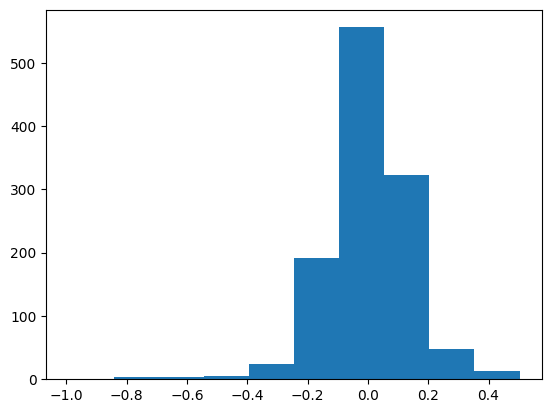

In [95]:
modelWithEngineeredFeatures = LinearRegression()
modelWithEngineeredFeatures.fit(train_data_engineered_features, np.log(trainData["SalePrice"]))
res = np.log(trainData["SalePrice"]) - modelWithEngineeredFeatures.predict(train_data_engineered_features)
plt.hist(res)

In [96]:
import statsmodels.api as sm

X_train_with_const = sm.add_constant(train_data_engineered_features, prepend=True)

X_train_with_const.head()
ols_model = sm.OLS(np.log(trainData["SalePrice"]), X_train_with_const)
results = ols_model.fit()

# Print the comprehensive summary table
print("\n\n--- OLS Regression Results Summary ---")
print(results.summary())



--- OLS Regression Results Summary ---
                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.883
Model:                            OLS   Adj. R-squared:                  0.877
Method:                 Least Squares   F-statistic:                     132.4
Date:                Fri, 10 Oct 2025   Prob (F-statistic):               0.00
Time:                        15:30:19   Log-Likelihood:                 671.92
No. Observations:                1167   AIC:                            -1216.
Df Residuals:                    1103   BIC:                            -891.9
Df Model:                          63                                         
Covariance Type:            nonrobust                                         
                                                                                                                                                                        c

In [97]:
# lets layer vif filtering on top of this
from numpy import inf
from statsmodels.stats.outliers_influence import variance_inflation_factor

def remove_high_vif_features(training_features: pd.DataFrame, max_vif: float):
    highest_vif = inf
    removed = []
    while highest_vif > max_vif:
        numpy_features = training_features.to_numpy()
        features_with_const = sm.add_constant(numpy_features, prepend=True)
        vifs = np.array([variance_inflation_factor(features_with_const, i + 1) for i in range(numpy_features.shape[1])])
        feature_index_with_highest_vif = np.argmax(vifs)
        if vifs[feature_index_with_highest_vif] > max_vif:
            column_name_highest_vif = training_features.columns[feature_index_with_highest_vif]
            training_features = training_features.drop(columns=[column_name_highest_vif])
            removed.append(column_name_highest_vif)
        highest_vif = vifs[feature_index_with_highest_vif]
    return training_features, removed

training_features, removed = remove_high_vif_features(train_data_engineered_features, max_vif=1.005)

In [98]:
training_features.shape

(1167, 7)

In [99]:
import statsmodels.api as sm

X_train_with_const = sm.add_constant(training_features, prepend=True)

X_train_with_const.head()
ols_model = sm.OLS(np.log(trainData["SalePrice"]), X_train_with_const)
results = ols_model.fit()

# Print the comprehensive summary table
print("\n\n--- OLS Regression Results Summary ---")
print(results.summary())



--- OLS Regression Results Summary ---
                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.092
Model:                            OLS   Adj. R-squared:                  0.086
Method:                 Least Squares   F-statistic:                     16.76
Date:                Fri, 10 Oct 2025   Prob (F-statistic):           3.58e-21
Time:                        15:30:28   Log-Likelihood:                -524.73
No. Observations:                1167   AIC:                             1065.
Df Residuals:                    1159   BIC:                             1106.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                                                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------

In [100]:
# got an acceptable condition number (< 10 which means these are independent), and focusing on the low p-value (up to 0.01):

import pandas as pd
import numpy as np
import statsmodels.api as sm

def interpret_regression_model(results, 
                               is_y_log_transformed=False, 
                               alpha=0.05):
    """
    Generates human-readable interpretations for each coefficient in a fitted
    statsmodels OLS regression model.

    Args:
        results (statsmodels.regression.linear_model.RegressionResultsWrapper): 
            The fitted model results object from `sm.OLS(y, X).fit()`.
            
        is_y_log_transformed (bool): 
            Set to True if the dependent variable (y) was log-transformed. 
            This is crucial for correct interpretation. Defaults to False.
            
        alpha (float): 
            The significance level to determine if a coefficient is statistically 
            significant. Defaults to 0.05.
            
        dummy_metadata (dict): 
            A dictionary to provide context for dummy variables.
            - Keys: The column name of the dummy variable in the model.
            - Values: A dictionary with keys 'original_feature', 'this_category', 
                      and 'reference_category'.
            Example: 
            {
                'isTier1HighValueNeighborhoodFromTier3LowValueNeighborhoodReference': {
                    'original_feature': 'Neighborhood',
                    'this_category': 'Tier 1 (High Value)',
                    'reference_category': 'Tier 3 (Lower Value)'
                }
            }
    """
    
    # --- 1. Overall Model Summary ---
    y_name = results.model.endog_names
    r_squared = results.rsquared_adj
    cond_no = results.condition_number
    
    print("--- Overall Model Interpretation ---")
    print(f"The model aims to explain '{y_name}' {'(on a log scale)' if is_y_log_transformed else ''}.")
    print(f"Adjusted R-squared: {r_squared:.3f}. This model explains approximately {r_squared:.1%} of the variance in '{y_name}'.")
    if cond_no > 30:
        print(f"\nWARNING: The Condition Number is {cond_no:.1f}, indicating strong multicollinearity. "
              "Individual coefficient interpretations should be made with extreme caution as they may be unstable.\n")
    
    print("\n--- Interpretation of Individual Coefficients ---")

    # --- 2. Loop Through Each Coefficient ---
    for coef_name, coef_val in results.params.items():
        if coef_name.lower() == 'const':
            continue # Skip the intercept for individual interpretation

        p_value = results.pvalues[coef_name]
        conf_int = results.conf_int(alpha=alpha).loc[coef_name]
        is_significant = p_value < alpha
        
        print(f"\n--- Feature: {coef_name} ---")
    

        # --- 4. Generate Interpretation String ---
        interpretation = ""
        
        # A. Handle Dummy Variables if metadata is provided

        interpretation += (f"Variable: {coef_name}\n")

        if is_y_log_transformed:
            # Log-Level interpretation for dummy
            pct_change = (np.exp(coef_val) - 1) * 100
            direction = "increase" if pct_change > 0 else "decrease"
            interpretation += (f"  Effect: Associated with an average {abs(pct_change):.1f}% {direction} in '{y_name}'.")
        else:
            # Level-Level interpretation for dummy
            direction = "increase" if coef_val > 0 else "decrease"
            interpretation += (f"  Effect: Associated with an average {abs(coef_val):,.0f} unit {direction} in '{y_name}'.")
        
        print(interpretation)

        if is_significant:
            print(f"  Significance: This result is statistically significant (p = {p_value:.3f}).")
        else:
            print(f"  Significance: This result is NOT statistically significant (p = {p_value:.3f}).")

interpret_regression_model(
    results=results, 
    is_y_log_transformed=True, 
    alpha=0.05, 
)

--- Overall Model Interpretation ---
The model aims to explain 'SalePrice' (on a log scale).
Adjusted R-squared: 0.086. This model explains approximately 8.6% of the variance in 'SalePrice'.



--- Interpretation of Individual Coefficients ---

--- Feature: YrSold ---
Variable: YrSold
  Effect: Associated with an average 1.0% decrease in 'SalePrice'.
  Significance: This result is NOT statistically significant (p = 0.225).

--- Feature: isLowOrHighSlopeFromLevelCountour ---
Variable: isLowOrHighSlopeFromLevelCountour
  Effect: Associated with an average 20.6% increase in 'SalePrice'.
  Significance: This result is statistically significant (p = 0.000).

--- Feature: AdjacentToFeederStreet ---
Variable: AdjacentToFeederStreet
  Effect: Associated with an average 18.9% decrease in 'SalePrice'.
  Significance: This result is statistically significant (p = 0.000).

--- Feature: isUnfinishedFrom1StoryReference ---
Variable: isUnfinishedFrom1StoryReference
  Effect: Associated with an averag

In [105]:
new_data_point = pd.DataFrame([{
    'const': 1.0,
    'YrSold': 1990,
    'isLowOrHighSlopeFromLevelCountour': 0,
    'AdjacentToFeederStreet': 0,
    'isUnfinishedFrom1StoryReference': 0,
    'isSlabOrStoneOrWoodFoundationFromReferencePouredConcreteFoundation': 1,
    'BuiltInOrBasementOrCarPortOr2TypesGarageFromAttachedGarageReference':1,
    "hasScreenPorch": 1
}])
new_pred_results = results.get_prediction(new_data_point)

new_pred_summary = new_pred_results.summary_frame(alpha=0.05)

new_pred_summary['predicted_price'] = np.exp(new_pred_summary['mean'])
new_pred_summary['predicted_price_ul'] = np.exp(new_pred_summary['obs_ci_upper'])
new_pred_summary['predicted_price_ll'] = np.exp(new_pred_summary['obs_ci_lower'])
new_pred_summary

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper,predicted_price,predicted_price_ul,predicted_price_ll
0,12.079799,0.177933,11.730693,12.428905,11.255382,12.904217,176274.762307,402003.792303,77294.772888


In [106]:
# practically useless (73k to 351k) confidence interval
# in line with 8% variance explained in responses for the model on the training data.
# so poor predictive power traded off to understand independent effect of the features.

Univariate regression answers:

"What is the gross association between this one feature and SalePrice, ignoring every other factor in the universe?"

The goal of interpretation is almost always to understand the independent contribution of a feature. We want to answer the question:

"Holding all other relevant factors constant, what is the specific effect of this one feature on SalePrice?"

Univariate regression cannot answer this question. By ignoring other relevant variables, its coefficient for a feature gets contaminated by the effects of all the other variables it's correlated with.

### Inference Performance
For inference performance, we will use sci kit learn's libraries as an industry standard.

Inference performance specifically means we seek to optimize the performance of the model on unseen data.

Here we will start with a validation pipeline we can feed a model into (that performs K fold validation on the dataset).

Then we can hyper parameter tune and adjust as needed.

For interpretability we did not use a separate "test" set because the goal there was to understand feature impact (and reducing the samples means we have less reliable estimates) but for inference performance the goal is to understand and optimize generalization error.

#### Note on thought process
I am considering two options:
1. Keep the heavily engineered features. (~80)
2. Use more "RAW" features. (~220)

If I do 1, it may help the model generalize well as the features are already filtered and transformed so there's a balance and better fit with model assumptions (linearity), however my feature engineering may not be optimal, and my manual effort may miss out on some features.

If I do 2, I will have to rely on the regularization (like L1 or elastic net) to zero out unhelpful features, and the model may struggle to do this sort of filtering on it's own.

But here we can do both and use Cross-Validation to guide us.

In [116]:
# we will use RandomizedSearchCV on the already processed primitives (heavily engineered and raw features)
from sklearn.model_selection import RandomizedSearchCV
# for the sake log(y) we need to convert back to raw scale to measure error on same scale
from sklearn.metrics import root_mean_squared_error

def hyperParameterSearch(parameter_distributions, model, x, y):
    searcher = RandomizedSearchCV(
        estimator=model,
        param_distributions=parameter_distributions,
        n_iter=1000,  
        cv=5,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
        verbose=1,
    )
    searcher.fit(x, y)
    return searcher

def getScoreLogYInRawForm(model, x, y):
    log_y_predictions = model.predict(x)
    y_pred = np.exp(log_y_predictions)

    return root_mean_squared_error(y, y_pred)

### Let's look at lasso with our variants

In [125]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from scipy.linalg import LinAlgWarning

# Ignore ConvergenceWarning
warnings.filterwarnings("ignore", category = ConvergenceWarning)
warnings.filterwarnings("ignore", category = LinAlgWarning)
# doing this as in certain cases we see failure to converge - thats okay we are looking for inference performance

In [120]:
### Lasso Raw Input Raw Output
from scipy.stats import loguniform
from sklearn.linear_model import Lasso


param_distributions = {
    'alpha': loguniform(0.0000001, 1000), 
}

estimator = hyperParameterSearch(param_distributions, Lasso(tol=0.01), trainDfEncoded.drop(columns=["SalePrice"]).to_numpy(), trainDfEncoded["SalePrice"].to_numpy())
estimator.best_params_, estimator.best_score_

Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


({'alpha': np.float64(142.02648315213105)}, np.float64(-33673.91844923685))

In [121]:
### Lasso Feature Engineered Input Raw Output
from scipy.stats import loguniform
from sklearn.linear_model import Lasso


param_distributions = {
    'alpha': loguniform(0.0000001, 1000), 
}

estimator = hyperParameterSearch(param_distributions, Lasso(), train_data_engineered_features.to_numpy(), trainDfEncoded["SalePrice"].to_numpy())


estimator.best_params_, estimator.best_score_

Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


({'alpha': np.float64(100.35510283473964)}, np.float64(-35022.22252850664))

In [122]:
### Lasso Raw Input Log output
from scipy.stats import loguniform
from sklearn.linear_model import Lasso


param_distributions = {
    'alpha': loguniform(0.0000001, 1000), 
}

estimator = hyperParameterSearch(param_distributions, Lasso(), trainDfEncoded.drop(columns=["SalePrice"]).to_numpy(), np.log(trainDfEncoded["SalePrice"].to_numpy()))
estimator.best_params_, getScoreLogYInRawForm(estimator, trainDfEncoded.drop(columns=["SalePrice"]).to_numpy(), trainDfEncoded["SalePrice"].to_numpy())

Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


({'alpha': np.float64(0.0005794432868218925)}, 26287.916818504058)

In [ ]:
### Lasso Feature Engineered Input Log output
from scipy.stats import loguniform
from sklearn.linear_model import Lasso


param_distributions = {
    'alpha': loguniform(0.0000001, 1000), 
}

estimator = hyperParameterSearch(param_distributions, Lasso(), train_data_engineered_features.to_numpy(), np.log(trainDfEncoded["SalePrice"].to_numpy()))
estimator.best_params_, getScoreLogYInRawForm(estimator, train_data_engineered_features.to_numpy(), trainDfEncoded["SalePrice"].to_numpy())

Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


({'alpha': np.float64(0.0002579233786320665)}, 31517.634002748175)

In [123]:
### Lasso Standardized Raw Input Raw Output
from scipy.stats import loguniform
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler


param_distributions = {
    'alpha': loguniform(0.0000001, 1000), 
}

scaler = StandardScaler()
scaler.fit(trainDfEncoded.drop(columns=["SalePrice"]).to_numpy())

estimator = hyperParameterSearch(param_distributions, Lasso(), scaler.transform(trainDfEncoded.drop(columns=["SalePrice"]).to_numpy()), trainDfEncoded["SalePrice"].to_numpy())
estimator.best_score_, estimator.best_params_

Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


(np.float64(-35330.33995953172), {'alpha': np.float64(988.0813240037022)})

In [ ]:
### Lasso Standardized Feature Engineered Input Raw Output
from scipy.stats import loguniform
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler


param_distributions = {
    'alpha': loguniform(0.0000001, 1000), 
}

scaler = StandardScaler()
scaler.fit(train_data_engineered_features.to_numpy())

estimator = hyperParameterSearch(param_distributions, Lasso(), scaler.transform(train_data_engineered_features.to_numpy()), trainDfEncoded["SalePrice"].to_numpy())
estimator.best_score_, estimator.best_params_

Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


(np.float64(-38197.5463301748), {'alpha': np.float64(400.55059102545175)})

In [ ]:
### Lasso Standardized Feature Engineered Input Log output
from scipy.stats import loguniform
from sklearn.linear_model import Lasso


param_distributions = {
    'alpha': loguniform(0.0000001, 1000), 
}

scaler = StandardScaler()
scaler.fit(train_data_engineered_features.to_numpy())

estimator = hyperParameterSearch(param_distributions, Lasso(), scaler.transform(train_data_engineered_features.to_numpy()), np.log(trainDfEncoded["SalePrice"].to_numpy()))
estimator.best_params_, getScoreLogYInRawForm(estimator, scaler.transform(train_data_engineered_features.to_numpy()), trainDfEncoded["SalePrice"].to_numpy())

Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


({'alpha': np.float64(0.001282176765370606)}, 31575.767309143266)

In [124]:
### Lasso Standard Raw Input Log output
from scipy.stats import loguniform
from sklearn.linear_model import Lasso


param_distributions = {
    'alpha': loguniform(0.0000001, 1000), 
}

scaler = StandardScaler()
scaler.fit(trainDfEncoded.drop(columns=["SalePrice"]).to_numpy())

estimator = hyperParameterSearch(param_distributions, Lasso(), scaler.transform(trainDfEncoded.drop(columns=["SalePrice"]).to_numpy()), np.log(trainDfEncoded["SalePrice"].to_numpy()))
estimator.best_params_, getScoreLogYInRawForm(estimator, scaler.transform(trainDfEncoded.drop(columns=["SalePrice"]).to_numpy()), trainDfEncoded["SalePrice"].to_numpy())

Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


({'alpha': np.float64(0.0047128224052628495)}, 25678.455034559094)

For lasso regularization Log-Level and Standardized feature engineered X  gives us an optimal 31k root mean squared error CV score.

ridge regression tests

In [126]:
### Ridge Raw Input Raw Output
from scipy.stats import loguniform
from sklearn.linear_model import Ridge


param_distributions = {
    'alpha': loguniform(0.0000001, 1000), 
}

estimator = hyperParameterSearch(param_distributions, Ridge(), trainDfEncoded.drop(columns=["SalePrice"]).to_numpy(), trainDfEncoded["SalePrice"].to_numpy())
estimator.best_params_, estimator.best_score_

Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


({'alpha': np.float64(8.409433973077176)}, np.float64(-33292.89555376609))

In [ ]:
### Ridge Feature Engineered Input Raw Output
from scipy.stats import loguniform
from sklearn.linear_model import Ridge


param_distributions = {
    'alpha': loguniform(0.0000001, 1000), 
}

estimator = hyperParameterSearch(param_distributions, Ridge(), train_data_engineered_features.to_numpy(), trainDfEncoded["SalePrice"].to_numpy())


estimator.best_params_, estimator.best_score_

Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


({'alpha': np.float64(4.202439239916541)}, np.float64(-38376.65508132142))

In [127]:
### Ridge Raw Input Log output
from scipy.stats import loguniform
from sklearn.linear_model import Ridge


param_distributions = {
    'alpha': loguniform(0.0000001, 1000), 
}

estimator = hyperParameterSearch(param_distributions, Ridge(), trainDfEncoded.drop(columns=["SalePrice"]).to_numpy(), np.log(trainDfEncoded["SalePrice"].to_numpy()))
estimator.best_params_, getScoreLogYInRawForm(estimator, trainDfEncoded.drop(columns=["SalePrice"]).to_numpy(), trainDfEncoded["SalePrice"].to_numpy())

Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


({'alpha': np.float64(6.559444425504935)}, 23527.399888247506)

In [ ]:
### Ridge Feature Engineered Input Log output
from scipy.stats import loguniform
from sklearn.linear_model import Ridge


param_distributions = {
    'alpha': loguniform(0.0000001, 1000), 
}

estimator = hyperParameterSearch(param_distributions, Ridge(), train_data_engineered_features.to_numpy(), np.log(trainDfEncoded["SalePrice"].to_numpy()))
estimator.best_params_, getScoreLogYInRawForm(estimator, train_data_engineered_features.to_numpy(), trainDfEncoded["SalePrice"].to_numpy())

Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


({'alpha': np.float64(2.5458527126305674)}, 31499.97709161996)

In [ ]:
### Ridge Standardized Raw Input Raw Output
from scipy.stats import loguniform
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler


param_distributions = {
    'alpha': loguniform(0.0000001, 1000), 
}

scaler = StandardScaler()
scaler.fit(trainDfEncoded.drop(columns=["SalePrice"]).to_numpy())

estimator = hyperParameterSearch(param_distributions, Ridge(), scaler.transform(trainDfEncoded.drop(columns=["SalePrice"]).to_numpy()), trainDfEncoded["SalePrice"].to_numpy())
estimator.best_score_, estimator.best_params_

Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


(np.float64(-34885.41125440002), {'alpha': np.float64(552.866924937604)})

In [ ]:
### Ridge Standardized Feature Engineered Input Raw Output
from scipy.stats import loguniform
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler


param_distributions = {
    'alpha': loguniform(0.0000001, 1000), 
}

scaler = StandardScaler()
scaler.fit(train_data_engineered_features.to_numpy())

estimator = hyperParameterSearch(param_distributions, Ridge(), scaler.transform(train_data_engineered_features.to_numpy()), trainDfEncoded["SalePrice"].to_numpy())
estimator.best_score_, estimator.best_params_

Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


(np.float64(-38241.9034188356), {'alpha': np.float64(70.66644889798508)})

In [ ]:
### Ridge Standardized Feature Engineered Input Log output
from scipy.stats import loguniform
from sklearn.linear_model import Ridge


param_distributions = {
    'alpha': loguniform(0.0000001, 1000), 
}

scaler = StandardScaler()
scaler.fit(train_data_engineered_features.to_numpy())

estimator = hyperParameterSearch(param_distributions, Ridge(), scaler.transform(train_data_engineered_features.to_numpy()), np.log(trainDfEncoded["SalePrice"].to_numpy()))
estimator.best_params_, getScoreLogYInRawForm(estimator, scaler.transform(train_data_engineered_features.to_numpy()), trainDfEncoded["SalePrice"].to_numpy())

Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


({'alpha': np.float64(17.75760444432037)}, 31487.8440744778)

In [ ]:
### Ridge Standard Raw Input Log output
from scipy.stats import loguniform
from sklearn.linear_model import Ridge


param_distributions = {
    'alpha': loguniform(0.0000001, 1000), 
}

scaler = StandardScaler()
scaler.fit(trainDfEncoded.drop(columns=["SalePrice"]).to_numpy())

estimator = hyperParameterSearch(param_distributions, Ridge(), scaler.transform(trainDfEncoded.drop(columns=["SalePrice"]).to_numpy()), np.log(trainDfEncoded["SalePrice"].to_numpy()))
estimator.best_params_, getScoreLogYInRawForm(estimator, scaler.transform(trainDfEncoded.drop(columns=["SalePrice"]).to_numpy()), trainDfEncoded["SalePrice"].to_numpy())

Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


({'alpha': np.float64(464.28292595765123)}, 26097.941957627525)

For ridge it looks like for log output, raw input, gets us the best score at 26k.

Lasso did better with feature engineering which kind of makes sense as the features where more meaningful and therefore easier to understand what to zero out.

Log output improved CV score - this is likely because it has a regularizing effect on the output scale, and:

Finding best Ridge model for Raw SalePrice...
Best alpha for raw Y model: 514.1097

Finding best Ridge model for log(SalePrice)...
Best alpha for log Y model: 500.1480


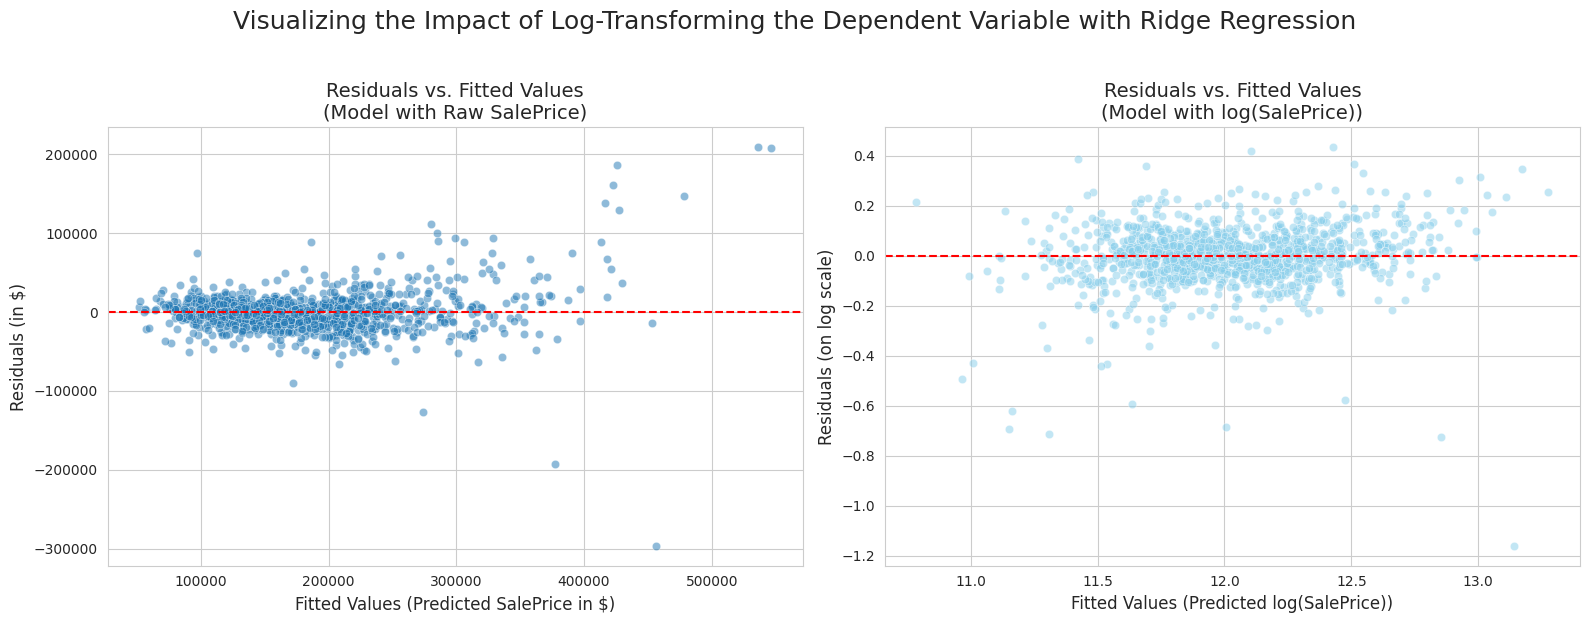

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV # Assuming hyperParameterSearch uses this
from scipy.stats import loguniform

# --- Step 1: Prepare Data and Models ---

# Define your features and both target variables
X = trainDfEncoded.drop(columns=["SalePrice"])
y_raw = trainDfEncoded["SalePrice"]
y_log = np.log(y_raw)

# --- A) MODEL FOR RAW Y: We need to find the best Ridge model for raw SalePrice ---
# This ensures a fair comparison by using an optimized model for the "before" case.
print("Finding best Ridge model for Raw SalePrice...")
scaler_raw = StandardScaler()
X_scaled_raw = scaler_raw.fit_transform(X)
param_distributions_raw = {'alpha': loguniform(1e-2, 1e4)}
# Assuming hyperParameterSearch is like RandomizedSearchCV
hyperParameterSearch_raw = RandomizedSearchCV(
    Ridge(), param_distributions_raw, n_iter=50, cv=5, random_state=42, scoring='neg_mean_squared_error'
)
hyperParameterSearch_raw.fit(X_scaled_raw, y_raw)
estimator_raw_y = hyperParameterSearch_raw.best_estimator_
print(f"Best alpha for raw Y model: {estimator_raw_y.alpha:.4f}")

# --- B) MODEL FOR LOG Y: This is the 'estimator' you already have from your code ---
print("\nFinding best Ridge model for log(SalePrice)...")
scaler_log = StandardScaler()
X_scaled_log = scaler_log.fit_transform(X) # Can use the same scaled data
param_distributions_log = {'alpha': loguniform(1e-7, 1e3)}
hyperParameterSearch_log = RandomizedSearchCV(
    Ridge(), param_distributions_log, n_iter=50, cv=5, random_state=42, scoring='neg_mean_squared_error'
)
hyperParameterSearch_log.fit(X_scaled_log, y_log)
estimator_log_y = hyperParameterSearch_log.best_estimator_ # This is equivalent to your 'estimator'
print(f"Best alpha for log Y model: {estimator_log_y.alpha:.4f}")


# --- Step 2: Get Fitted Values and Residuals for Both Models ---

# For the Raw Y Model
fitted_raw = estimator_raw_y.predict(X_scaled_raw)
residuals_raw = y_raw - fitted_raw

# For the Log Y Model
fitted_log = estimator_log_y.predict(X_scaled_log)
residuals_log = y_log - fitted_log


# --- Step 3: Create the side-by-side plots ---

# Set up the plot style
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Residuals vs. Fitted for the Raw Y Model
sns.scatterplot(x=fitted_raw, y=residuals_raw, ax=axes[0], alpha=0.5)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Residuals vs. Fitted Values\n(Model with Raw SalePrice)', fontsize=14)
axes[0].set_xlabel("Fitted Values (Predicted SalePrice in $)", fontsize=12)
axes[0].set_ylabel("Residuals (in $)", fontsize=12)

# Plot 2: Residuals vs. Fitted for the Log Y Model
sns.scatterplot(x=fitted_log, y=residuals_log, ax=axes[1], alpha=0.5, color='skyblue')
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Residuals vs. Fitted Values\n(Model with log(SalePrice))', fontsize=14)
axes[1].set_xlabel("Fitted Values (Predicted log(SalePrice))", fontsize=12)
axes[1].set_ylabel("Residuals (on log scale)", fontsize=12)

# Add a main title for the entire figure
fig.suptitle('Visualizing the Impact of Log-Transforming the Dependent Variable with Ridge Regression', fontsize=18, y=1.03)

# Adjust layout and show the plot
plt.tight_layout()
plt.show()

Residuals look more constant variance.


Standardizing before hand also tended to help and show improvements in ridge, though not as much in lasso - as expected more pronounced in ridge (since it's squared weights) versus absolute values.

In [128]:
# elasticNet scaled input, log output

from scipy.stats import loguniform, uniform
from sklearn.linear_model import ElasticNet


param_distributions = {
    'alpha': loguniform(1e-7, 1000),  # Overall regularization strength
    'l1_ratio': uniform(0, 1)        # The mix between L1 and L2 (from 0 to 1)
}

scaler = StandardScaler()
scaler.fit(trainDfEncoded.drop(columns=["SalePrice"]).to_numpy())

estimator = hyperParameterSearch(param_distributions, ElasticNet(), scaler.transform(trainDfEncoded.drop(columns=["SalePrice"]).to_numpy()), np.log(trainDfEncoded["SalePrice"].to_numpy()))
estimator.best_params_, getScoreLogYInRawForm(estimator, scaler.transform(trainDfEncoded.drop(columns=["SalePrice"]).to_numpy()), trainDfEncoded["SalePrice"].to_numpy())

Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


({'alpha': np.float64(0.3746205797623979),
  'l1_ratio': np.float64(0.013621401145406775)},
 28857.996168278136)

In [129]:
# final test set for our best performer:
from scipy.stats import loguniform
from sklearn.linear_model import Ridge


param_distributions = {
    'alpha': loguniform(0.0000001, 1000), 
}

estimator = hyperParameterSearch(param_distributions, Ridge(), trainDfEncoded.drop(columns=["SalePrice"]).to_numpy(), np.log(trainDfEncoded["SalePrice"].to_numpy()))
estimator.best_params_, getScoreLogYInRawForm(estimator, trainDfEncoded.drop(columns=["SalePrice"]).to_numpy(), trainDfEncoded["SalePrice"].to_numpy())


Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


({'alpha': np.float64(6.818304994695007)}, 23614.811485504535)

In [ ]:
# define pipeline 
preprocess_feature_engineer = Pipeline(
    steps= [
        ("clean_and_fix_data", FunctionTransformer(clean_and_fix_data)),
        ("encode_categorical", FunctionTransformer(encode_categorical, kw_args={"encoder": encoder, "categorical_features": categorical_features, "numerical_features": numerical_features})),
        ("lot_frontage_imputer", FunctionTransformer(lot_frontage_imputer, kw_args={"lot_frontage_regressor": lot_frontage_regressor, "columns_with_na": columns_with_na_original})),
        ('garage_age_feature_creator', FunctionTransformer(garage_age_feature_creator)),
        ("fill_na_mas_vnr_area_zero", FunctionTransformer(fill_na_mas_vnr_area_zero)),
        
    ]
)

# do transformations to get it
testDataEncoded = preprocess_feature_engineer.transform(testData)
testDataEncodedX = testDataEncoded.drop(columns=["SalePrice"])
testDataEncodedY = testDataEncoded["SalePrice"]
# run by best estimator
getScoreLogYInRawForm(estimator, testDataEncodedX.to_numpy(), testDataEncodedY.to_numpy())

/usr/local/lib/python3.10/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [11, 16, 17, 18, 19, 43] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


19581.839781706603

In [ ]:

getScoreLogYInRawForm(estimator, np.concat([testDataEncodedX, trainDfEncoded.drop(columns=["SalePrice"])]), np.concat([testDataEncodedY,trainDfEncoded["SalePrice"]]))

24758.121944994036

## High scale Training
For large datasets, we look at how our two methods (batch or stochastic gradient descent) and the analytical solution scale in terms of memory or compute time.


### Analytical Solution
For linear regression, the analytical solution $(X^TX)^{-1} X^T y$ has an overall memory complexity of:

$O(n \cdot p + p^2)$

And an overall time complexity of:

$O(n \cdot p^2 + p^3)$

### Stochastic or Batch Gradient Descent
Memory complexity of:
$ O(BatchSize \cdot p) $

Overall time complexity of:
$ O(NIter \cdot BatchSize \cdot p) $

### Thoughts
Theres some work done to bound the number of iterations for gradient descent but its not a simple polynomial that can be compared to analytical, however you can get a sense of when analytical won't work (particularly very large number of features as its cubic in that direction for time and quadratic for space). Particularly imagine 10,000 features, with perhaps 100,000 examples ~ TBs of memory required. In constrast this could be done with gradient based methods requiring memory in the MB scale.

### High Scale with Spark
To scale beyond the single machine set up, spark is the standard production grade technology. Here we will spin up a spark cluster and run a job to do gradient descent.

In [ ]:
# lets try a bigger dataset to see where sci-kit learn breaks
# https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf

In [ ]:
import os
import requests
from pathlib import Path
from tqdm import tqdm

def download_taxi_data(year=2022, months=range(1, 13)):
    """
    Downloads the NYC Yellow Taxi trip data for a given year and months.

    Args:
        year (int): The year of the data to download.
        months (iterable): An iterable of month numbers (e.g., range(1, 13) for all months).
    """
    BASE_URL = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata"
    
    # Create a directory to store the data, if it doesn't exist
    output_dir = Path('./.data/')
    output_dir.mkdir(exist_ok=True)
    
    print(f"Downloading data for year {year} into '{output_dir}' directory...")
    
    for month in months:
        # Format the month to be two digits (e.g., 01, 02, ..., 12)
        fmonth = f"{month:02d}"
        
        # Construct the full URL and the local file path
        url = f"{BASE_URL}_{year}-{fmonth}.parquet"
        file_path = output_dir / f"yellow_tripdata_{year}-{fmonth}.parquet"
        
        # Check if the file already exists to avoid re-downloading
        if file_path.exists():
            print(f"File {file_path.name} already exists. Skipping.")
            continue
            
        print(f"\nDownloading {file_path.name}...")
        
        try:
            # Make a streaming request to the URL
            response = requests.get(url, stream=True)
            response.raise_for_status()  # Raise an exception for bad status codes (4xx or 5xx)
            
            # Get the total file size from the headers
            total_size = int(response.headers.get('content-length', 0))
            
            # Use tqdm to create a progress bar
            with open(file_path, 'wb') as f, tqdm(
                desc=file_path.name,
                total=total_size,
                unit='iB',
                unit_scale=True,
                unit_divisor=1024,
            ) as bar:
                for data in response.iter_content(chunk_size=1024):
                    size = f.write(data)
                    bar.update(size)

        except requests.exceptions.RequestException as e:
            print(f"Error downloading {url}: {e}")
            # Clean up partially downloaded file if an error occurs
            if file_path.exists():
                os.remove(file_path)

    print("\nAll files downloaded successfully.")

In [ ]:
if __name__ == "__main__":
    # This will run when you execute the script from the command line
    download_taxi_data(year=2022)

yellow_tripdata_2022-01.parquet: 100%|██████████| 36.4M/36.4M [00:00<00:00, 40.2MiB/s]


yellow_tripdata_2022-02.parquet: 100%|██████████| 43.5M/43.5M [00:01<00:00, 41.7MiB/s]


yellow_tripdata_2022-03.parquet: 100%|██████████| 53.1M/53.1M [00:01<00:00, 42.6MiB/s]


yellow_tripdata_2022-04.parquet: 100%|██████████| 52.7M/52.7M [00:01<00:00, 43.1MiB/s]


yellow_tripdata_2022-05.parquet: 100%|██████████| 53.0M/53.0M [00:01<00:00, 43.6MiB/s]


yellow_tripdata_2022-06.parquet: 100%|██████████| 52.8M/52.8M [00:01<00:00, 42.7MiB/s]


... (3 outputs left out)

yellow_tripdata_2022-10.parquet: 100%|██████████| 54.4M/54.4M [00:01<00:00, 43.5MiB/s]


yellow_tripdata_2022-11.parquet: 100%|██████████| 47.8M/47.8M [00:01<00:00, 44.1MiB/s]


yellow_tripdata_2022-12.parquet: 100%|██████████| 51.2M/51.2M [00:01<00:00, 42.4MiB/s]


All files downloaded successfully.


In [ ]:
import pandas as pd
import numpy as np
import glob
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge

print("--- STARTING ULTIMATE FAILURE TEST: Loading 12 months of data ---")
print("!!! WARNING: This will consume all available RAM and SWAP. !!!")
print("!!! Your system will become unresponsive. This is expected. !!!")

try:
    # --- Step 1: Find all the parquet files we downloaded ---
    # This will look for all .parquet files in the 'taxi_data_2022' subdirectory
    path_to_data = './.data/*.parquet'
    all_files = glob.glob(path_to_data)
    
    if not all_files:
        raise FileNotFoundError("No parquet files found in 'taxi_data_2022'. Did you run the download script?")
        
    print(f"Found {len(all_files)} files to load.")

    # --- Step 2: Load and combine all files ---
    print("Loading and concatenating all files. This will take some time and memory...")
    list_of_dfs = [pd.read_parquet(f) for f in all_files]
    df = pd.concat(list_of_dfs, ignore_index=True)
    del list_of_dfs # Free up memory
    
    print(f"Successfully created combined DataFrame. Shape: {df.shape}")
    print("Memory usage of combined DataFrame:")
    df.info(memory_usage='deep')

    # --- Feature Engineering (same as before) ---
    print("\nStep 3: Performing feature engineering...")
    df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
    df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'])
    df['trip_duration'] = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds() / 60.0

    # Filter for realistic trips
    df = df[(df['trip_duration'] > 1) & (df['trip_duration'] < 60)]
    df = df[(df['trip_distance'] > 0) & (df['trip_distance'] < 50)]
    df.dropna(subset=['PULocationID', 'DOLocationID', 'passenger_count', 'trip_distance', 'trip_duration'], inplace=True)
    
    print(f"Shape after cleaning: {df.shape}")

    # --- Model Setup (same as before) ---
    y = df['trip_duration']
    X = df[['PULocationID', 'DOLocationID', 'passenger_count', 'trip_distance']]
    
    del df # Free up memory of the full DataFrame

    categorical_features = ['PULocationID', 'DOLocationID']
    numerical_features = ['passenger_count', 'trip_distance']

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_features),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
        ],
        remainder='drop'
    )

    model_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', Ridge(alpha=1.0))
    ])
    
    # --- THE GUARANTEED FAILURE POINT ---
    print("\nStep 4: Fitting the pipeline on the full year's dataset...")
    print("This will now attempt to allocate over 200 GB of virtual memory.")
    model_pipeline.fit(X, y)

    print("\n--- Succeeded (Impossible on this machine!) ---")

except MemoryError:
    print("\n--- FAILED AS EXPECTED! ---")
    print("A MemoryError was caught. The full year of data is far too large to be processed in memory.")
except Exception as e:
    # The OS might kill the process so forcefully that Python can't even catch a MemoryError.
    # In that case, the script just stops, and your terminal might say "Killed".
    print(f"\n--- AN ERROR OCCURRED OR PROCESS WAS KILLED: {type(e).__name__} ---")
    print("This is the expected outcome due to extreme memory pressure.")
    print(e)

--- STARTING ULTIMATE FAILURE TEST: Loading 12 months of data ---
!!! WARNING: This will consume all available RAM and SWAP. !!!
!!! Your system will become unresponsive. This is expected. !!!
Found 12 files to load.
Loading and concatenating all files. This will take some time and memory...
Successfully created combined DataFrame. Shape: (39656098, 19)
Memory usage of combined DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39656098 entries, 0 to 39656097
Data columns (total 19 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int64         
 8   DOLocationID           int64         
 9   payment_type   

: 

In [ ]:
# okay let's create a sample of the data

In [ ]:
from pyspark.sql import SparkSession
import os

spark = SparkSession.builder.appName("Sampler") \
    .master(f"spark://spark-master:7077") \
    .getOrCreate()

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/10/08 15:55:42 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [ ]:
full_dataset_path = f"./.data/*parquet"
full_df = spark.read.parquet(full_dataset_path)
full_df.count()

39656098

In [ ]:
# 39 million rows cool
# we will sample to get 40k for local pipeline prototyping

In [ ]:
sample_df = full_df.sample(fraction=0.001, seed=42)
sample_df.count()

39759

In [ ]:
sample_df.coalesce(1).write.mode("overwrite").option("header", "true").csv("./.data/sample.csv")

In [ ]:
import pandas as pd
import glob
file_path = glob.glob("./.data/sample.csv/*.csv")[0]
df_sample = pd.read_csv(file_path)

In [ ]:
df_sample.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
0,1,2022-01-01T01:18:08.000,2022-01-01T01:40:49.000,2.0,5.70,1.0,N,249,49,1,20.0,3.0,0.5,4.75,0.0,0.3,28.55,2.5,0.0
1,2,2022-01-01T01:28:57.000,2022-01-01T01:39:49.000,1.0,2.42,1.0,N,79,233,1,10.0,0.5,0.5,4.14,0.0,0.3,17.94,2.5,0.0
2,1,2022-01-01T01:17:49.000,2022-01-01T01:35:19.000,1.0,2.60,1.0,N,90,148,1,13.0,3.0,0.5,2.00,0.0,0.3,18.80,2.5,0.0
3,1,2022-01-01T01:18:09.000,2022-01-01T01:31:23.000,3.0,0.90,1.0,N,48,50,1,9.0,3.0,0.5,1.00,0.0,0.3,13.80,2.5,0.0
4,1,2022-01-01T02:29:31.000,2022-01-01T02:41:54.000,2.0,4.10,1.0,N,80,97,1,14.0,0.5,0.5,10.00,0.0,0.3,25.30,0.0,0.0


In [ ]:
# lets check for nas per feature
df_sample.describe()

,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
count,39759.000000,38375.000000,39759.000000,38375.000000,39759.000000,39759.000000,39759.000000,3.975900e+04,39759.000000,39759.000000,3.975900e+04,39759.000000,39759.000000,39759.000000,38375.000000,38375.000000
mean,1.720944,1.394163,3.506174,1.384469,165.078372,162.578661,1.193491,-1.103459e+03,1.015568,0.488941,1.121088e+03,0.555897,0.315861,21.726851,2.288404,0.095733
std,0.486212,0.961660,4.491675,5.461048,65.316916,70.443291,0.527776,2.229917e+05,1.267327,0.091646,2.229917e+05,2.086336,0.127626,18.132061,0.737235,0.335834
min,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,-4.446377e+07,-4.500000,-0.500000,-8.600000e-01,-11.750000,-1.000000,-250.300000,-2.500000,-1.250000
25%,1.000000,1.000000,1.100000,1.000000,132.000000,113.000000,1.000000,7.000000e+00,0.000000,0.500000,8.200000e-01,0.000000,0.300000,12.300000,2.500000,0.000000
50%,2.000000,1.000000,1.900000,1.000000,162.000000,162.000000,1.000000,1.050000e+01,0.500000,0.500000,2.160000e+00,0.000000,0.300000,15.960000,2.500000,0.000000
75%,2.000000,1.000000,3.560000,1.000000,234.000000,234.000000,1.000000,1.650000e+01,2.500000,0.500000,3.390000e+00,0.000000,0.300000,23.160000,2.500000,0.000000
max,6.000000,7.000000,75.790000,99.000000,265.000000,265.000000,4.000000,5.000000e+02,9.750000,0.800000,4.446379e+07,65.580000,1.000000,500.300000,2.500000,1.250000


In [ ]:
df_sample.isna().sum(axis=0)

VendorID                    0
tpep_pickup_datetime        0
tpep_dropoff_datetime       0
passenger_count          1384
trip_distance               0
RatecodeID               1384
store_and_fwd_flag       1384
PULocationID                0
DOLocationID                0
payment_type                0
fare_amount                 0
extra                       0
mta_tax                     0
tip_amount                  0
tolls_amount                0
improvement_surcharge       0
total_amount                0
congestion_surcharge     1384
airport_fee              1384
dtype: int64

In [ ]:
# let's identify a good response.
# vendor id is categorical for company managing the tracking system in the cab.
# tpep times are official times from the tracking system.
# passenger count is self explanatory.
# trip_distance is in miles
# RatecodeID rate code at END of the trip - different from just distance, perhaps flat charge or otherwise
# store_and_fwd_flag is whether or not was cached locally then sent or sent upon creation of record
# PU/DO location is pick up drop off ids
# fare_amount time and distance meter based
# tip cash not included
# other charges 

In [ ]:
# seems like fare amount seems the best option - total amount should just be a sum of others so we should remove it as well.
# let's split up our data properly
from sklearn.model_selection import train_test_split
df_sample, df_sample_test = train_test_split(df_sample, test_size=0.2)

In [ ]:
df_sample.shape, df_sample_test.shape

((31807, 19), (7952, 19))

In [ ]:
# VendorID seems irrelevant to the task so I will drop it
# as well as response and surcharges, taxes, payment type that may be leakage

from sklearn.pipeline import FunctionTransformer, Pipeline

def drop_columns(df):
    df_new = df.copy()
    df_new = df_new.drop(columns=["total_amount", "VendorID", "tip_amount", "tolls_amount", "payment_type", "extra", "mta_tax", "improvement_surcharge", "congestion_surcharge", "airport_fee"])
    return df_new

pipeline = Pipeline(steps=[
    ("dropper", FunctionTransformer(drop_columns))
])

In [ ]:
df_sample = pipeline.fit_transform(df_sample)

In [ ]:
df_sample.columns

Index(['tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count',
       'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID',
       'DOLocationID', 'fare_amount'],
      dtype='object')

In [ ]:
# lets handle tpep_pickup_datetime and tpep_dropoff_datetime, naturally time
df_sample_analysis = df_sample.copy()
df_sample_analysis["tpep_dropoff_datetime_converted"] = pd.to_datetime(df_sample_analysis['tpep_dropoff_datetime'])
df_sample_analysis["tpep_pickup_datetime_converted"] = pd.to_datetime(df_sample_analysis['tpep_pickup_datetime'])

In [ ]:
df_sample_analysis["trip_minutes"] = (df_sample_analysis["tpep_dropoff_datetime_converted"] - df_sample_analysis["tpep_pickup_datetime_converted"]).dt.total_seconds() / 60

In [ ]:
df_sample_analysis["trip_minutes"].describe()

count    31807.000000
mean        17.539643
std         52.270067
min         -0.583333
25%          7.383333
50%         12.250000
75%         19.933333
max       2345.166667
Name: trip_minutes, dtype: float64

<Axes: >

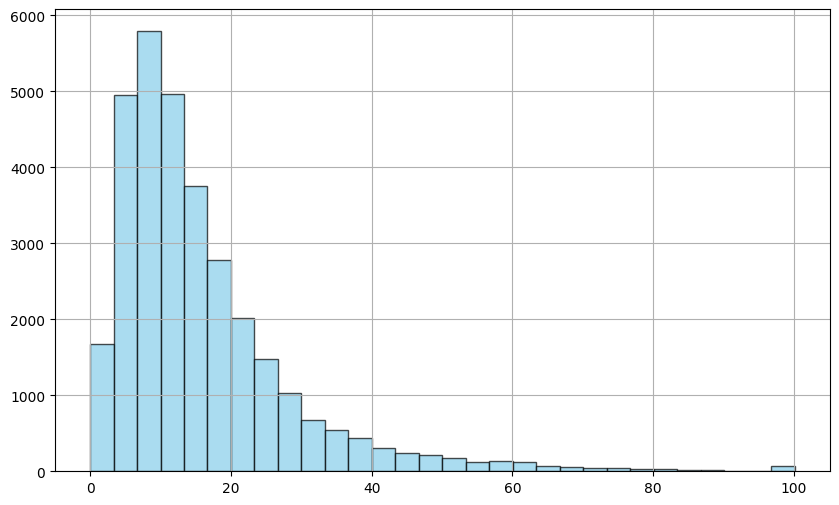

In [ ]:
# we want to drop impossible values and clip to some reasonable quantile
df_sample_analysis = df_sample_analysis[df_sample_analysis["trip_minutes"] >= 0].copy()
upper_threshold_duration = df_sample_analysis['trip_minutes'].quantile(0.998)

df_sample_analysis['trip_minutes'] = df_sample_analysis['trip_minutes'].clip(upper=upper_threshold_duration)

df_sample_analysis["trip_minutes"].hist(
    bins=30,         # Number of bins (adjust as needed)
    figsize=(10, 6),  # Figure size (width, height) in inches
    color='skyblue',   # Color of the bars
    edgecolor='black',  # Color of the bar edges
    alpha=0.7       # Transparency of the bars (0.0 to 1.0)
)


In [ ]:
df_sample.shape[0] - df_sample_analysis.shape[0]

6

In [ ]:
# lost 126 error rows - no big deal though
# let's now make into pipeline
def create_duration(df, upper_threshold):
    df_out = df.copy()
    df_out["tpep_dropoff_datetime_converted"] = pd.to_datetime(df_out['tpep_dropoff_datetime'])
    df_out["tpep_pickup_datetime_converted"] = pd.to_datetime(df_out['tpep_pickup_datetime'])
    df_out["trip_minutes"] = (df_out["tpep_dropoff_datetime_converted"] - df_out["tpep_pickup_datetime_converted"]).dt.total_seconds() / 60
    df_out = df_out[df_out["trip_minutes"] >= 0].copy()
    df_out['trip_minutes'] = df_out['trip_minutes'].clip(upper=upper_threshold)
    df_out = df_out.drop(columns=["tpep_dropoff_datetime_converted", "tpep_pickup_datetime_converted", "tpep_dropoff_datetime", "tpep_pickup_datetime"])
    return df_out

pipeline = Pipeline(steps=[
    ('create_dureation', FunctionTransformer(create_duration, kw_args={"upper_threshold": upper_threshold_duration}))
])
df_sample = pipeline.fit_transform(df_sample)

In [ ]:
df_sample.isna().sum()

passenger_count       1081
trip_distance            0
RatecodeID            1081
store_and_fwd_flag    1081
PULocationID             0
DOLocationID             0
fare_amount              0
trip_minutes             0
dtype: int64

In [ ]:
df_sample_analysis = df_sample.copy()
# passenger count
## imputation doesn't sound too bad for passenger to be honest - median.
df_sample_analysis["passenger_count"] = df_sample_analysis["passenger_count"].fillna(df_sample_analysis["passenger_count"].median())
df_sample_analysis["RatecodeID"] = df_sample_analysis["RatecodeID"].fillna(df_sample_analysis["RatecodeID"].mode()[0])
df_sample_analysis["store_and_fwd_flag"] = df_sample_analysis["store_and_fwd_flag"].fillna(df_sample_analysis["store_and_fwd_flag"].mode()[0])

In [ ]:
df_sample = df_sample_analysis
# as ref:

"""
1 = Standard rate
2 = JFK
3 = Newark
4 = Nassau or Westchester
5 = Negotiated fare
6 = Group ride
99 = Null/unknown
 """
df_sample_analysis["RatecodeID"].value_counts()

RatecodeID
1.0     30102
2.0      1211
5.0       251
3.0       105
99.0       95
4.0        37
Name: count, dtype: int64

In [ ]:
df_sample_analysis["store_and_fwd_flag"].value_counts()

store_and_fwd_flag
N    31405
Y      396
Name: count, dtype: int64

In [ ]:
pc_median = df_sample_analysis["passenger_count"].median()
rate_code_mode = df_sample_analysis["RatecodeID"].mode()[0]
store_and_fwd_mode = df_sample_analysis["store_and_fwd_flag"].mode()[0]

In [ ]:
def impute_values(df, pc_median, rate_code_mode, store_and_fwd_mode):
    df_out = df.copy()
    df_out["passenger_count"] = df_out["passenger_count"].fillna(pc_median)
    df_out["RatecodeID"] = df_out["RatecodeID"].fillna(rate_code_mode)
    df_out["store_and_fwd_flag"] = df_out["store_and_fwd_flag"].fillna(store_and_fwd_mode)
    return df_out

pipeline = Pipeline(
    steps= [
        ("impute_values", FunctionTransformer(impute_values, kw_args={'pc_median': pc_median, 'rate_code_mode': rate_code_mode, 'store_and_fwd_mode': store_and_fwd_mode}))
    ]
)
df_sample = pipeline.fit_transform(df_sample)

In [ ]:
df_sample["store_and_fwd_flag"].value_counts()

store_and_fwd_flag
N    31405
Y      396
Name: count, dtype: int64

In [ ]:
df_sample["trip_distance"].describe()

count    31801.000000
mean         3.512499
std          4.474950
min          0.000000
25%          1.100000
50%          1.900000
75%          3.590000
max         71.700000
Name: trip_distance, dtype: float64

In [ ]:
outlier = df_sample['trip_distance'].quantile(0.9999)
outlier

np.float64(52.80679999999513)

In [ ]:
def drop_outlier_milage(df, upper_threshold):
    return df[df["trip_distance"] <= upper_threshold].copy()

pipeline = Pipeline(
    steps= [
        ('drop_outlier_mileage', FunctionTransformer(drop_outlier_milage, kw_args={"upper_threshold": 100}))
    ]
)

df_sample = pipeline.fit_transform(df_sample)

In [ ]:
df_sample["trip_distance"].describe()

count    31801.000000
mean         3.512499
std          4.474950
min          0.000000
25%          1.100000
50%          1.900000
75%          3.590000
max         71.700000
Name: trip_distance, dtype: float64

In [ ]:
# examine
df_sample["RatecodeID"].value_counts(normalize=True)

RatecodeID
1.0     0.946574
2.0     0.038081
5.0     0.007893
3.0     0.003302
99.0    0.002987
4.0     0.001163
Name: proportion, dtype: float64

In [ ]:
df_sample.isna().sum()

passenger_count       0
trip_distance         0
RatecodeID            0
store_and_fwd_flag    0
PULocationID          0
DOLocationID          0
fare_amount           0
trip_minutes          0
dtype: int64

In [ ]:
df_sample["DOLocationID"].value_counts(normalize=True)

DOLocationID
236    0.042797
237    0.041288
161    0.037892
230    0.029779
170    0.028270
         ...   
84     0.000031
21     0.000031
94     0.000031
248    0.000031
53     0.000031
Name: proportion, Length: 235, dtype: float64

In [ ]:
df_sample["PULocationID"].value_counts(normalize=True)

PULocationID
132    0.047514
237    0.046288
236    0.043458
161    0.039213
162    0.033238
         ...   
20     0.000031
194    0.000031
51     0.000031
139    0.000031
126    0.000031
Name: proportion, Length: 183, dtype: float64

In [ ]:
# group ride such a small porportion, could easily just ignore it but having it doesn't necessarily hurt and scaled to 40m * porportion is 700 examples, which isn't that bad.
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(
    handle_unknown='ignore', # Handle unseen categories in test data
    drop='first',            # Create k-1 dummies, dropping the first category
    sparse_output=False      # Output a dense numpy array
)

featuresToEncode = ["RatecodeID", "store_and_fwd_flag", "PULocationID", "DOLocationID"]
encoder.fit(df_sample[featuresToEncode])

encoded_categorical_data = encoder.transform(df_sample[featuresToEncode])
encoded_feature_names = encoder.get_feature_names_out()
encoded_categorical_df = pd.DataFrame(
    encoded_categorical_data, 
    columns=encoded_feature_names, 
    index=df_sample.index
)
encoded_categorical_df

df_sample_analysis = pd.concat([
    df_sample[[item for item in df_sample.columns if item not in featuresToEncode]],
    encoded_categorical_df,
], axis=1)

In [ ]:
df_sample_analysis.columns

Index(['passenger_count', 'trip_distance', 'fare_amount', 'trip_minutes',
       'RatecodeID_2.0', 'RatecodeID_3.0', 'RatecodeID_4.0', 'RatecodeID_5.0',
       'RatecodeID_99.0', 'store_and_fwd_flag_Y',
       ...
       'DOLocationID_256', 'DOLocationID_257', 'DOLocationID_258',
       'DOLocationID_259', 'DOLocationID_260', 'DOLocationID_261',
       'DOLocationID_262', 'DOLocationID_263', 'DOLocationID_264',
       'DOLocationID_265'],
      dtype='object', length=426)

In [ ]:
def encode_categorical_features(df, encoder):
    featuresToEncode = ["RatecodeID", "store_and_fwd_flag", "PULocationID", "DOLocationID"]
    df_out = df.copy()
    encoded_categorical_data = encoder.transform(df_out[featuresToEncode])
    encoded_feature_names = encoder.get_feature_names_out()
    encoded_categorical_df = pd.DataFrame(
        encoded_categorical_data, 
        columns=encoded_feature_names, 
        index=df_out.index
    )
    return pd.concat([
        df_out[[item for item in df_out.columns if item not in featuresToEncode]],
        encoded_categorical_df,
    ], axis=1)

pipeline = Pipeline(
    steps = [
        ('encode_categorical_features', FunctionTransformer(encode_categorical_features, kw_args={"encoder": encoder}))
    ]
)

df_sample = pipeline.fit_transform(df_sample)


In [ ]:
(df_sample["fare_amount"] < 0).mean()
# wierd fare amount thing but less than 1 percent of the data, I think i should just ignore these for training and test
pipeline = Pipeline(
    steps=[
        ('ignore_negative_fare', FunctionTransformer(lambda x: x[x["fare_amount"] > 0].copy()))
    ]
)
df_sample = pipeline.fit_transform(df_sample)

In [ ]:
df_sample["fare_amount"].describe()

count    31580.000000
mean        15.070941
std         14.269372
min          0.010000
25%          7.000000
50%         10.500000
75%         16.500000
max        400.000000
Name: fare_amount, dtype: float64

In [ ]:
# 400 seems like a lot to be honest.
print(df_sample["fare_amount"].quantile(.995))
# sounds like we should cut perhaps the top off for training purposes. like > 100 seems fair outlier detection
pipeline = Pipeline(
    steps=[
        ('fare_remove_outliers', FunctionTransformer(lambda x: x[x["fare_amount"] <= 100].copy()))
    ]
)
pipeline.fit_transform(df_sample).shape, df_sample.shape

72.5


((31532, 426), (31580, 426))

In [ ]:
df_sample = pipeline.fit_transform(df_sample)
# for training only this step but yeah
# todadile forget it tho in pipeline lul

In [ ]:
# now lets build the complete pipeline
pipeline_inference = Pipeline(
    steps=[
        ("dropper", FunctionTransformer(drop_columns)),
        (
            "create_duration",
            FunctionTransformer(
                create_duration, kw_args={"upper_threshold": upper_threshold_duration}
            ),
        ),
        (
            "impute_values",
            FunctionTransformer(
                impute_values,
                kw_args={
                    "pc_median": pc_median,
                    "rate_code_mode": rate_code_mode,
                    "store_and_fwd_mode": store_and_fwd_mode,
                },
            ),
        ),
        (
            "drop_outlier_mileage",
            FunctionTransformer(drop_outlier_milage, kw_args={"upper_threshold": 100}),
        ),
        (
            "encode_categorical_features",
            FunctionTransformer(
                encode_categorical_features, kw_args={"encoder": encoder}
            ),
        ),
        (
            "ignore_negative_fare",
            FunctionTransformer(lambda x: x[x["fare_amount"] > 0].copy()),
        ),
    ]
)

df_sample_test = pipeline_inference.fit_transform(df_sample_test)

/usr/local/lib/python3.10/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [ ]:
pipeline_inference

,steps,"[('dropper', ...), ('create_duration', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,func,<function dro...xffff0fa95360>
,inverse_func,None
,validate,False
,accept_sparse,False
,check_inverse,True
,feature_names_out,None
,kw_args,None


In [ ]:
# fare amount transformation test
## lets see if a basic model will do better with log or no log
from sklearn.linear_model import LinearRegression
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error

trainX = df_sample[[col for col in df_sample.columns if col != "fare_amount"]]
trainY = df_sample["fare_amount"]

testX, testY = df_sample_test[[col for col in df_sample_test.columns if col != "fare_amount"]], df_sample_test["fare_amount"]

model_raw = LinearRegression()
model_raw.fit(trainX, trainY)

# Get predictions on the test set (already in dollars)
y_pred_raw = model_raw.predict(testX)

# Calculate R2 and RMSE on the original dollar scale
r2_raw = r2_score(testY, y_pred_raw)
rmse_raw = np.sqrt(mean_squared_error(testY, y_pred_raw))

print("--- Model 1 Results (Predicting fare_amount) ---")
print(f"Test R²: {r2_raw:.4f}")
print(f"Test RMSE: ${rmse_raw:,.2f}")


# --- Model 2: Trained on Log Scale, Evaluated on Original Scale ---
model_log = LinearRegression()
# Fit the model on the log of the training target
model_log.fit(trainX, np.log(trainY))

# Get predictions on the test set (these will be on the log scale)
y_pred_log_scale = model_log.predict(testX)

# Back-transform the predictions to the original dollar scale
y_pred_dollar_scale = np.exp(y_pred_log_scale)

# Calculate R2 and RMSE using the back-transformed predictions and the original testY
r2_log = r2_score(testY, y_pred_dollar_scale)
rmse_log = np.sqrt(mean_squared_error(testY, y_pred_dollar_scale))

print("\n--- Model 2 Results (Predicting log(fare_amount)) ---")
print(f"Test R² (back-transformed): {r2_log:.4f}")
print(f"Test RMSE (back-transformed): ${rmse_log:,.2f}")

print("\n--- Comparison ---")
if rmse_log < rmse_raw:
    print("The model trained on log(fare_amount) has a lower RMSE and is the better predictive model.")
else:
    print("The model trained on the raw fare_amount has a lower RMSE and is the better predictive model.")

--- Model 1 Results (Predicting fare_amount) ---
Test R²: 0.7888
Test RMSE: $6.85

--- Model 2 Results (Predicting log(fare_amount)) ---
Test R² (back-transformed): -544.9549
Test RMSE (back-transformed): $348.35

--- Comparison ---
The model trained on the raw fare_amount has a lower RMSE and is the better predictive model.


In [ ]:
# log looks terrible - we will stick to fare_amount raw as response.
# let's try standardization

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

scaler = StandardScaler()

scaling_columns = [x for x in trainX.columns if x[:2] not in ['Ra', 'DO', 'PU', 'st']]
trainXScaled = trainX.copy()

trainXScaled[scaling_columns] = scaler.fit_transform(trainX[scaling_columns])

model_scaled = LinearRegression()
model_scaled.fit(trainXScaled, trainY)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [ ]:
testXScaled = testX.copy()
testXScaled[scaling_columns] = scaler.transform(testXScaled[scaling_columns])
model_scaled.score(testXScaled, testY)


0.7887919931204369

In [ ]:
# not much better from an R^2 point of view (as expected, didn't change underlying relationship) so we should search with ridge regression and scaling CV for generalization performance.
# so lets build the entire pipeline from raw data to a hyper parameter tuned linear regression model with cross validation - then run it on our test set - this will serve as the model process we will scale to spark.
## we will have a raw data to feature pipeline and then include it in a training data to hyper parameter tuned model (and give us some pointers on ranges to try to scale up to all the data)
## raw data to features

def scale_continous(df, scaler, columns):
    df_out = df.copy()
    df_out[columns] = scaler.transform(df_out[columns])
    return df_out

raw_data_to_features_pipeline = Pipeline(
    steps=[
        ("dropper", FunctionTransformer(drop_columns)),
        (
            "create_duration",
            FunctionTransformer(
                create_duration, kw_args={"upper_threshold": upper_threshold_duration}
            ),
        ),
        (
            "impute_values",
            FunctionTransformer(
                impute_values,
                kw_args={
                    "pc_median": pc_median,
                    "rate_code_mode": rate_code_mode,
                    "store_and_fwd_mode": store_and_fwd_mode,
                },
            ),
        ),
        (
            "drop_outlier_mileage",
            FunctionTransformer(drop_outlier_milage, kw_args={"upper_threshold": 100}),
        ),
        (
            "encode_categorical_features",
            FunctionTransformer(
                encode_categorical_features, kw_args={"encoder": encoder}
            ),
        ),
        (
            "ignore_negative_fare",
            FunctionTransformer(lambda x: x[x["fare_amount"] > 0].copy()),
        ),
        (
            "scale_continous",
            FunctionTransformer(scale_continous, kw_args={"scaler": scaler, "columns": scaling_columns}),
        ),
    ]
)

In [ ]:
# rebuild from raw
df_sample = pd.read_csv(file_path)
from sklearn.model_selection import train_test_split
df_sample, df_sample_test = train_test_split(df_sample, test_size=0.8)

In [ ]:

from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import Ridge
from scipy.stats import loguniform

df_sample = raw_data_to_features_pipeline.fit_transform(df_sample)

full_modeling_pipeline = Pipeline(steps=[
    ('regressor', Ridge())
])


param_distributions = {
    'regressor__alpha': loguniform(0.0000001, 1000), 
}

grid_search = RandomizedSearchCV(
    estimator=full_modeling_pipeline,
    param_distributions=param_distributions,
    n_iter=1000,  
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1,
)

grid_search.fit(df_sample[[col for col in df_sample.columns if col != "fare_amount"]], df_sample["fare_amount"])

Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


/usr/local/lib/python3.10/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,estimator,"Pipeline(step...r', Ridge())])"
,param_distributions,{'regressor__alpha': <scipy.stats....xffff0decf490>}
,n_iter,1000
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [ ]:
best_model = grid_search.best_estimator_
print("\nThe Best Model Pipeline:")
print(best_model)
best_cv_score = grid_search.best_score_
print(f"Best Cross-Validated Score: {best_cv_score:.4f}")


The Best Model Pipeline:
Pipeline(steps=[('regressor', Ridge(alpha=np.float64(13.123436152443631)))])
Best Cross-Validated Score: -6.5384


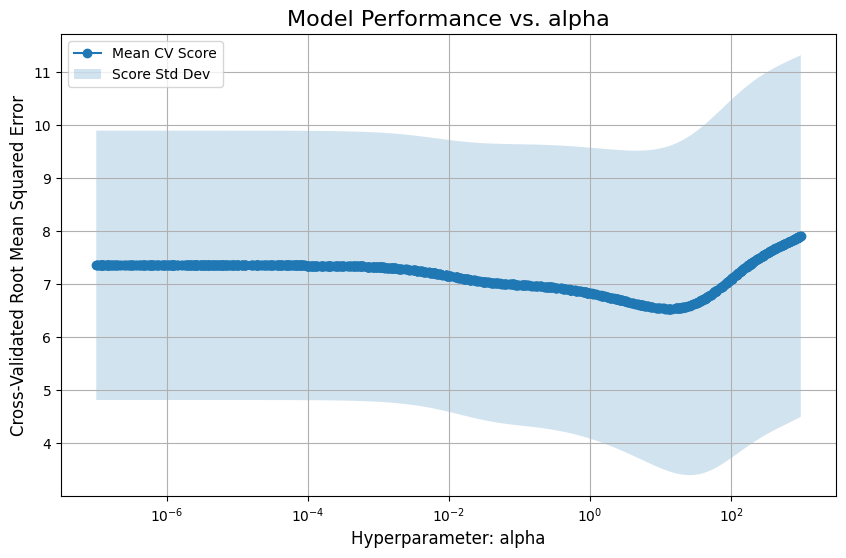

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def plot_random_search_results_1d(random_search, param_name, log_scale=True):
    """
    Plots the results of a 1D RandomizedSearchCV, sorting the values
    to create a clean line plot.

    Args:
        random_search: The fitted RandomizedSearchCV object.
        param_name (str): The name of the hyperparameter that was tuned.
        log_scale (bool): Whether to plot the hyperparameter on a log scale.
    """
    # Extract results into a DataFrame
    cv_results = pd.DataFrame(random_search.cv_results_)

    # --- THE KEY FIX: Sort the DataFrame by the hyperparameter value ---
    param_col_name = f'param_{param_name}'
    cv_results = cv_results.sort_values(by=param_col_name)
    # --------------------------------------------------------------------

    # Get the mean and standard deviation of the validation scores
    mean_scores = cv_results['mean_test_score']
    std_scores = cv_results['std_test_score']
    
    # Get the sorted hyperparameter values
    params = cv_results[param_col_name]

    # Flip the sign of the scores if they are negative
    if random_search.scoring.startswith('neg_'):
        mean_scores = -mean_scores
        score_label = random_search.scoring[4:].replace('_', ' ').title()
    else:
        score_label = random_search.scoring.replace('_', ' ').title()

    plt.figure(figsize=(10, 6))
    
    # Now that 'params' and 'mean_scores' are sorted, the plot will be a clean line
    plt.plot(params, mean_scores, 'o-', label='Mean CV Score')
    
    # Plot the uncertainty band
    plt.fill_between(params, mean_scores - std_scores, mean_scores + std_scores, 
                     alpha=0.2, label='Score Std Dev')

    plt.title(f"Model Performance vs. {param_name.split('__')[-1]}", fontsize=16)
    plt.xlabel(f"Hyperparameter: {param_name.split('__')[-1]}", fontsize=12)
    plt.ylabel(f"Cross-Validated {score_label}", fontsize=12)
    
    if log_scale:
        plt.xscale('log')
        
    plt.legend()
    plt.grid(True)
    plt.show()

# --- Example Usage ---
# Assuming 'grid_search' is your fitted RandomizedSearchCV object from the Ridge model
# and you tuned 'regressor__alpha'
if 'grid_search' in locals():
    plot_random_search_results_1d(grid_search, 'regressor__alpha', log_scale=True)

In [ ]:
# interesting the optimal looks around 0.01 to 100, probably a good place to check. in full run
df_sample_test = raw_data_to_features_pipeline.transform(df_sample_test)

/usr/local/lib/python3.10/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [ ]:
from sklearn.metrics import root_mean_squared_error
y_test_predicted = grid_search.best_estimator_.predict(df_sample_test[[col for col in df_sample_test.columns if col != "fare_amount"]])
-1 * root_mean_squared_error(df_sample_test["fare_amount"], y_test_predicted)

-5.369997830982376

In [ ]:
# since I tested the sample it can be the seed starting point for the pipeline to scale up, then I can explore different things (like what if I drop, what if I change imputation strategy)
# if i run into an error or something else I can debug and decide it then, sample should have taken care of most of snags though
# we should build seperate pipelines for data splitter (test set vs training),  feature engineering (produce features, and statistics for inference/training pipeline) , then model training, then a pipeline for inference.

In [ ]:
spark.stop()

In [ ]:
from pyspark.sql import SparkSession
import os

spark = SparkSession.builder.appName("DatasetSplitter") \
    .master(f"spark://spark-master:7077") \
    .config("spark.executor.memory", "2g") \
    .getOrCreate()

In [ ]:
def create_train_test_split(spark, config):
    """
    Reads the full raw dataset, performs a train/test split,
    and writes the splits back to a persistent location.

    Args:
        spark (SparkSession): The active SparkSession.
        config (dict): A dictionary containing configuration parameters like
                       input_path, train_output_path, test_output_path, etc.
    """
    print("--- Starting Data Splitting Job ---")

    # --- 1. Load the Full Raw Dataset ---
    print(f"Reading full dataset from: {config['input_path']}")
    full_df = spark.read.parquet(config['input_path']).repartition(500)
    
    total_count = full_df.count()
    print(f"Successfully loaded full dataset with {total_count:,} rows.")

    # --- 3. Perform the Train/Test Split ---
    train_fraction = config.get('train_fraction', 0.8)
    test_fraction = 1.0 - train_fraction
    seed = config.get('seed', 42)
    
    print(f"Splitting data into {train_fraction*100}% train and {test_fraction*100}% test sets...")
    
    train_df, test_df = full_df.randomSplit([train_fraction, test_fraction], seed=seed)
    

    full_df.unpersist()
    

    print(f"\nWriting training data to: {config['train_output_path']}")
    train_df.write.mode("overwrite").parquet(config['train_output_path'])
    
    print(f"Writing test data to: {config['test_output_path']}")
    test_df.write.mode("overwrite").parquet(config['test_output_path'])

    print("\n--- Data Splitting Job Finished Successfully! ---")

create_train_test_split(spark, {
    "input_path": "/home/jovyan/workspace/.data/*parquet",
    "train_output_path": "/home/jovyan/workspace/.data/out_train_raw/",
    "test_output_path": "/home/jovyan/workspace/.data/out_test_raw/"
})

--- Starting Data Splitting Job ---
Reading full dataset from: /home/jovyan/workspace/.data/*parquet


Successfully loaded full dataset with 39,656,098 rows.
Splitting data into 80.0% train and 19.999999999999996% test sets...

Writing training data to: /home/jovyan/workspace/.data/out_train_raw/


Writing test data to: /home/jovyan/workspace/.data/out_test_raw/



--- Data Splitting Job Finished Successfully! ---


In [188]:
spark.stop()

In [189]:
!mkdir -p .data/inference

In [190]:
%%writefile .data/inference/custom_transformers.py
import pandas as pd
import json
import os

from pyspark.ml import Estimator, Model, Transformer, Pipeline
from pyspark.ml.param.shared import *
from pyspark.ml.util import DefaultParamsReadable, DefaultParamsWritable, MLReadable, MLReader, MLWritable, DefaultParamsWriter, MLWriter, DefaultParamsReader
from pyspark.sql import functions as F
from pyspark.sql.types import StructType
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.sql import SparkSession

class RawFeatureCalculator(Transformer,  DefaultParamsReadable, DefaultParamsWritable):
    """
    A stateless Transformer that performs initial calculations and creates a
    raw data quality report as a side effect.
    """

    def __init__(self):
        super(RawFeatureCalculator, self).__init__()

    def _transform(self, dataset):
        print("--- Stage 1: Calculating Raw Features ---")
        
        # --- A. Perform stateless calculations ---
        df_out = dataset.withColumn("trip_minutes",
            (F.unix_timestamp(F.col("tpep_dropoff_datetime")) - F.unix_timestamp(F.col("tpep_pickup_datetime"))) / 60.0
        )
        
        return df_out

# ==============================================================================
# STAGE 2: Stateful Data Cleaner and Imputer (Estimator + Model)
# ==============================================================================

# Helper class for writing JSON with NumPy types if Spark returns them
class NpEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.integer): return int(obj)
        if isinstance(obj, np.floating): return float(obj)
        if isinstance(obj, np.ndarray): return obj.tolist()
        return super(NpEncoder, self).default(obj)

class DataCleanerAndImputerModelWriter(MLWriter):
    def __init__(self, instance):
        super(DataCleanerAndImputerModelWriter, self).__init__()
        self.instance = instance

    def saveImpl(self, path):
        # 1. Use the default writer to save standard metadata and ANY PARAMS.
        DefaultParamsWriter(self.instance).save(path)
        
        # 2. Define a path for our custom, learned attributes (the state).
        custom_data_path = os.path.join(path, "custom_model_data")
        os.makedirs(custom_data_path, exist_ok=True)
        
        # 3. Create a dictionary of all the state we need to save.
        state_to_save = {
            "imputation_values": self.instance.imputation_values,
            "clipping_bounds": self.instance.clipping_bounds
            # NOTE: We don't save the config params here, the default writer handles them.
        }
        
        # 4. Save the state as a JSON file.
        with open(os.path.join(custom_data_path, "learned_state.json"), "w") as f:
            json.dump(state_to_save, f, indent=4, cls=NpEncoder)

# ==============================================================================
# The Custom Reader for our Model
# ==============================================================================
class DataCleanerAndImputerModelReader(MLReader):
    def __init__(self, cls):
        super(DataCleanerAndImputerModelReader, self).__init__()
        self.cls = cls

    def load(self, path):
        # 1. Use the default reader to load metadata and instantiate the class with its saved PARAMS.
        instance = DefaultParamsReader(self.cls).load(path)
        
        # 2. Define the path to our custom data.
        custom_data_path = os.path.join(path, "custom_model_data", "learned_state.json")
        
        # 3. Load our custom state from the JSON file.
        with open(custom_data_path, "r") as f:
            loaded_state = json.load(f)
            
        # 4. Populate the instance with the loaded state.
        instance.imputation_values = loaded_state["imputation_values"]
        instance.clipping_bounds = loaded_state["clipping_bounds"]

        return instance
# --- The "Model" part (the Transformer that gets produced by .fit()) ---
class DataCleanerAndImputerModel(Model, MLWritable, MLReadable, HasOutputCol):
    """
    The fitted Transformer. This version is fully serializable AND correctly
    handles both learned attributes and configuration parameters.
    """
    # --- STEP 1: DEFINE THE PARAMS ---
    # All configuration passed from the Estimator must be defined here as a Param.
    filterCondition = Param(Params._dummy(), "filterCondition", "SQL string for filtering")
    labelCol = Param(Params._dummy(), "labelCol", "Name of the target/label column")
    labelFilterCondition = Param(Params._dummy(), "labelFilterCondition", "Filter for the label")
    invalidRecordsPath = Param(Params._dummy(), "invalidRecordsPath", "Path for invalid records")
    transformReportPath = Param(Params._dummy(), "transformReportPath", "Path for transform report")


    def __init__(self, imputation_values=None, clipping_bounds=None, **kwargs):
        super(DataCleanerAndImputerModel, self).__init__()
        
        # --- STEP 2: HANDLE LEARNED ATTRIBUTES ---
        # These are regular Python attributes, not Params.
        self.imputation_values = imputation_values or {}
        self.clipping_bounds = clipping_bounds or {}
        
        # --- STEP 3: SET THE PARAMS ---
        # Initialize the Params with default values
        self._setDefault(filterCondition=None, labelCol=None, labelFilterCondition=None,
                         invalidRecordsPath=None, transformReportPath=None)
        # Use the _set method to populate the Params from the kwargs
        self._set(**kwargs)

    def setParams(self, **kwargs):
        return self._set(**kwargs)
    def write(self):
        """Returns our custom writer instance."""
        return DataCleanerAndImputerModelWriter(self)

    @classmethod
    def read(cls):
        """Returns our custom reader instance."""
        return DataCleanerAndImputerModelReader(cls)
    def _transform(self, dataset):
        print("--- [Transform] Applying Cleaning, Imputation, Clipping, and Filtering ---")
        
        input_count = dataset.count()
        if input_count == 0:
            print("Warning: Input dataset for transform is empty. Returning empty DataFrame.")
            dataset.unpersist()
            return dataset # Return the empty df with original schema


        df_out = dataset
        
        # Initialize a dictionary to hold our audit report for this transformation
        transform_report = {
            "timestamp": pd.Timestamp.now().isoformat(),
            "input_rows": input_count,
            "imputation_counts": {},
            "clipping_stats": {},
            "filtered_out_counts": {}
        }

        # --- 1. Apply learned imputation ---
        if self.imputation_values:
            print(f"Applying learned imputation for: {list(self.imputation_values.keys())}")
            for col_name in self.imputation_values.keys():
                if col_name in df_out.columns:
                    null_count = df_out.filter(F.col(col_name).isNull()).count()
                    transform_report["imputation_counts"][col_name] = {
                        "count": null_count,
                        "fraction": null_count / input_count if input_count > 0 else 0
                    }
            # Apply imputation in one go
            df_out = df_out.fillna(self.imputation_values)

        # --- 2. Apply learned clipping bounds (Winsorizing) ---
        if self.clipping_bounds:
            print(f"Applying clipping to columns: {list(self.clipping_bounds.keys())}")
            for col_name, bounds in self.clipping_bounds.items():
                if col_name in df_out.columns:
                    lower_b = bounds['lower']
                    upper_b = bounds['upper']
                    
                    # Count how many rows will be clipped
                    clipped_lower_count = df_out.filter(F.col(col_name) < lower_b).count()
                    clipped_upper_count = df_out.filter(F.col(col_name) > upper_b).count()
                    total_clipped = clipped_lower_count + clipped_upper_count
                    
                    # Add stats to the report
                    transform_report["clipping_stats"][col_name] = {
                        "clipped_lower_count": clipped_lower_count,
                        "clipped_upper_count": clipped_upper_count,
                        "total_clipped_count": total_clipped,
                        "total_clipped_fraction": total_clipped / input_count
                    }
                    
                    # Apply the clipping
                    df_out = df_out.withColumn(col_name,
                        F.when(F.col(col_name) < lower_b, lower_b)
                         .when(F.col(col_name) > upper_b, upper_b)
                         .otherwise(F.col(col_name))
                    )

        # --- 3. Filter data based on FEATURES and save invalid records ---
        if self.getOrDefault(self.filterCondition):
            print(f"Filtering features with condition: {self.filterCondition}")
            df_after_feature_filter = df_out.filter(self.getOrDefault(self.filterCondition))
            df_invalid_features = df_out.filter(f"NOT ({self.getOrDefault(self.filterCondition)})")
            
            invalid_feature_count = df_invalid_features.count()
            transform_report["filtered_out_counts"]["by_feature_rules"] = {
                "count": invalid_feature_count,
                "fraction": invalid_feature_count/ input_count
            }
            
            
            if self.getOrDefault(self.invalidRecordsPath) and invalid_feature_count > 0:
                print(f"Saving {invalid_feature_count:,} records failing feature rules")
                # Append a timestamp to the path to avoid overwriting between train/test runs
                path = self.invalidRecordsPath.replace(".parquet", f"_features_{pd.Timestamp.now().strftime('%Y%m%d_%H%M%S')}.parquet")
                df_invalid_features.write.mode("overwrite").parquet(path)
        else:
            df_after_feature_filter = df_out
        
        # --- 4. Handle the label column on the feature-clean data ---
        df_final_clean = df_after_feature_filter
        if self.getOrDefault(self.labelCol) and self.getOrDefault(self.labelCol) in df_after_feature_filter.columns:
            print(f"Processing label column: '{self.labelCol}'")
            
            # 4a. Apply label-specific filtering
            if self.getOrDefault(self.labelFilterCondition):
                print(f"Filtering label with condition: {self.getOrDefault(self.labelFilterCondition)}")
                df_final_clean = df_after_feature_filter.filter(self.getOrDefault(self.labelFilterCondition))
                df_invalid_label = df_after_feature_filter.filter(f"NOT ({self.getOrDefault(self.labelFilterCondition)})")
                
                invalid_label_count = df_invalid_label.count()
                transform_report["filtered_out_counts"]["by_label_rules"] = {
                    "count": invalid_label_count,
                    "fraction": invalid_label_count / input_count
                }

                if self.getOrDefault(self.invalidRecordsPath) and invalid_label_count > 0:
                    path = self.getOrDefault(self.invalidRecordsPath).replace(".parquet", f"_label_{pd.Timestamp.now().strftime('%Y%m%d_%H%M%S')}.parquet")
                    print(f"Saving {invalid_label_count:,} records failing label rules")
                    df_invalid_label.write.mode("overwrite").parquet(path)

        # --- 5. Finalize and save the transform-time report (side effect) ---
        transform_report["output_rows"] = df_final_clean.count()

        if self.getOrDefault(self.transformReportPath):
            path = self.getOrDefault(self.transformReportPath).replace(".json", f"_{pd.Timestamp.now().strftime('%Y%m%d_%H%M%S')}.json")
            print(f"Saving transform-time audit report to: {path}")
            os.makedirs(os.path.dirname(path), exist_ok=True)
            with open(path, 'w') as f:
                json.dump(transform_report, f, indent=4)
        
        return df_final_clean

# --- The "Estimator" part (the learning object) ---
class DataStats(Estimator, DefaultParamsReadable, DefaultParamsWritable):
    """
    The Estimator. Learns imputation statistics from the clean portion
    of the training data.
    """
    filterCondition = Param(Params._dummy(), "filterCondition", "record filtering condition")
    invalidRecordsPath = Param(Params._dummy(), "invalidRecordsPath", "where to put the bad records")
    numericalImputeCols = Param(Params._dummy(), "numericalImputeCols", "numerical columns to impute")
    categoricalImputeCols = Param(Params._dummy(), "categoricalImputeCols", "categorical columns to impute")
    numericalClipCols = Param(Params._dummy(), "numericalClipCols", "List of numerical columns to calculate clipping bounds for")
    labelCol = Param(Params._dummy(), "labelCol", "label column name")
    statsOutputPath = Param(Params._dummy(), "statsOutputPath", "Path to save the learned statistics JSON report")
    labelFilterCondition = Param(Params._dummy(), "labelFilterCondition", "label filtering condition")
    transformReportPath = Param(Params._dummy(), "transformReportPath", "path for transformation report")

    def __init__(self, **kwargs):
        super(DataStats, self).__init__()
        self._setDefault(filterCondition=None, invalidRecordsPath=None, numericalImputeCols=[],
                         categoricalImputeCols=[], labelCol=None, numericalClipCols=[], statsOutputPath=None, labelFilterCondition=None, transformReportPath=None)
        self.setParams(**kwargs)

    def setParams(self, **kwargs):
        return self._set(**kwargs)

    def _fit(self, dataset):
        print("--- [Fit] Learning Imputation Stats and clipping stats ---")
        
        filter_cond = self.getOrDefault(self.filterCondition)
        num_impute_cols = self.getOrDefault(self.numericalImputeCols)
        cat_impute_cols = self.getOrDefault(self.categoricalImputeCols)
        num_clip_cols = self.getOrDefault(self.numericalClipCols) 
        stats_path = self.getOrDefault(self.statsOutputPath)
        
        # Filter to get the clean data for learning
        df_clean = dataset.filter(filter_cond)
        
        learned_stats = {
            "imputation_values": {},
            "clipping_bounds": {}
        }
        
        # Learn imputation values
        imputation_values = {}
        if num_impute_cols:
            median_exprs = [F.expr(f"percentile_approx({c}, 0.5)").alias(c) for c in num_impute_cols]
            medians = df_clean.agg(*median_exprs).first().asDict()
            imputation_values.update(medians)
        clipping_bounds = {}
        if num_clip_cols:
            # Create aggregation expressions for the 0.5th and 99.5th percentiles
            quantile_exprs = []
            for c in num_clip_cols:
                quantile_exprs.append(F.expr(f"percentile_approx({c}, 0.005)").alias(f"{c}_lower_bound"))
                quantile_exprs.append(F.expr(f"percentile_approx({c}, 0.995)").alias(f"{c}_upper_bound"))

            # Execute the aggregation
            bounds_row = df_clean.agg(*quantile_exprs).first()
            for c in num_clip_cols:
                clipping_bounds[c] = {
                    "lower": bounds_row[f"{c}_lower_bound"],
                    "upper": bounds_row[f"{c}_upper_bound"]
                }
        if cat_impute_cols:
            for c in cat_impute_cols:
                mode_val = df_clean.groupBy(c).count().orderBy(F.desc("count")).first()[0]
                imputation_values[c] = mode_val
        learned_stats["imputation_values"] = imputation_values
        print(f"Learned imputation values: {imputation_values}")
        learned_stats["clipping_bounds"] = clipping_bounds
        print(f"Learned clipping bounds: {clipping_bounds}")


        if stats_path:
            print(f"Saving learned statistics to: {stats_path}")
            os.makedirs(os.path.dirname(stats_path), exist_ok=True)
            with open(stats_path, 'w') as f:
                # Use a custom JSON encoder for NumPy types if necessary
                class NpEncoder(json.JSONEncoder):
                    def default(self, obj):
                        if isinstance(obj, np.integer):
                            return int(obj)
                        if isinstance(obj, np.floating):
                            return float(obj)
                        if isinstance(obj, np.ndarray):
                            return obj.tolist()
                        return super(NpEncoder, self).default(obj)
                json.dump(learned_stats, f, indent=4, cls=NpEncoder)
        
        config_params = {
            self.filterCondition.name: self.getOrDefault(self.filterCondition),
            self.labelCol.name: self.getOrDefault(self.labelCol),
            self.labelFilterCondition.name: self.getOrDefault(self.labelFilterCondition),
            self.invalidRecordsPath.name: self.getOrDefault(self.invalidRecordsPath),
            self.transformReportPath.name: self.getOrDefault(self.transformReportPath)
        }
        
        # Return the fitted Model, passing the learned state as keyword arguments
        # and the configuration state as a dictionary to the kwargs of the constructor.
        return DataCleanerAndImputerModel(
            imputation_values=imputation_values,
            clipping_bounds=clipping_bounds,
            **config_params
        )

from pyspark.ml import Transformer
from pyspark.ml.param.shared import HasInputCols, Param, Params, TypeConverters
from pyspark.sql.types import StructType


class ColumnDropper(Transformer, HasInputCols, DefaultParamsReadable, DefaultParamsWritable):
    """
    A custom Spark ML Transformer that drops one or more specified columns
    from a DataFrame.
    """

    def __init__(self, inputCols=None):
        """
        Initializes the ColumnDropper transformer.

        Args:
            inputCols (list of str, optional): A list of column names to drop. 
                                              Defaults to None.
        """
        super(ColumnDropper, self).__init__()
        # We use 'inputCols' as the parameter name to be consistent with other Spark transformers.
        self._setDefault(inputCols=[])
        if inputCols is not None:
            self.set(self.inputCols, inputCols)

    def setInputCols(self, value):
        """Sets the value of inputCols."""
        return self._set(inputCols=value)
    
    # The _transform method is the core of any Transformer.
    def _transform(self, dataset):
        """
        Transforms the input dataset by dropping the specified columns.

        Args:
            dataset (DataFrame): The input Spark DataFrame.

        Returns:
            DataFrame: The transformed DataFrame with columns dropped.
        """
        cols_to_drop = self.getInputCols()
        
        if not cols_to_drop:
            print("ColumnDropper: No columns specified to drop. Returning original DataFrame.")
            return dataset
            
        print(f"ColumnDropper: Dropping columns: {cols_to_drop}")
        
        # The '*' unpacks the list into individual arguments for the .drop() method
        return dataset.drop(*cols_to_drop)

    # The following methods are required for ML Pipeline persistence and schema validation.

    def copy(self, extra=None):
        """
        Creates a copy of this instance with the same UID and params.
        This is required for Spark pipelines.
        """
        if extra is None:
            extra = dict()
        return self.__class__(inputCols=self.getInputCols())

    def transformSchema(self, schema):
        """
        Transforms the input schema to the output schema by removing the specified columns.
        Spark uses this to validate the pipeline before running data through it.
        
        Args:
            schema (StructType): The input schema.

        Returns:
            StructType: The output schema.
        """
        cols_to_drop = self.getInputCols()
        
        # Create a new list of schema fields, excluding the ones to be dropped
        new_columns = [field for field in schema.fields if field.name not in cols_to_drop]
        
        # Return a new StructType with the updated fields
        return StructType(new_columns)

Writing .data/inference/custom_transformers.py


In [3]:
import sys
sys.path.append("./.data/inference") # so we can pull it
from custom_transformers import RawFeatureCalculator, DataStats, ColumnDropper

from pyspark.ml import Estimator, Model, Transformer, Pipeline
from pyspark.ml.param.shared import *
from pyspark.ml.util import DefaultParamsReadable, DefaultParamsWritable, MLReadable, MLReader, MLWritable, DefaultParamsWriter, MLWriter, DefaultParamsReader
from pyspark.sql import functions as F
from pyspark.sql.types import StructType
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.sql import SparkSession

In [198]:
if __name__ == "__main__":
    
    spark = SparkSession.builder.appName("FeaturePipeline").master(f"spark://spark-master:7077").config("spark.executor.memory", "6g").getOrCreate()
    
    raw_train_df = spark.read.parquet("/home/jovyan/workspace/.data/out_train_raw")
    
    print("--- Original Raw Training Data ---")
    raw_train_df.show()
    
    # --- 2. Define the stages of your FeaturePipeline ---
    
    # Stage 1: Raw Feature Calculator
    raw_feature_calculator = RawFeatureCalculator()

    # Stage 2: Data Cleaner and Imputer
    cleaner_and_imputer = DataStats(
        filterCondition="trip_distance > 0 AND trip_minutes > 0",
        invalidRecordsPath="/tmp/spark_artifacts/invalid_records.parquet",
        numericalImputeCols=["passenger_count"],
        categoricalImputeCols=["RatecodeID", "store_and_fwd_flag"],
        numericalClipCols=["trip_minutes", "trip_distance"],
        labelCol="fare_amount",
        statsOutputPath="/tmp/spark_artifacts/training_stats.json",
        transformReportPath="/tmp/spark_artifacts/transformation_report.json",
        labelFilterCondition= "fare_amount > 0 AND fare_amount < 100"
    )
    

    dropper = ColumnDropper(inputCols=[
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "total_amount",
        "VendorID",
        "tip_amount",
        "tolls_amount",
        "payment_type",
        "extra",
        "mta_tax",
        "improvement_surcharge",
        "congestion_surcharge",
        "airport_fee"
    ])
    categorical_cols_to_encode = ["RatecodeID", "store_and_fwd_flag", "PULocationID", "DOLocationID"]
    
    # Create the lists of StringIndexer and OneHotEncoder stages
    indexers = [
        StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid='keep')
        for c in categorical_cols_to_encode
    ]
    
    encoders = [
        OneHotEncoder(inputCol=f"{c}_idx", outputCol=f"{c}_ohe")
        for c in categorical_cols_to_encode
    ]

    # --- Stage 5: Vector Assembler and Scaler for Final Features ---
    
    # Define your final numerical features (after imputation/clipping)
    final_numerical_cols = ["passenger_count", "trip_minutes", "trip_distance"]
    
    # Define the inputs for the assembler: all OHE columns + all numerical columns
    assembler_input_cols = [f"{c}_ohe" for c in categorical_cols_to_encode] + final_numerical_cols
    
    # Create the VectorAssembler
    assembler = VectorAssembler(
        inputCols=assembler_input_cols,
        outputCol="unscaled_features"
    )
    
    # Create the StandardScaler to scale the final vector
    scaler = StandardScaler(
        inputCol="unscaled_features",
        outputCol="features" # This is the conventional final feature column name
    )

    cols_to_clean_up = ["unscaled_features"] + final_numerical_cols + categorical_cols_to_encode
    for c in categorical_cols_to_encode:
        cols_to_clean_up.append(f"{c}_idx")
        cols_to_clean_up.append(f"{c}_ohe")
        
    final_dropper = ColumnDropper(inputCols=cols_to_clean_up)
    # --- 3. Assemble the FeaturePipeline Estimator ---
    FeaturePipeline = Pipeline(stages=[
        raw_feature_calculator,
        cleaner_and_imputer,
        dropper,
        *indexers,  # Unpack the lists of stages
        *encoders,
        assembler,
        scaler,
        final_dropper
    ])

    # --- 4. Fit the pipeline on the raw training data ---
    print("\n\n FITTING THE FEATURE PIPELINE ".center(80, "="))
    fitted_feature_pipeline = FeaturePipeline.fit(raw_train_df)
    print("\n\n TRANSFORMING THE TRAINING DATA ".center(80, "="))
    transformed_train_df = fitted_feature_pipeline.transform(raw_train_df)
    print("--- Training Features ---")
    transformed_train_df.show()
    features_output_path = "/home/jovyan/workspace/.data/processed/train_features.parquet"

    print(f"\n--- Saving final features to: {features_output_path} ---")
    feature_pipeline_path = "/home/jovyan/workspace/.data/artifacts/fitted_feature_pipeline.spark"
    print(f"Saving the fitted feature pipeline to: {feature_pipeline_path}")
    fitted_feature_pipeline.write().overwrite().save(feature_pipeline_path)

    # Use the .write API.
    # 'overwrite' mode will delete the directory if it already exists, which is
    # useful for re-running your pipeline.
    transformed_train_df.write.mode("overwrite").parquet(features_output_path)

    print("done.")

--- Original Raw Training Data ---
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|airport_fee|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+
|       1| 2022-01-01 00:54:01|  2022-01-01 01:04:21|            2.0|          2.0|       1.0|                 N|         162|          79|           1|

Learned imputation values: {'passenger_count': 1.0, 'RatecodeID': 1.0, 'store_and_fwd_flag': 'N'}
Learned clipping bounds: {'trip_minutes': {'lower': 1.0333333333333334, 'upper': 77.51666666666667}, 'trip_distance': {'lower': 0.17, 'upper': 21.71}}
Saving learned statistics to: /tmp/spark_artifacts/training_stats.json
--- [Transform] Applying Cleaning, Imputation, Clipping, and Filtering ---
Applying learned imputation for: ['passenger_count', 'RatecodeID', 'store_and_fwd_flag']
Applying clipping to columns: ['trip_minutes', 'trip_distance']
Filtering features with condition: DataCleanerAndImputerModel_b921bd37e85e__filterCondition
Processing label column: 'DataCleanerAndImputerModel_b921bd37e85e__labelCol'
Filtering label with condition: fare_amount > 0 AND fare_amount < 100


Saving 266,416 records failing label rules


Saving transform-time audit report to: /tmp/spark_artifacts/transformation_report_20251009_162725.json
ColumnDropper: Dropping columns: ['tpep_pickup_datetime', 'tpep_dropoff_datetime', 'total_amount', 'VendorID', 'tip_amount', 'tolls_amount', 'payment_type', 'extra', 'mta_tax', 'improvement_surcharge', 'congestion_surcharge', 'airport_fee']



 TRANSFORMING THE TRAINING DATA =======================
--- Stage 1: Calculating Raw Features ---
--- [Transform] Applying Cleaning, Imputation, Clipping, and Filtering ---
Applying learned imputation for: ['passenger_count', 'RatecodeID', 'store_and_fwd_flag']
Applying clipping to columns: ['trip_minutes', 'trip_distance']
Filtering features with condition: DataCleanerAndImputerModel_b921bd37e85e__filterCondition
Processing label column: 'DataCleanerAndImputerModel_b921bd37e85e__labelCol'
Filtering label with condition: fare_amount > 0 AND fare_amount < 100
Saving 266,416 records failing label rules


Saving transform-time audit report to: /tmp/spark_artifacts/transformation_report_20251009_162742.json
ColumnDropper: Dropping columns: ['tpep_pickup_datetime', 'tpep_dropoff_datetime', 'total_amount', 'VendorID', 'tip_amount', 'tolls_amount', 'payment_type', 'extra', 'mta_tax', 'improvement_surcharge', 'congestion_surcharge', 'airport_fee']
ColumnDropper: Dropping columns: ['unscaled_features', 'passenger_count', 'trip_minutes', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'RatecodeID_idx', 'RatecodeID_ohe', 'store_and_fwd_flag_idx', 'store_and_fwd_flag_ohe', 'PULocationID_idx', 'PULocationID_ohe', 'DOLocationID_idx', 'DOLocationID_ohe']
--- Training Features ---
+-----------+--------------------+
|fare_amount|            features|
+-----------+--------------------+
|        9.5|(536,[0,7,15,288,...|
|        6.0|(536,[0,7,29,274,...|
|       10.0|(536,[0,7,14,288,...|
|       17.5|(536,[0,7,20,323,...|
|        7.0|(536,[0,7,25,305,...|
|      

done.


In [199]:
print("\n\n TRANSFORMING THE TEST DATA ".center(20, "="))
raw_test_df = spark.read.parquet("/home/jovyan/workspace/.data/out_test_raw/*parquet")
transformed_test_df = fitted_feature_pipeline.transform(raw_test_df)
print("--- Training Features ---")
transformed_test_df.show()
features_output_path = "/home/jovyan/workspace/.data/processed/test_features.parquet"



 TRANSFORMING THE TEST DATA 
--- Stage 1: Calculating Raw Features ---
--- [Transform] Applying Cleaning, Imputation, Clipping, and Filtering ---
Applying learned imputation for: ['passenger_count', 'RatecodeID', 'store_and_fwd_flag']
Applying clipping to columns: ['trip_minutes', 'trip_distance']
Filtering features with condition: DataCleanerAndImputerModel_b921bd37e85e__filterCondition
Processing label column: 'DataCleanerAndImputerModel_b921bd37e85e__labelCol'
Filtering label with condition: fare_amount > 0 AND fare_amount < 100
Saving 66,135 records failing label rules
Saving transform-time audit report to: /tmp/spark_artifacts/transformation_report_20251009_162830.json
ColumnDropper: Dropping columns: ['tpep_pickup_datetime', 'tpep_dropoff_datetime', 'total_amount', 'VendorID', 'tip_amount', 'tolls_amount', 'payment_type', 'extra', 'mta_tax', 'improvement_surcharge', 'congestion_surcharge', 'airport_fee']
ColumnDropper: Dropping columns: ['unscaled_features', 'passenger_count', 

In [200]:
spark.stop()

In [201]:
import os
import json
import pandas as pd # For timestamp in report name
from pyspark.sql import SparkSession
from pyspark.ml.regression import LinearRegression
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.ml.evaluation import RegressionEvaluator
import numpy as np # For defining the hyperparameter search space

def train_and_tune_model(spark, config):
    """
    Loads pre-processed features, tunes a Ridge regression model using
    CrossValidator, and saves the best model found.
    """
    print("--- Starting Model Training and Tuning Job ---")

    # --- 1. Load the Pre-processed Training Features ---
    print(f"Loading training features from: {config['train_features_path']}")
    train_df = spark.read.parquet(config['train_features_path']).repartition(1000) 
    train_df.cache()

    print(f"Loaded {train_df.count():,} rows for training.")
    
    # --- 2. Define the Estimator (the Model to be Tuned) ---
    # Ridge Regression in Spark is implemented as LinearRegression with l1_ratio (elasticNetParam) = 0.
    lr = LinearRegression(
        featuresCol="features",
        labelCol=config['label_col'],
        elasticNetParam=0.0  # This makes it a Ridge (L2) regression
    )
    
    # --- 3. Define the Hyperparameter Grid ---
    # You identified a good range from your earlier analysis.
    # We will use ParamGridBuilder to create a grid of values to test.
    # np.logspace is great for searching over a wide range of values.
    # This will create values like [0.01, 0.012, 0.015, ..., 80, 100]
    alpha_values = np.logspace(-3, 2, 20).tolist() # 20 values from 0.01 to 100

    paramGrid = ParamGridBuilder() \
        .addGrid(lr.regParam, alpha_values) \
        .build()
        
    print(f"\nCreated hyperparameter grid with {len(paramGrid)} combinations for 'alpha' (regParam).")

    # --- 4. Define the Evaluator ---
    # This is what CrossValidator will use to judge which model is best.
    # The metric should be calculated on the log scale, as that's what the model predicts.
    evaluator = RegressionEvaluator(
        labelCol=config['label_col'],
        predictionCol="prediction",
        metricName="rmse" # Root Mean Squared Error
    )
    
    # --- 5. Set up the CrossValidator ---
    # CrossValidator is Spark's equivalent of GridSearchCV/RandomizedSearchCV
    crossval = CrossValidator(
        estimator=lr,
        estimatorParamMaps=paramGrid,
        evaluator=evaluator,
        numFolds=config.get('cv_folds', 5), # Use 3 folds for speed, 5 is also common
        parallelism=1, # Number of models to train in parallel
        seed=config.get('seed', 42)
    )

    # --- 6. Run the Tuning and Training Process (The .fit() call) ---
    print("\nStarting Cross-Validation to find the best model...")
    # This is the most computationally intensive step.
    # Spark will train (number of alphas * numFolds) models.
    cv_model = crossval.fit(train_df)
    print("--- Cross-Validation complete! ---")

    # The cv_model object now holds the BEST model found during the search,
    # automatically re-trained on the entire training dataset.
    
    # --- 7. Save the Final Model Artifact ---
    print(f"\nSaving the best model to: {config['model_output_path']}")
    cv_model.bestModel.write().overwrite().save(config['model_output_path'])
    train_df.unpersist()
    # --- 8. (Side Effect) Save the CV Metrics ---
    # It's great practice to save the results of your tuning.
    print(f"Saving CV metrics to: {config['metrics_output_path']}")
    
    cv_metrics = {
        "best_alpha": cv_model.bestModel.getRegParam(),
        "avg_rmse_per_fold": cv_model.avgMetrics,
        "params_tested": [p.values() for p in paramGrid]
    }
    
    os.makedirs(os.path.dirname(config['metrics_output_path']), exist_ok=True)
    with open(config['metrics_output_path'], 'w') as f:
        # A simple way to write the metrics out
        f.write(f"Best Alpha (regParam): {cv_metrics['best_alpha']}\n\n")
        f.write("Average RMSE for each parameter combination:\n")
        for params, metric in zip(cv_metrics['params_tested'], cv_metrics['avg_rmse_per_fold']):
            f.write(f"Params: {list(params)} -> Avg RMSE: {metric:.4f}\n")

    print("\n--- Model Training Job Finished Successfully! ---")
    
    return cv_model.bestModel
job_config = {
    "train_features_path": "/home/jovyan/workspace/.data/processed/train_features.parquet",
    "label_col": "fare_amount",
    "model_output_path": "/home/jovyan/workspace/.data/artifacts/ridge_model.spark",
    "metrics_output_path": "/home/jovyan/workspace/.data/artifacts/ridge_cv_metrics.txt",
    "cv_folds": 5,
    "seed": 42
}
from pyspark.sql import SparkSession
spark = SparkSession.builder.appName("Trainer").master(f"spark://spark-master:7077").config("spark.executor.memory", "6g").getOrCreate()
train_and_tune_model(spark, job_config)

--- Starting Model Training and Tuning Job ---
Loading training features from: /home/jovyan/workspace/.data/processed/train_features.parquet


Loaded 31,458,691 rows for training.

Created hyperparameter grid with 20 combinations for 'alpha' (regParam).

Starting Cross-Validation to find the best model...


25/10/09 16:29:45 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
25/10/09 16:29:45 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS
25/10/09 16:29:45 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.lapack.JNILAPACK


--- Cross-Validation complete! ---

Saving the best model to: /home/jovyan/workspace/.data/artifacts/ridge_model.spark
Saving CV metrics to: /home/jovyan/workspace/.data/artifacts/ridge_cv_metrics.txt

--- Model Training Job Finished Successfully! ---


LinearRegressionModel: uid=LinearRegression_ed79dba76bf0, numFeatures=536

In [202]:
spark.stop()

In [1]:
import os
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import ArrayType, DoubleType
from pyspark.ml.linalg import SparseVector, DenseVector

def create_sklearn_sample(spark, config):
    """
    Loads final engineered features from Spark, takes a sample, un-vectorizes
    the 'features' column, and saves the result as a single CSV file for use
    with scikit-learn and pandas.

    Args:
        spark (SparkSession): The active SparkSession.
        config (dict): A dictionary of job parameters.
    """
    print("--- Starting Job to Create Scikit-learn Sample ---")

    # --- 1. Load the Pre-processed Training Features ---
    print(f"Loading features from: {config['features_path']}")
    features_df = spark.read.parquet(config['features_path'])
    features_df.cache()
    total_rows = features_df.count()
    print(f"Loaded {total_rows:,} rows with engineered features.")

    # --- 2. Take a Sample ---
    sample_size = config.get("sample_size", 50000)
    if total_rows > 0:
        fraction = min(sample_size / total_rows, 1.0) # Ensure fraction is not > 1
    else:
        fraction = 0.0
        
    seed = config.get("seed", 42)

    print(f"Sampling {fraction:.4%} of the data to get ~{sample_size:,} rows...")
    df_sample = features_df.sample(fraction=fraction, seed=seed)
    df_sample.cache()
    print(f"Sample contains {df_sample.count():,} rows.")

    # Unpersist the large DataFrame
    features_df.unpersist()

    # --- 3. Un-vectorize the 'features' Column ---
    print("\nUn-vectorizing the 'features' column...")

    # A. Define a UDF to convert Spark's Vector type to a standard Python list
    def to_dense_array(v):
        if isinstance(v, (SparseVector, DenseVector)):
            return v.toArray().tolist()
        return None

    to_dense_array_udf = F.udf(to_dense_array, ArrayType(DoubleType()))

    # B. Apply the UDF
    df_with_array = df_sample.withColumn("features_array", to_dense_array_udf(F.col("features")))

    # C. Get the size of the feature vector to create new column names
    try:
        vector_size = df_sample.select("features").first()[0].size
        print(f"Detected feature vector size of: {vector_size}")
    except Exception as e:
        print(f"Could not determine vector size from metadata, defaulting to 536. Error: {e}")
        vector_size = 536 # Fallback based on your previous output

    # D. "Explode" the array into individual columns
    feature_cols_expr = [F.col("features_array")[i].alias(f"feature_{i}") for i in range(vector_size)]
    
    df_wide = df_with_array.select(
        config['label_col'],
        *feature_cols_expr
    )

    # --- 4. Collect to Pandas and Save as CSV ---
    print("\nCollecting the sampled, wide DataFrame into pandas...")
    # This action brings the data to the driver. It should only be done on a sample.
    pandas_df = df_wide.toPandas()
    print(f"Successfully collected {len(pandas_df)} rows into a pandas DataFrame.")
    
    # Define the output path
    csv_output_path = config['csv_output_path']
    os.makedirs(os.path.dirname(csv_output_path), exist_ok=True)
    
    print(f"Saving the sample as a CSV to: {csv_output_path}")
    pandas_df.to_csv(csv_output_path, index=False)
    print("CSV sample created successfully.")
    
    df_sample.unpersist()

if __name__ == "__main__":
    
    job_config = {
        # Path to your final features created by the feature engineering pipeline
        "features_path": "/home/jovyan/workspace/.data/processed/train_features.parquet",
        
        # The name of your label column in that DataFrame
        "label_col": "fare_amount",
        
        # Path where the final CSV will be saved (inside the container)
        "csv_output_path": "/home/jovyan/workspace/.data/artifacts/sklearn_ready_sample.csv",
        
        # How many rows you want in your final sample
        "sample_size": 30000,
        "seed": 42
    }
    
    # Initialize SparkSession inside the dev-client container
    spark = SparkSession.builder \
        .appName("CreateSklearnSample") \
        .master("spark://spark-master:7077") \
        .config("spark.executor.memory", "6g").getOrCreate()

    # Run the job
    create_sklearn_sample(spark, job_config)
    
    spark.stop()

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/10/09 17:14:36 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


--- Starting Job to Create Scikit-learn Sample ---
Loading features from: /home/jovyan/workspace/.data/processed/train_features.parquet


Loaded 31,458,691 rows with engineered features.
Sampling 0.0954% of the data to get ~30,000 rows...


Sample contains 30,218 rows.

Un-vectorizing the 'features' column...
Detected feature vector size of: 536



25/10/09 17:14:49 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Successfully collected 30218 rows into a pandas DataFrame.
Saving the sample as a CSV to: /home/jovyan/workspace/.data/artifacts/sklearn_ready_sample.csv
CSV sample created successfully.


In [4]:
# load from saved state and run on test data
import os
from pyspark.sql import SparkSession
from pyspark.ml import PipelineModel

# must have all classes defined in pipeline being loaded.
def run_test_feature_generation(spark, config):
    """
    Loads a pre-fitted feature engineering pipeline and applies it to new
    (e.g., test) data to create a consistent set of features.
    """
    print("--- Starting Feature Engineering Job ---")

    # --- 1. Load the Raw Test Data ---
    print(f"Loading raw test data from: {config['raw_test_path']}")
    try:
        raw_test_df = spark.read.parquet(config['raw_test_path'])
        print(f"Loaded {raw_test_df.count():,} raw records for inference.")
    except Exception as e:
        print(f"ERROR: Could not load test data. Path: {config['raw_test_path']}")
        print(e)
        raise

    # --- 2. Load the FITTED Feature Pipeline Model ---
    # This is the primary artifact from your training workflow.
    # It is a Transformer, not an Estimator.
    print(f"Loading fitted feature pipeline from: {config['feature_pipeline_path']}")
    try:
        fitted_feature_pipeline = PipelineModel.load(config['feature_pipeline_path'])
    except Exception as e:
        print(f"ERROR: Could not load the fitted pipeline model.")
        print(e)
        raise
        
    
    print("\nApplying the fitted pipeline to the test data...")
    test_features_df = fitted_feature_pipeline.transform(raw_test_df)
    print(fitted_feature_pipeline)
    print("\n--- Transformation of test data complete. ---")
    print("--- Sample of Final Test Features ---")
    test_features_df.show(5, truncate=False)
    test_features_df.printSchema()

    # --- 4. Save the Final, Model-Ready Test Features ---
    print(f"\nSaving final test features to: {config['features_output_path']}")
    test_features_df.write.mode("overwrite").parquet(config['features_output_path'])
    print("--- Test features saved successfully. ---")
    
    return test_features_df


if __name__ == "__main__":
    
    # Configuration for the inference job
    job_config = {
        # Input: The raw test set from your data splitter job
        "raw_test_path": "/home/jovyan/workspace/.data/out_test_raw",
        
        # Input: The path to the fitted feature pipeline you saved during training
        "feature_pipeline_path": "/home/jovyan/workspace/.data/artifacts/fitted_feature_pipeline.spark",
        
        # Output: The final, clean features for the test set
        "features_output_path": "/home/jovyan/workspace/.data/processed/test_features.parquet"
    }
    
    spark = SparkSession.builder \
        .appName("Feature Engineering") \
        .master("spark://spark-master:7077") \
        .config("spark.executor.memory", "6g").getOrCreate()

    # --- Run the Job ---
    run_test_feature_generation(spark, job_config)
    
    # --- Stop the Spark Session ---
    spark.stop()
    print("\Feature Generation job complete.")

--- Starting Feature Engineering Job ---
Loading raw test data from: /home/jovyan/workspace/.data/out_test_raw
Loaded 7,930,991 raw records for inference.
Loading fitted feature pipeline from: /home/jovyan/workspace/.data/artifacts/fitted_feature_pipeline.spark

Applying the fitted pipeline to the test data...
--- Stage 1: Calculating Raw Features ---
--- [Transform] Applying Cleaning, Imputation, Clipping, and Filtering ---
Applying learned imputation for: ['passenger_count', 'RatecodeID', 'store_and_fwd_flag']
Applying clipping to columns: ['trip_minutes', 'trip_distance']
Filtering features with condition: DataCleanerAndImputerModel_b921bd37e85e__filterCondition
Processing label column: 'DataCleanerAndImputerModel_b921bd37e85e__labelCol'
Filtering label with condition: fare_amount > 0 AND fare_amount < 100
Saving 66,135 records failing label rules


Saving transform-time audit report to: /tmp/spark_artifacts/transformation_report_20251009_171620.json
ColumnDropper: Dropping columns: ['tpep_pickup_datetime', 'tpep_dropoff_datetime', 'total_amount', 'VendorID', 'tip_amount', 'tolls_amount', 'payment_type', 'extra', 'mta_tax', 'improvement_surcharge', 'congestion_surcharge', 'airport_fee']
ColumnDropper: Dropping columns: ['unscaled_features', 'passenger_count', 'trip_minutes', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'RatecodeID_idx', 'RatecodeID_ohe', 'store_and_fwd_flag_idx', 'store_and_fwd_flag_ohe', 'PULocationID_idx', 'PULocationID_ohe', 'DOLocationID_idx', 'DOLocationID_ohe']
PipelineModel_76f39ee828e7

--- Transformation of test data complete. ---
--- Sample of Final Test Features ---
+-----------+------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|fare_amount|features   

--- Test features saved successfully. ---
\Feature Generation job complete.


--- Starting Final Model Evaluation Job ---
Loading test features from: /home/jovyan/workspace/.data/processed/test_features.parquet


Loaded 7,864,856 rows of test data.
Loading final trained model from: /home/jovyan/workspace/.data/artifacts/ridge_model.spark
Making predictions on the test set...


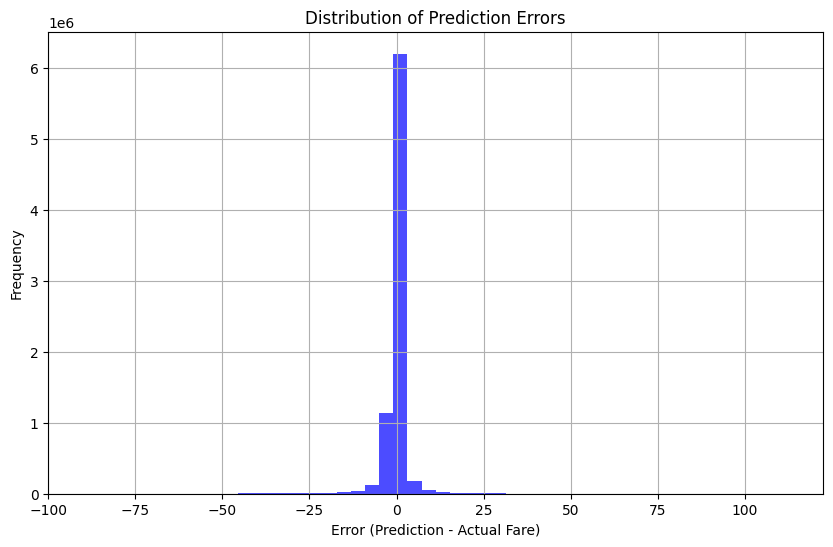

Summary statistics for the prediction error:
+-------+--------------------+
|summary|               error|
+-------+--------------------+
|  count|             7864856|
|   mean|0.001268114461413...|
| stddev|  3.7523710807410913|
|    min|  -89.95266000700732|
|    max|  112.44635436461509|
+-------+--------------------+


--- Performance  ---
RMSE on test set: 3.7524
R-squared on test set: 0.9135

--- Evaluation Job Finished Successfully! ---
+-----------+--------------------+------------------+
|fare_amount|            features|        prediction|
+-----------+--------------------+------------------+
|       16.5|(536,[0,7,31,277,...| 15.93516042907657|
|        5.0|(536,[0,8,49,279,...| 6.093422999888092|
|       24.0|(536,[0,7,18,341,...|22.963881895374442|
|        6.5|(536,[0,7,14,274,...| 7.603309037477905|
|        7.0|(536,[0,7,16,277,...|  7.44877926241297|
|        4.5|(536,[0,7,38,271,...| 5.705470914303338|
|        9.5|(536,[0,7,28,277,...| 9.339956513044537|
|        7.

In [5]:
from pyspark.sql import SparkSession
from pyspark.ml.regression import LinearRegressionModel
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.sql.functions import col
import matplotlib.pyplot as plt


def evaluate_final_model(spark, config):
    """
    Loads a final trained model and pre-processed test features,
    makes predictions, and evaluates the final performance.
    """
    print("--- Starting Final Model Evaluation Job ---")

    # --- 1. Load the Pre-processed TEST Features ---
    # These were created by your Feature Engineering pipeline using the test split.
    print(f"Loading test features from: {config['test_features_path']}")
    try:
        test_features_df = spark.read.parquet(config['test_features_path'])
        test_count = test_features_df.count()
        if test_count == 0:
            print("ERROR: Test features DataFrame is empty. Cannot evaluate.")
            return
        print(f"Loaded {test_count:,} rows of test data.")
    except Exception as e:
        print(f"ERROR: Could not load test features. Path: {config['test_features_path']}")
        print(e)
        raise

    # --- 2. Load the FINAL TRAINED Model ---
    # This is the 'bestModel' that was saved from your CrossValidator run.
    print(f"Loading final trained model from: {config['model_path']}")
    try:
        # For a LinearRegression model, you load it with its specific class
        final_model = LinearRegressionModel.load(config['model_path'])
    except Exception as e:
        print(f"ERROR: Could not load the final model.")
        print(e)
        raise

    # --- 3. Make Predictions on the Test Set ---
    # The .transform() method is Spark's equivalent of .predict()
    # It will add a new column named 'prediction' by default.
    print("Making predictions on the test set...")
    predictions_df = final_model.transform(test_features_df)

    # --- 4. Evaluate the Performance ---
    # The label and predictions are on the log scale, so we can evaluate RMSE there.
    # We will also back-transform to get the RMSE in dollars for better business interpretation.

    # 4a. Evaluate on the Log Scale
    evaluator = RegressionEvaluator(
        labelCol=config['label_col'],
        predictionCol="prediction",
        metricName="rmse"
    )
    rmse = evaluator.evaluate(predictions_df)
    
    evaluator_r2 = RegressionEvaluator(
        labelCol=config['label_col'],
        predictionCol="prediction",
        metricName="r2"
    )
    r2 = evaluator_r2.evaluate(predictions_df)
    # --- 3. Calculate the error ---
    # The error is the difference between the prediction and the actual fare amount
    predictions_with_error_df = predictions_df.withColumn("error", col("prediction") - col("fare_amount"))

    # --- 4. Collect the errors to the driver for plotting ---
    # Be cautious with .toPandas() on large datasets.
    # For very large data, consider sampling first: .sample(withReplacement=False, fraction=0.1)
    errors_pd = predictions_with_error_df.select("error").toPandas()

    # --- 5. Plot the distribution of errors ---
    plt.figure(figsize=(10, 6))
    plt.hist(errors_pd['error'], bins=50, color='blue', alpha=0.7)
    plt.title('Distribution of Prediction Errors')
    plt.xlabel('Error (Prediction - Actual Fare)')
    plt.ylabel('Frequency')
    plt.grid(True)
    plt.show()

    # You can also get summary statistics of the error in Spark
    print("Summary statistics for the prediction error:")
    predictions_with_error_df.select("error").describe().show()
    print("\n--- Performance  ---")
    print(f"RMSE on test set: {rmse:.4f}")
    print(f"R-squared on test set: {r2:.4f}")
    print("\n--- Evaluation Job Finished Successfully! ---")
    predictions_df.show()
    # You could save the predictions for further analysis if needed
    # predictions_dollar_scale.write.mode("overwrite").parquet(config['predictions_output_path'])


if __name__ == "__main__":
    
    job_config = {
        # Input: The final, engineered test features
        "test_features_path": "/home/jovyan/workspace/.data/processed/test_features.parquet",
        
        # Input: The path to the final trained model you saved
        "model_path": "/home/jovyan/workspace/.data/artifacts/ridge_model.spark",
        
        # The name of your label column in the features DataFrame
        "label_col": "fare_amount", 
    }
    spark = SparkSession.builder \
        .appName("Inference") \
        .master("spark://spark-master:7077") \
        .config("spark.executor.memory", "6g").getOrCreate()

    # --- Run the Job ---
    evaluate_final_model(spark, job_config)
    
    spark.stop()

In [6]:
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.ml import PipelineModel
from pyspark.ml.regression import LinearRegressionModel
from pyspark.ml.feature import OneHotEncoderModel, StringIndexerModel, VectorAssembler
import json
import os

def get_feature_names_from_pipeline(pipeline_model: PipelineModel) -> list:
    """
    Inspects a fitted PipelineModel to reconstruct the ordered list of all
    individual feature names, correctly handling the interaction between
    StringIndexer(handleInvalid='keep') and OneHotEncoder.
    """
    final_feature_names = []
    
    vector_assembler = None
    for stage in pipeline_model.stages:
        if isinstance(stage, VectorAssembler):
            vector_assembler = stage
            break
            
    if not vector_assembler:
        raise RuntimeError("Could not find a VectorAssembler stage in the loaded pipeline.")

    assembler_input_cols = vector_assembler.getInputCols()
    stage_outputs = {stage.getOutputCol(): stage for stage in pipeline_model.stages if hasattr(stage, 'getOutputCol')}

    for col_name in assembler_input_cols:
        if col_name not in stage_outputs:
            final_feature_names.append(col_name)
            continue

        stage = stage_outputs[col_name]
        
        if isinstance(stage, OneHotEncoderModel):
            indexer_input_col = stage.getInputCol()
            
            if indexer_input_col in stage_outputs and isinstance(stage_outputs[indexer_input_col], StringIndexerModel):
                indexer_model = stage_outputs[indexer_input_col]
                original_col_name = indexer_model.getInputCol()
                
                # Get the original labels learned during fitting
                base_labels = indexer_model.labels
                
                # *** THE KEY FIX IS HERE ***
                # Check if the indexer was configured to add an extra index for unseen values.
                if indexer_model.getHandleInvalid() == "keep":
                    # If so, the OneHotEncoder will see an additional potential category.
                    effective_num_categories = len(base_labels) + 1
                else:
                    effective_num_categories = len(base_labels)
                
                # The final size of the OHE vector depends on the dropLast parameter.
                if stage.getDropLast():
                    output_size = effective_num_categories - 1
                else:
                    output_size = effective_num_categories
                
                # We generate names for the first 'output_size' categories.
                # Because dropLast=True drops the LAST category (which is the 'unseen' one
                # when handleInvalid='keep'), the names are simply the base labels.
                for i in range(output_size):
                     # If the number of outputs is same as base labels, the names are the base labels.
                     if i < len(base_labels):
                        category_name = base_labels[i]
                        final_feature_names.append(f"{original_col_name}_ohe_{category_name}")
                     else: # This case is rare but handles edge cases
                        final_feature_names.append(f"{original_col_name}_ohe_unknown_{i}")

            else:
                raise RuntimeError(f"Could not find the StringIndexerModel for OHE stage with input '{indexer_input_col}'")
        else:
            final_feature_names.append(col_name)
            
    return final_feature_names


def inspect_and_save_model_weights(spark, config):
    """
    Loads a saved feature pipeline and a trained model, robustly extracts
    feature names from the pipeline itself, and saves the weights to a JSON file.
    """
    print("--- Starting Model Inspection Job ---")

    print(f"Loading fitted feature pipeline from: {config['feature_pipeline_path']}")
    try:
        fitted_feature_pipeline = PipelineModel.load(config['feature_pipeline_path'])
    except Exception as e:
        print(f"ERROR: Could not load the fitted pipeline model. \n{e}")
        raise
        
    print(f"Loading trained regression model from: {config['model_path']}")
    try:
        lr_model = LinearRegressionModel.load(config['model_path'])
    except Exception as e:
        print(f"ERROR: Could not load the regression model. \n{e}")
        raise

    print("\nExtracting feature names directly from the pipeline model...")
    try:
        feature_names = get_feature_names_from_pipeline(fitted_feature_pipeline)
        print(f"Successfully extracted {len(feature_names)} feature names.")
    except Exception as e:
        print(f"ERROR: Failed to extract feature names from pipeline. \n{e}")
        raise

    coefficients = lr_model.coefficients
    intercept = lr_model.intercept
    
    if len(feature_names) != len(coefficients):
        raise ValueError(
            f"CRITICAL ERROR: Mismatch between extracted feature names and model coefficients. "
            f"({len(feature_names)} names vs {len(coefficients)} coefficients)."
        )

    weights_df = pd.DataFrame({
        'feature': feature_names,
        'weight': coefficients.tolist()
    })
    weights_df['abs_weight'] = weights_df['weight'].abs()
    weights_df = weights_df.sort_values(by='abs_weight', ascending=False).drop(columns=['abs_weight'])
    
    coefficient_list = weights_df.to_dict(orient='records')
    
    output_data = {
        "model_type": "Ridge Regression (LinearRegression with L2)",
        "intercept": intercept,
        "coefficient_count": len(coefficient_list),
        "coefficients": coefficient_list
    }

    output_path = config['weights_output_path']
    print(f"\nSaving model weights to: {output_path}")
    
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    
    with open(output_path, 'w') as f:
        json.dump(output_data, f, indent=4)
        
    print("--- Model weights saved successfully. ---")


if __name__ == "__main__":
    
    job_config = {
        "feature_pipeline_path": "/home/jovyan/workspace/.data/artifacts/fitted_feature_pipeline.spark",
        "model_path": "/home/jovyan/workspace/.data/artifacts/ridge_model.spark",
        "weights_output_path": "/home/jovyan/workspace/.data/artifacts/ridge_model_weights.json"
    }
    
    spark = SparkSession.builder \
        .appName("Model Weight Exporter") \
        .master("spark://spark-master:7077") \
        .getOrCreate()

    # If your pipeline uses custom Python classes, their definitions must be
    # available in the script's scope for the pipeline to load.
    
    inspect_and_save_model_weights(spark, job_config)
    
    spark.stop()
    print("\nModel inspection job complete.")

--- Starting Model Inspection Job ---
Loading fitted feature pipeline from: /home/jovyan/workspace/.data/artifacts/fitted_feature_pipeline.spark


Loading trained regression model from: /home/jovyan/workspace/.data/artifacts/ridge_model.spark

Extracting feature names directly from the pipeline model...
Successfully extracted 536 feature names.

Saving model weights to: /home/jovyan/workspace/.data/artifacts/ridge_model_weights.json
--- Model weights saved successfully. ---

Model inspection job complete.


In [7]:
import json
import pandas as pd

def analyze_model_weights(config):
    """
    Loads model weights from a JSON file and prints the features with the
    highest and lowest weights.
    """
    print(f"--- Loading Model Weights from: {config['weights_path']} ---")

    try:
        with open(config['weights_path'], 'r') as f:
            data = json.load(f)
    except FileNotFoundError:
        print(f"ERROR: The file was not found at the specified path: {config['weights_path']}")
        return
    except json.JSONDecodeError:
        print(f"ERROR: The file at {config['weights_path']} is not a valid JSON file.")
        return

    # Extract the intercept and the list of coefficients
    intercept = data.get('intercept', 'N/A')
    coefficients = data.get('coefficients', [])

    if not coefficients:
        print("Could not find any coefficients in the JSON file.")
        return

    # --- Convert to a Pandas DataFrame for Easy Analysis ---
    # The list of dictionaries format is perfect for creating a DataFrame
    weights_df = pd.DataFrame(coefficients)

    # Ensure the 'weight' column is numeric
    weights_df['weight'] = pd.to_numeric(weights_df['weight'])

    print(f"\nModel Intercept (Base Fare): ${intercept:,.4f}")
    print(f"Analyzed {len(weights_df)} total features.")

    # --- 1. Find the Features with the GREATEST (Most Positive) Weights ---
    # These features increase the fare the most.
    
    # Sort the DataFrame by the 'weight' column in descending order
    greatest_weights = weights_df.sort_values(by='weight', ascending=False)
    
    print("\n" + " TOP FEATURES WITH GREATEST POSITIVE WEIGHTS (Increases Fare) ".center(80, "="))
    # .head(N) shows the top N features. Let's show the top 15.
    print(greatest_weights.head(config.get('top_n', 15)))


    # --- 2. Find the Features with the LOWEST (Most Negative) Weights ---
    # These features decrease the fare the most.
    
    # Sort the DataFrame by the 'weight' column in ascending order
    lowest_weights = weights_df.sort_values(by='weight', ascending=True)

    print("\n" + " TOP FEATURES WITH LOWEST NEGATIVE WEIGHTS (Decreases Fare) ".center(80, "="))
    print(lowest_weights.head(config.get('top_n', 15)))
    print("\n" + "="*80)


if __name__ == "__main__":
    
    # Configuration for the analysis script
    analysis_config = {
        "weights_path": "/home/jovyan/workspace/.data/artifacts/ridge_model_weights.json",
        "top_n": 15 # The number of top/bottom features to display
    }

    # Set pandas display options for better readability in the console
    pd.set_option('display.max_rows', 50)
    pd.set_option('display.width', 100)

    # --- Run the Analysis ---
    analyze_model_weights(analysis_config)

--- Loading Model Weights from: /home/jovyan/workspace/.data/artifacts/ridge_model_weights.json ---

Model Intercept (Base Fare): $9.3448
Analyzed 536 total features.

========= TOP FEATURES WITH GREATEST POSITIVE WEIGHTS (Increases Fare) =========
                 feature    weight
0          trip_distance  6.633114
1           trip_minutes  3.753586
2     RatecodeID_ohe_5.0  2.390562
4     DOLocationID_ohe_1  0.706169
5   PULocationID_ohe_265  0.645437
6   DOLocationID_ohe_138  0.460137
7   PULocationID_ohe_138  0.411107
8     RatecodeID_ohe_3.0  0.401252
9   DOLocationID_ohe_132  0.328061
10    PULocationID_ohe_1  0.287987
11  DOLocationID_ohe_265  0.254902
12    RatecodeID_ohe_4.0  0.218994
13    RatecodeID_ohe_2.0  0.208828
14  PULocationID_ohe_132  0.198748
15  PULocationID_ohe_216  0.172863

========== TOP FEATURES WITH LOWEST NEGATIVE WEIGHTS (Decreases Fare) ==========
                 feature    weight
3     RatecodeID_ohe_1.0 -1.147547
21   RatecodeID_ohe_99.0 -0.130789
25  

In [8]:
# size of model on disk
import os

def get_dir_size(path='.'):
    total_size = 0
    for dirpath, dirnames, filenames in os.walk(path):
        for f in filenames:
            fp = os.path.join(dirpath, f)
            # skip if it is symbolic link
            if not os.path.islink(fp):
                total_size += os.path.getsize(fp)
    return total_size

model_path = "/home/jovyan/workspace/.data/artifacts/ridge_model.spark"
disk_size_bytes = get_dir_size(model_path)
disk_size_mb = disk_size_bytes / (1024 * 1024)

print(f"The model size on disk is: {disk_size_bytes} bytes")
print(f"The model size on disk is: {disk_size_mb:.2f} MB")

The model size on disk is: 7030 bytes
The model size on disk is: 0.01 MB


In [9]:
spark.stop()

In [10]:
## let's now do online inference with mlflow

In [11]:
%%writefile .data/inference/mlflow_wrapper.py
import mlflow
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.ml import PipelineModel
from pyspark.ml.regression import LinearRegressionModel

# We import from the .py file we just created
from custom_transformers import RawFeatureCalculator, DataCleanerAndImputerModel, DataStats, ColumnDropper
from pyspark.sql.types import StructType, StructField, StringType, LongType, DoubleType, TimestampType

class SparkModelWrapper(mlflow.pyfunc.PythonModel):
    def load_context(self, context):
        self.spark = SparkSession.builder.appName("MLflowInference").master("local[*]").getOrCreate()
        feature_pipeline_path = context.artifacts["feature_pipeline"]
        model_path = context.artifacts["model"]
        self.feature_pipeline = PipelineModel.load(feature_pipeline_path)
        self.model = LinearRegressionModel.load(model_path)

    def predict(self, context, model_input):
        print("\n--- PREDICT FUNCTION CALLED ---")
        
        # --- THE CRITICAL FIX IS HERE ---
        # The input 'model_input' is a Pandas DataFrame with string dates.
        # We must convert them to datetime objects in Pandas before giving them to Spark.
        print("Converting string columns to datetime objects in Pandas...")
        model_input['tpep_pickup_datetime'] = pd.to_datetime(model_input['tpep_pickup_datetime'])
        model_input['tpep_dropoff_datetime'] = pd.to_datetime(model_input['tpep_dropoff_datetime'])
        
        # Now that the columns are proper datetime objects, Spark can handle them.
        # We can let Spark infer the schema, but explicitly setting it is more robust.
        expected_schema = StructType([
            StructField("tpep_pickup_datetime", TimestampType(), True),
            StructField("tpep_dropoff_datetime", TimestampType(), True),
            StructField("passenger_count", LongType(), True),
            StructField("trip_distance", DoubleType(), True),
            StructField("RatecodeID", LongType(), True),
            StructField("store_and_fwd_flag", StringType(), True),
            StructField("PULocationID", LongType(), True),
            StructField("DOLocationID", LongType(), True),
        ])
        # Create the Spark DataFrame using the enforced schema.
        spark_df = self.spark.createDataFrame(model_input, schema=expected_schema)
        
        print("Input DataFrame Schema after enforcing types:")
        spark_df.printSchema()
        print(f"Rows before feature pipeline: {spark_df.count()}")
        
        # Apply the feature engineering pipeline
        features_df = self.feature_pipeline.transform(spark_df)
        
        post_count = features_df.count()
        print(f"Rows after feature pipeline: {post_count}")

        if post_count == 0:
            print("!!! WARNING: All rows were filtered out. !!!")
            return pd.DataFrame([], columns=["prediction"])

        # Make predictions
        predictions_df = self.model.transform(features_df)

        print("Prediction successful. Returning results.")
        return predictions_df.select("prediction").toPandas()
print("mlflow_wrapper.py has been created.")

Writing .data/inference/mlflow_wrapper.py


In [1]:
! rm -rf .data/inference/spark_pyfunc_model/
# Now, in the same cell, run the saving logic
import sys
sys.path.append("./.data/inference") # so we can pull it
import mlflow
mlflow.set_tracking_uri("./.data/inference/mlruns")
from mlflow_wrapper import SparkModelWrapper

# --- Configuration ---
PYSPARK_VERSION = "3.5.6" # The version of Spark you trained with
feature_pipeline_path = "/home/jovyan/workspace/.data/artifacts/fitted_feature_pipeline.spark"
model_path = "/home/jovyan/workspace/.data/artifacts/ridge_model.spark"
mlflow_model_path = "/home/jovyan/workspace/.data/inference/spark_pyfunc_model"

conda_env = {
    "channels": ["conda-forge"],
    "dependencies": [
        "python=3.10",
        "pip",
        {"pip": [f"pyspark=={PYSPARK_VERSION}", "mlflow", "pandas", "numpy"]},
    ],
}

# --- Save the Model ---
# This packages everything into the 'spark_pyfunc_model' directory
mlflow.pyfunc.save_model(
    path=mlflow_model_path,
    python_model=SparkModelWrapper(),
    artifacts={
        "feature_pipeline": feature_pipeline_path,
        "model": model_path
    },
    # CRITICAL: This tells MLflow to include our newly created .py files in the package
    code_paths=["/home/jovyan/workspace/.data/inference/custom_transformers.py", "/home/jovyan/workspace/.data/inference/mlflow_wrapper.py"],
    conda_env=conda_env
)

/usr/local/lib/python3.10/dist-packages/mlflow/pyfunc/utils/data_validation.py:186: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(
/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


mlflow_wrapper.py has been created.


In [2]:
import subprocess

# Define the command to run
command = [
    "mlflow",
    "models",
    "serve",
    "-m", "/home/jovyan/workspace/.data/inference/spark_pyfunc_model",
    "-p", "5001",
    "--env-manager", "local",
]

# Define log files for the server's output
stdout_log = './.data/inference/mlflow_server.log'
stderr_log = './.data/inference/mlflow_server_error.log'

# Open the log files
stdout_file = open(stdout_log, 'w')
stderr_file = open(stderr_log, 'w')

# Use subprocess.Popen to start the command as a new background process
# We redirect its stdout and stderr to our log files.
print("Starting MLflow server in the background...")
server_process = subprocess.Popen(command, stdout=stdout_file, stderr=stderr_file)

print(f"Server started successfully with PID: {server_process.pid}")
print(f"Logs are being written to '{stdout_log}' and '{stderr_log}'.")
print("You can now run other cells.")

Starting MLflow server in the background...
Server started successfully with PID: 7474
Logs are being written to './.data/inference/mlflow_server.log' and './.data/inference/mlflow_server_error.log'.
You can now run other cells.


In [4]:
import subprocess
import json

# 1. Create your input data as a Python dictionary
payload = {
    "dataframe_split": {
        "columns": [
            "tpep_pickup_datetime",
            "tpep_dropoff_datetime",
            "passenger_count",
            "trip_distance",
            "RatecodeID",
            "store_and_fwd_flag",
            "PULocationID",
            "DOLocationID"
        ],
        "data": [
            [
                "2022-01-01T01:18:08.000",
                "2022-01-01T01:19:08.000",
                1,
                1.70,
                1,
                "N",
                249,
                49
            ]
        ]
    }
}

# 2. Convert the dictionary to a JSON string
json_payload = json.dumps(payload)

# 3. Define the command as a list of arguments
command = [
    "curl",
    "-X", "POST",
    "-H", "Content-Type:application/json",
    "--data", json_payload,
    "http://localhost:5001/invocations"
]

# 4. Run the command and capture the output
result = subprocess.run(command, capture_output=True, text=True)

# 5. Print the server's response in a clean way
if result.returncode == 0:
    print("--- Server Response ---")
    # Parse the JSON response for pretty printing
    response_json = json.loads(result.stdout)
    print(json.dumps(response_json, indent=2))
else:
    print("--- Error ---")
    print(result.stderr)

--- Error ---
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
curl: (7) Failed to connect to localhost port 5001 after 0 ms: Connection refused



In [11]:
!pkill -f mlflow

### Deploying an endpoint rather than local:
1. Set up the `inference-requirements.txt` (in `/cluster/` directory):
```
pyspark==3.5.6
mlflow>=2.5.0
pandas
numpy
```

1. Create a dockerfile for it: `inference.dockerfile` (assuming in `/cluster/` directory.)
```
# Start from a lightweight, official Python image.
FROM python:3.10-slim

# Install the Java version that is available in this base image's repository.
RUN apt-get update && \
    apt-get install -y --no-install-recommends openjdk-21-jre-headless && \
    apt-get clean && \
    rm -rf /var/lib/apt/lists/*

# --- END OF FIX ---
# Set a working directory inside the container.
WORKDIR /app

# Copy the specific requirements file for this service.
COPY ./cluster/inference-requirements.txt .

# Install the Python libraries.
RUN pip install --no-cache-dir -r inference-requirements.txt

# --- Self-Contained Model ---
# Copy the saved MLflow model directory into the image.
# This makes the image a complete, portable, and self-contained artifact.
# It assumes 'spark_pyfunc_model' is in the same directory as this Dockerfile.
COPY ./spark_pyfunc_model ./spark_pyfunc_model

# Expose the port that the MLflow server will run on.
EXPOSE 5001

# The command to run when the container starts.
# --host 0.0.0.0 is CRITICAL for accepting connections from outside the container.
CMD ["mlflow", "models", "serve", "-m", "./spark_pyfunc_model", "--host", "0.0.0.0", "-p", "5001", "--env-manager", "local"]
```
1. Add service to our docker-compose (in `/cluster/`)
```
  inference-server:
    build:
      context: ..
      dockerfile: cluster/inference.Dockerfile
    environment:
      - JAVA_HOME=/usr/lib/jvm/java-21-openjdk-arm64
    ports:
      # Map port 5001 on your host to port 5001 in the container.
      # This is how your notebook can "hit" the endpoint.
      - "5001:5001"
    # No volumes or Spark environment variables needed here, as the image is self-contained.

```
1. You can hit it with:
```
import subprocess
import json

# 1. Create your input data as a Python dictionary
payload = {
    "dataframe_split": {
        "columns": [
            "tpep_pickup_datetime",
            "tpep_dropoff_datetime",
            "passenger_count",
            "trip_distance",
            "RatecodeID",
            "store_and_fwd_flag",
            "PULocationID",
            "DOLocationID"
        ],
        "data": [
            [
                "2022-01-01T01:18:08.000",
                "2022-01-01T01:19:08.000",
                1,
                1.70,
                1,
                "N",
                249,
                49
            ]
        ]
    }
}

# 2. Convert the dictionary to a JSON string
json_payload = json.dumps(payload)

# 3. Define the command as a list of arguments
command = [
    "curl",
    "-X", "POST",
    "-H", "Content-Type:application/json",
    "--data", json_payload,
    "http://inference-server:5001/invocations"
]

# 4. Run the command and capture the output
result = subprocess.run(command, capture_output=True, text=True)

# 5. Print the server's response in a clean way
if result.returncode == 0:
    print("--- Server Response ---")
    # Parse the JSON response for pretty printing
    response_json = json.loads(result.stdout)
    print(json.dumps(response_json, indent=2))
else:
    print("--- Error ---")
    print(result.stderr)
```

### Online inference optimizations
The current MLflow deployment, which wraps the PySpark pipeline, offers maximum flexibility for custom Python transformations but incurs performance overhead due to the local Spark Session and data serialization. For use cases with ultra-low latency requirements (e.g., sub-50ms), a potential optimization path is to re-implement the inference logic in a Python-native framework like Scikit-learn or pure NumPy.

This approach would involve manually extracting all trained parameters—such as model coefficients, scaling parameters, and category mappings—from the saved Spark artifacts and rewriting the prediction function. While this would yield the highest performance by eliminating the JVM dependency, it introduces a significant risk of training-serving skew and increases maintenance overhead, as the extraction process must be meticulously repeated every time the model is retrained.